# 1. Comprensión de los datos

## 1.1 Fuentes, unidad de observación y preguntas

Todos los datos son abiertos y provienen del Portal de Datos Abiertos de la Ciudad de México (datos.cdmx.gob.mx) y del sistema Ecobici (ecobici.cdmx.gob.mx). Se publican como datos abiertos para su libre uso citando la fuente; la licencia específica de cada conjunto aparece en su ficha del portal.

| Base | Periodo | Unidad de observación (una fila es…) | Variables principales |
|---|---|---|---|
| Afluencia diaria del Metro (desglosada) | ene-2021 – sep-2026 | una estación, en un día, por tipo de pago | `fecha`, `linea`, `estacion`, `tipo_pago`, `afluencia` |
| Afluencia diaria del Metrobús (desglosada) | ene-2021 – sep-2026 | una línea, en un día, por tipo de pago | `fecha`, `linea`, `tipo_pago`, `afluencia` |
| Ingresos del STC Metro | 2012 – jul-2023 | una línea, en un día, por tipo de ingreso | `fecha`, `linea`, `tipo_ingreso`, `ingreso` |
| Afluencia preliminar del transporte público (histórico) | 2020 – 2026 | un organismo o línea, en un día | `organismo`, `linea_servicio`, `afluencia_total_preliminar` |
| Viajes de Ecobici, enero 2026 | ene-2026 | un viaje | género, edad, estación y hora de retiro y de arribo |
| Viajes diarios y mensuales de Ecobici | 2010 – jul-2024 | viajes agregados por día / mes, hora, género y edad | `viajes`, `genero`, `rango_edad`, `hora` |
| Ubicación de estaciones de Ecobici | catálogo | una cicloestación | alcaldía, tipo, candados |

Las afluencias son **registros administrativos** de los organismos de transporte: cuentan accesos validados, no personas distintas ni viajes completos.

### Preguntas de investigación

- **P1.** ¿Cómo se distribuye la afluencia del Metro y del Metrobús por tipo de pago (boleto, prepago y gratuidad), y cómo cambia esa distribución entre líneas, entre días laborales y fines de semana, y a lo largo del tiempo (2021–2026)?
- **P2.** ¿Qué patrones de uso presenta Ecobici en enero de 2026 según género, edad y hora del día, y cómo se comparan con el histórico 2010–2024?
- **P3.** ¿Cómo se relacionan los ingresos del Metro con su afluencia mensual en el periodo en que ambas bases coinciden (enero 2021 – julio 2023)?

### ¿Por qué estos datos son adecuados?

Las bases de afluencia desglosada son las únicas que separan los accesos por **tipo de pago**, lo que permite responder P1 directamente. Los viajes individuales de Ecobici registran el **género, la edad y la hora** de cada viaje (P2), y los históricos agregados dan contexto de largo plazo. Para P3, la base de ingresos tiene la misma desagregación por línea y fecha que la afluencia del Metro, lo que permite unirlas mes a mes. Su principal limitación es que **no traen información sobre los usuarios** (motivo del viaje, ingreso, origen–destino), por lo que el análisis es descriptivo y no causal.

In [5]:
# IMPORTACIÓN DE BIBLIOTECAS
import warnings
import os
from pathlib import Path
import chardet
import unicodedata
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from IPython.display import display
from IPython.display import Markdown


In [8]:
# Archivos disponibles para el análisis
REQUIRED_FILES = (
    "Afluencia Diaria del Metro (Desglosada).csv",
    "Afluencia Diaria del Metrobús (Desglosada).csv",
    "Afluencia Preliminar en Transporte Publico (histórico).csv",
    "Diccionario Afluencia Desglosada - MB.csv",
    "Diccionario de datos (Afluencia desglosada).csv",
    "Diccionario de datos ingresos STCM.xlsx",
    "Ingresos del Sistema de Transporte Colectivo Metro.csv",
    "Viajes diarios del sistema Ecobici.csv",
    "Viajes Ecobico 2026-01.csv",
    "Viajes mensuales desglosados del sistema Ecobici.csv",
)

def localizar_datos() -> Path:
    """Localiza la carpeta Datasets del repositorio."""

    candidatos = []

    # Revisar si existe una ruta definida en las variables de entorno
    definida = os.environ.get("MOVILIDAD_DATA_DIR")
    if definida:
        candidatos.append(Path(definida).expanduser())

    # Buscar la carpeta Datasets desde el directorio actual y sus carpetas superiores
    ubicacion = Path.cwd().resolve()
    for base in (ubicacion, *ubicacion.parents):
        candidatos.extend([
            base / "Movilidad-Urbana-del-Sistema-de-Transporte-CDMX" / "Datasets",
            base / "Datasets",
            base.parent / "Movilidad-Urbana-del-Sistema-de-Transporte-CDMX" / "Datasets",
        ])

    # Verificar que la carpeta contenga todos los archivos requeridos
    for ruta in candidatos:
        if ruta.is_dir() and all((ruta / nombre).is_file() for nombre in REQUIRED_FILES):
            return ruta

    raise FileNotFoundError(
        "No encontré los CSV de Movilidad-Urbana. Ejecuta 'git clone "
        "https://github.com/Juan-Gallegos7/Movilidad-Urbana-del-Sistema-de-Transporte-CDMX' en la "
        "carpeta del curso y coloca este notebook en una carpeta hermana "
        "del repositorio; o establece MOVILIDAD_DATA_DIR con la ruta a datasets/."
        )
        
# Ejecutar la función localizar_datos
DATA_DIR = localizar_datos()
print("Datos encontrados en:", DATA_DIR)

Datos encontrados en: /Users/isaacceron/Desktop/ProyectoModulo1/Movilidad-Urbana-del-Sistema-de-Transporte-CDMX/Datasets


In [9]:
# Cargar los archivos de afluencia, ingresos y el diccionario de datos
Afluencia_Metro = pd.read_csv(DATA_DIR / "Afluencia Diaria del Metro (Desglosada).csv")
Afluencia_Metrobus = pd.read_csv(DATA_DIR / "Afluencia Diaria del Metrobús (Desglosada).csv")
Afluencia_TP_historico = pd.read_csv(DATA_DIR / "Afluencia Preliminar en Transporte Publico (histórico).csv")
Ingresos_SCTM = pd.read_csv(DATA_DIR / "Ingresos del Sistema de Transporte Colectivo Metro.csv")
Dic_ingresos_SCTM = pd.read_excel(DATA_DIR / "Diccionario de datos ingresos STCM.xlsx")
Viajes_Ecobici_202601 = pd.read_csv(DATA_DIR / "Viajes Ecobico 2026-01.csv")

# Consultar el número de filas, columnas y tipos de datos de cada DataFrame
for nombre, tabla in {
    "Afluencia_Metro": Afluencia_Metro,
    "Afluencia_Metrobus": Afluencia_Metrobus,
    "Afluencia_TP_historico": Afluencia_TP_historico,
    "Ingresos_SCTM": Ingresos_SCTM,
    "Dic_ingresos_SCTM": Dic_ingresos_SCTM,
    "Viajes_Ecobici_202601": Viajes_Ecobici_202601,
}.items():
    print(f"{nombre}: {len(tabla):,} filas × {tabla.shape[1]} columnas")
    display(tabla.dtypes.to_frame("Tipo de dato"))
    display(tabla.head(3))

Afluencia_Metro: 1,227,915 filas × 7 columnas


,Tipo de dato
fecha,str
mes,str
anio,int64
linea,str
estacion,str
tipo_pago,str
afluencia,int64


,fecha,mes,anio,linea,estacion,tipo_pago,afluencia
0,2021-01-01,Enero,2021,LÃ­nea 1,Balbuena,Boleto,1848
1,2021-01-01,Enero,2021,LÃ­nea 1,Balbuena,Prepago,790
2,2021-01-01,Enero,2021,LÃ­nea 1,Balbuena,Gratuidad,325


Afluencia_Metrobus: 29,386 filas × 6 columnas


,Tipo de dato
fecha,str
mes,str
anio,int64
linea,str
tipo_pago,str
afluencia,float64


,fecha,mes,anio,linea,tipo_pago,afluencia
0,2021-01-01,Enero,2021,Línea 1,Prepago,39122.0
1,2021-01-01,Enero,2021,Línea 1,Gratuidad,3528.0
2,2021-01-01,Enero,2021,Línea 2,Prepago,23669.0


... (8 outputs left out)

,Variable,Descripción Variable,Etiqueta de Datos Abiertos
0,Fecha,Indica el día en el que se recibió este ingreso.,FECHA
1,Tipo de ingreso,Campo que especifíca si el ingreso fue por ven...,TIPO_INGRESO
2,Línea 1,Indica los ingresos que recibió la ciudad para...,LINEA_1


Viajes_Ecobici_202601: 1,525,302 filas × 9 columnas


,Tipo de dato
Genero_Usuario,str
Edad_Usuario,float64
Bici,int64
Ciclo_Estacion_Retiro,str
Fecha_Retiro,str
Hora_Retiro,str
Ciclo_EstacionArribo,str
Fecha_Arribo,str
Hora_Arribo,str


,Genero_Usuario,Edad_Usuario,Bici,Ciclo_Estacion_Retiro,Fecha_Retiro,Hora_Retiro,Ciclo_EstacionArribo,Fecha_Arribo,Hora_Arribo
0,M,30.0,4933404,059,31/12/2025,23:25:20,565,01/01/2026,00:00:16
1,M,27.0,4162376,180,31/12/2025,23:43:53,672,01/01/2026,00:00:31
2,M,29.0,3749272,014,31/12/2025,23:52:15,030,01/01/2026,00:00:50


A partir de la revisión inicial de las tablas, identificamos algunas variables que requieren una conversión de tipo de dato para facilitar su procesamiento y análisis:

- **Fechas:** convertirlas a formato `datetime` para realizar análisis temporales.
- **Identificadores de estaciones de Ecobici:** convertirlos a texto (`string`), ya que representan códigos de identificación y no cantidades numéricas.
- **Afluencia del transporte público histórico:** convertir los campos de afluencia a formato numérico, considerando los separadores de miles presentes en los datos.

Estas conversiones permitirán trabajar con tipos de datos adecuados y reducir posibles inconsistencias durante el análisis exploratorio.

In [4]:
# Convertir las fechas a formato datetime
Afluencia_Metro["fecha"] = pd.to_datetime(Afluencia_Metro["fecha"], errors="coerce")
Afluencia_Metrobus["fecha"] = pd.to_datetime(Afluencia_Metrobus["fecha"], errors="coerce")
Afluencia_TP_historico["fecha"] = pd.to_datetime(Afluencia_TP_historico["fecha"], errors="coerce")
Ingresos_SCTM["fecha"] = pd.to_datetime(Ingresos_SCTM["fecha"], errors="coerce")

# Convertir las fechas de retiro y arribo de Ecobici
for columna in ["Fecha_Retiro", "Fecha_Arribo"]:
    Viajes_Ecobici_202601[columna] = pd.to_datetime(Viajes_Ecobici_202601[columna], format="%d/%m/%Y", errors="coerce")

# Convertir afluencia a formato numérico
for columna in ["afluencia_tarjeta", "afluencia_boleto", "afluencia_total_preliminar"]:
    Afluencia_TP_historico[columna] = pd.to_numeric(
        Afluencia_TP_historico[columna].astype("string").str.replace(",", "", regex=False),
        errors="coerce"
    )

# Convertir los identificadores de las estaciones a formato string
for columna in ["Ciclo_Estacion_Retiro", "Ciclo_EstacionArribo"]:
    Viajes_Ecobici_202601[columna] = (Viajes_Ecobici_202601[columna].astype("string"))

In [5]:
# Identificar los periodos disponibles
for nombre, tabla, fecha in [
    ("Metro", Afluencia_Metro, "fecha"),
    ("Metrobús", Afluencia_Metrobus, "fecha"),
    ("Ingresos", Ingresos_SCTM, "fecha"),
    ("Ecobici (Retiro)", Viajes_Ecobici_202601, "Fecha_Retiro"),
    ("Ecobici (Arribo)", Viajes_Ecobici_202601, "Fecha_Arribo"),
    ("TP_historico", Afluencia_TP_historico, "fecha")
]:
    print(f"{nombre}:")
    print("Fecha inicial:", tabla[fecha].min().date())
    print("Fecha final:", tabla[fecha].max().date())
    print()

Metro:
Fecha inicial: 2021-01-01
Fecha final: 2026-09-30

Metrobús:
Fecha inicial: 2021-01-01
Fecha final: 2026-09-30

Ingresos:
Fecha inicial: 2012-01-01
Fecha final: 2023-07-31

Ecobici (Retiro):
Fecha inicial: 2025-08-02
Fecha final: 2026-01-31

Ecobici (Arribo):
Fecha inicial: 2026-01-01
Fecha final: 2026-01-31

TP_historico:
Fecha inicial: 2020-03-01
Fecha final: 2021-07-02



In [6]:
# Identificar valores únicos, frecuencias y porcentajes de variables categóricas
for tabla, i in zip(
    [Afluencia_Metro, Afluencia_Metrobus, Ingresos_SCTM, Afluencia_TP_historico, Viajes_Ecobici_202601],
    ["METRO", "METROBÚS", "INGRESOS", "TP_HISTORICO", "ECOBICI"]
):
    for columna in tabla.select_dtypes(include=["object", "string", "category"]).columns:
        # Excluir las variables horarias de Ecobici
        if i == "ECOBICI" and columna in ["Hora_Retiro", "Hora_Arribo"]:
            continue
        print(f"{i}, {columna}:")

        resumen = (
            tabla[columna]
            .value_counts(dropna=False)
            .rename_axis(columna)
            .reset_index(name="frecuencia")
            .assign(porcentaje=lambda x: 100 * x["frecuencia"] / len(tabla))
        )
        display(resumen.round(2))

METRO, mes:


,mes,frecuencia,porcentaje
0,Enero,108810,8.86
1,Marzo,108810,8.86
2,Mayo,108810,8.86
3,Julio,108810,8.86
4,Agosto,108810,8.86
5,Abril,105300,8.58
6,Junio,105300,8.58
7,Septiembre,105300,8.58
8,Febrero,98865,8.05
9,Octubre,90675,7.38


METRO, linea:


,linea,frecuencia,porcentaje
0,Linea 2,87696,7.14
1,Linea 3,76734,6.25
2,Linea B,76734,6.25
3,Linea 1,73080,5.95
4,Linea 12,73080,5.95
5,Linea 8,69426,5.65
6,LÃ­nea 2,63432,5.17
7,LÃ­nea 3,55503,4.52
8,LÃ­nea B,55503,4.52
9,LÃ­nea 1,52860,4.30


METRO, estacion:


,estacion,frecuencia,porcentaje
0,PantitlÃ¡n,25188,2.05
1,Tacubaya,18891,1.54
2,Chabacano,18891,1.54
3,Balderas,12594,1.03
4,Candelaria,12594,1.03
...,...,...,...
163,GÃ³mez FarÃ­as,2643,0.22
164,Villa de CortÃ©s,2643,0.22
165,PeÃ±Ã³n Viejo,2643,0.22
166,OlÃ­mpica,2643,0.22


... (20 outputs left out)

ECOBICI, Ciclo_Estacion_Retiro:


,Ciclo_Estacion_Retiro,frecuencia,porcentaje
0,548,10359,0.68
1,208,9934,0.65
2,027,8348,0.55
3,064,7859,0.52
4,271-272,7711,0.51
...,...,...,...
672,662,334,0.02
673,664,332,0.02
674,666,332,0.02
675,687,288,0.02


ECOBICI, Ciclo_EstacionArribo:


,Ciclo_EstacionArribo,frecuencia,porcentaje
0,271-272,13536,0.89
1,548,12267,0.8
2,027,8806,0.58
3,064,8409,0.55
4,208,8300,0.54
...,...,...,...
672,662,332,0.02
673,666,322,0.02
674,664,184,0.01
675,687,183,0.01


Durante la revisión inicial de los datos, identificamos problemas de **codificación de caracteres** en los nombres de algunas líneas y estaciones del transporte público, principalmente en palabras que contienen acentos.

Por ejemplo, aparecen valores como `LÃ­nea 1` y `Plaza AragÃ³n`, en lugar de `Línea 1` y `Plaza Aragón`.

Por lo tanto, es necesario **corregir los caracteres y estandarizar los nombres** para evitar inconsistencias al realizar agrupaciones, comparaciones y análisis posteriores.

In [7]:
def reparar_mojibake(texto):
    # Revierte la doble codificación UTF-8 -> Latin-1 (ej. 'PantitlÃ¡n' -> 'Pantitlán').
    if isinstance(texto, str) and ("Ã" in texto or "Â" in texto):
        try:
            return texto.encode("latin-1").decode("utf-8")
        except (UnicodeEncodeError, UnicodeDecodeError):
            return texto
    return texto

def clave_sin_acentos(texto):
    # Clave de comparación: sin acentos, minúsculas y sin espacios extra.
    t = unicodedata.normalize("NFKD", texto).encode("ascii", "ignore").decode()
    return " ".join(t.lower().split())

def estandarizar_linea(texto):
    # Cualquier variante ('LÃ­nea 1', 'Linea 1', 'linea 1') -> 'Línea 1'.
    t = reparar_mojibake(texto)
    sufijo = clave_sin_acentos(t).replace("linea", "", 1).strip().upper()
    return f"Línea {sufijo}"

# Diagnóstico antes de corregir
antes = {
    "metro_lineas": Afluencia_Metro["linea"].nunique(),
    "metro_estaciones": Afluencia_Metro["estacion"].nunique(),
    "metrobus_lineas": Afluencia_Metrobus["linea"].nunique(),
    "ingresos_tipos": Ingresos_SCTM["tipo_ingreso"].nunique(),
}

In [8]:
# Registrar las decisiones tomadas durante la limpieza de datos
registro = []

def log_decision(paso, tabla, variable, criterio, afectadas, accion, limitacion):
    registro.append({
        "paso": paso, "tabla": tabla, "variable": variable, "criterio": criterio,
        "filas_afectadas": int(afectadas), "accion": accion, "limitacion": limitacion,
    })

In [9]:
# Contamos las filas con estaciones mal codificadas antes de corregir
n_mojibake = Afluencia_Metro["estacion"].astype(str).str.contains("Ã").sum()

# 1) Líneas: misma forma en Metro, Metrobús e Ingresos
filas_linea_metro = (Afluencia_Metro["linea"] != Afluencia_Metro["linea"].map(estandarizar_linea)).sum()
Afluencia_Metro["linea"] = Afluencia_Metro["linea"].map(estandarizar_linea)
filas_linea_mb = (Afluencia_Metrobus["linea"] != Afluencia_Metrobus["linea"].map(estandarizar_linea)).sum()
Afluencia_Metrobus["linea"] = Afluencia_Metrobus["linea"].map(estandarizar_linea)
Ingresos_SCTM["linea"] = Ingresos_SCTM["linea"].map(estandarizar_linea)

# 2) Estaciones: reparar mojibake y unificar variantes que solo difieren en acentos/mayúsculas
Afluencia_Metro["estacion"] = Afluencia_Metro["estacion"].map(reparar_mojibake).str.strip()
conteo = Afluencia_Metro.groupby("estacion").size()
clave = conteo.index.to_series().map(clave_sin_acentos)
# Para cada clave elegimos la escritura más completa: más acentos, luego más mayúsculas
cand = pd.DataFrame({"estacion": conteo.index, "clave": clave.values})
cand["n_acentos"] = cand["estacion"].map(lambda t: sum(not ch.isascii() for ch in t))
cand["n_mayus"] = cand["estacion"].map(lambda t: sum(ch.isupper() for ch in t))
canonica = (
    cand.sort_values(["n_acentos", "n_mayus"], ascending=False)
    .drop_duplicates("clave")
    .set_index("clave")["estacion"]
)
variantes = {e: canonica[k] for e, k in clave.items() if e != canonica[k]}
print("Variantes unificadas:", variantes)
filas_variantes = Afluencia_Metro["estacion"].isin(variantes.keys()).sum()
Afluencia_Metro["estacion"] = Afluencia_Metro["estacion"].replace(variantes)

# 3) Tipo de ingreso: un solo nombre para el pago con QR
filas_qr = (Ingresos_SCTM["tipo_ingreso"] == "QR/Validador").sum()
Ingresos_SCTM["tipo_ingreso"] = Ingresos_SCTM["tipo_ingreso"].replace({"QR/Validador": "QR/Validación"})

despues = {
    "metro_lineas": Afluencia_Metro["linea"].nunique(),
    "metro_estaciones": Afluencia_Metro["estacion"].nunique(),
    "metrobus_lineas": Afluencia_Metrobus["linea"].nunique(),
    "ingresos_tipos": Ingresos_SCTM["tipo_ingreso"].nunique(),
}


display(pd.DataFrame({"antes": antes, "después": despues}))

log_decision("D1", "metro", "linea", "mojibake y 'Linea' sin acento según el periodo",
             filas_linea_metro, "estandarizar a 'Línea X'", "ninguna: es la misma línea")
log_decision("D1", "metro", "estacion", "mojibake y variantes de acentos/mayúsculas",
             n_mojibake + filas_variantes, "reparar codificación y unificar a la escritura con acentos y mayúsculas",
             "la unificación supone que nombres iguales sin acentos son la misma estación")
log_decision("D1", "metrobus", "linea", "tres escrituras distintas según el periodo",
             filas_linea_mb, "estandarizar a 'Línea X'", "ninguna")
log_decision("D1", "ingresos", "tipo_ingreso", "'QR/Validador' renombrado por la fuente en dic-2022",
             filas_qr, "unificar en 'QR/Validación'",
             "supone que el cambio fue solo de nombre y no de concepto de cobro")

Variantes unificadas: {'Gómez Farias': 'Gómez Farías', 'Peñón viejo': 'Peñón Viejo'}


,antes,después
metro_lineas,24,12
metro_estaciones,168,163
metrobus_lineas,21,7
ingresos_tipos,5,4


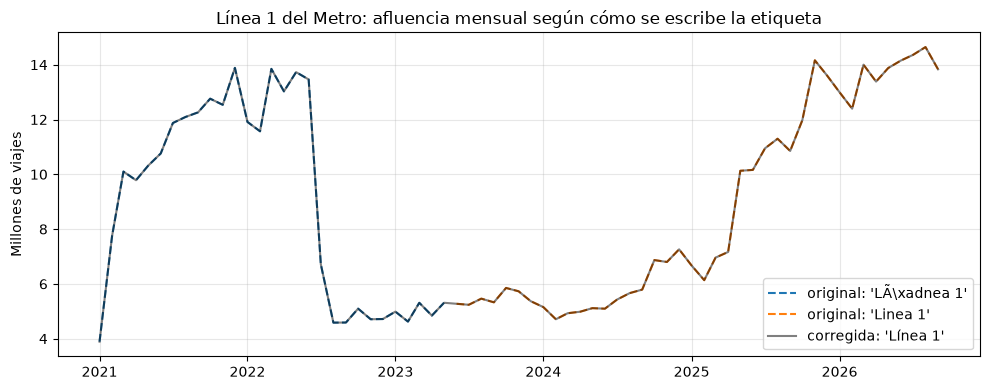

In [10]:
from pathlib import Path
(DATA_DIR.parent / "resultados" / "figuras").mkdir(parents=True, exist_ok=True)
# Consecuencia: serie mensual de la Línea 1 con las etiquetas originales vs. corregidas
# Leemos las etiquetas tal como vienen en el archivo, porque en la sección 1 ya se corrigieron
original = pd.read_csv(DATA_DIR / "Afluencia Diaria del Metro (Desglosada).csv", usecols=["fecha", "linea", "afluencia"])
original = original.assign(mes_ = pd.to_datetime(original["fecha"]).dt.to_period("M"))
corregida = Afluencia_Metro.assign(mes_ = pd.to_datetime(Afluencia_Metro["fecha"]).dt.to_period("M"))

fig, ax = plt.subplots(figsize=(10, 4))
etiquetas_l1 = [e for e in original["linea"].unique() if clave_sin_acentos(reparar_mojibake(e)) == "linea 1"]
for e in etiquetas_l1:
    s = original[original["linea"] == e].groupby("mes_")["afluencia"].sum() / 1e6
    ax.plot(s.index.to_timestamp(), s.values, "--", label=f"original: {e!r}")
s = corregida[corregida["linea"] == "Línea 1"].groupby("mes_")["afluencia"].sum() / 1e6
ax.plot(s.index.to_timestamp(), s.values, color="black", lw=1.5, alpha=.5, label="corregida: 'Línea 1'")
ax.set_title("Línea 1 del Metro: afluencia mensual según cómo se escribe la etiqueta")
ax.set_ylabel("Millones de viajes"); ax.legend(); ax.grid(alpha=.3)
fig.tight_layout(); fig.savefig(DATA_DIR.parent / "resultados" / "figuras" / "D1_etiquetas_linea1.png", dpi=150); plt.show()

**Consecuencia de la corrección (D1).** Con las etiquetas originales, la Línea 1 aparece como dos series distintas: `LÃ­nea 1` hasta mayo de 2023 y `Linea 1` desde junio de 2023. Cualquier agrupación por línea mostraría una caída falsa en mayo de 2023. Con la etiqueta corregida es una sola serie continua. Al unificar, el Metro pasa de 24 a 12 líneas y de 168 a 163 estaciones; el Metrobús, de 21 etiquetas a 7 líneas, y en ingresos `QR/Validador` y `QR/Validación` quedan como un solo concepto.

A este tipo de texto corrupto se le llama *mojibake*: ocurre cuando un texto guardado en UTF-8 se lee como si fuera Latin-1, y cada letra acentuada se convierte en dos símbolos (`í` → `Ã­`). Como los caracteres ya venían corruptos desde la fuente, cambiar el `encoding` al leer no los corrige; la función `reparar_mojibake` revierte el proceso con `texto.encode("latin-1").decode("utf-8")`.

**Observación sobre el número de estaciones**

Resultaron **163 nombres de estaciones distintos**. Sin embargo, este número no necesariamente corresponde al total de estaciones por línea, debido a que algunas estaciones de correspondencia comparten el mismo nombre, aunque pertenecen a diferentes líneas del Metro.

Por lo tanto, **será necesario distinguir entre nombres únicos de estaciones y combinaciones de estación-línea** en los análisis posteriores, especialmente al realizar comparaciones de afluencia, para evitar interpretaciones incorrectas de los resultados.

In [11]:
# Función para revisar la estructura y calidad inicial de los datos
def limpieza(df, llave=None):
    filas = []

    # Obtener el tipo de dato, valores faltantes y valores únicos por variable
    for col in df.columns:
        s = df[col]
        filas.append({
            "variable": col,
            "tipo": str(s.dtype),
            "n_faltantes": int(s.isna().sum()),
            "pct_faltantes": round(100 * s.isna().mean(), 2),
            "n_unicos": int(s.nunique(dropna=True)),
        })

    res = pd.DataFrame(filas)

    # Identificar registros duplicados y, cuando corresponda, duplicados por llave
    print(f"Duplicados exactos: {df.duplicated().sum():,}", end="")
    if llave:
        print(f" | duplicados en la llave {llave}: {df.duplicated(llave).sum():,}")
    else:
        print()

    return res

# Aplicar la revisión inicial a las principales bases de datos
print("METRO");    display(limpieza(Afluencia_Metro, ["fecha", "linea", "estacion", "tipo_pago"]))
print("METROBÚS"); display(limpieza(Afluencia_Metrobus, ["fecha", "linea", "tipo_pago"]))
print("INGRESOS"); display(limpieza(Ingresos_SCTM, ["fecha", "linea", "tipo_ingreso"]))
print("TP_HISTORICO"); display(limpieza(Afluencia_TP_historico, ["fecha", "organismo", "linea_servicio"]))
print("ECOBICI");  display(limpieza(Viajes_Ecobici_202601))


METRO
Duplicados exactos: 0 | duplicados en la llave ['fecha', 'linea', 'estacion', 'tipo_pago']: 0


,variable,tipo,n_faltantes,pct_faltantes,n_unicos
0,fecha,datetime64[us],0,0.0,2099
1,mes,str,0,0.0,12
2,anio,int64,0,0.0,6
3,linea,str,0,0.0,12
4,estacion,str,0,0.0,163
5,tipo_pago,str,0,0.0,3
6,afluencia,int64,0,0.0,48199


METROBÚS
Duplicados exactos: 0 | duplicados en la llave ['fecha', 'linea', 'tipo_pago']: 0


,variable,tipo,n_faltantes,pct_faltantes,n_unicos
0,fecha,datetime64[us],0,0.0,2099
1,mes,str,0,0.0,12
2,anio,int64,0,0.0,6
3,linea,str,0,0.0,7
4,tipo_pago,str,0,0.0,2
5,afluencia,float64,0,0.0,25257


INGRESOS
Duplicados exactos: 11 | duplicados en la llave ['fecha', 'linea', 'tipo_ingreso']: 12


,variable,tipo,n_faltantes,pct_faltantes,n_unicos
0,fecha,datetime64[us],0,0.00,4230
1,tipo_ingreso,str,0,0.00,4
2,linea,str,0,0.00,12
3,ingreso,float64,1067,0.67,88998


TP_HISTORICO
Duplicados exactos: 0 | duplicados en la llave ['fecha', 'organismo', 'linea_servicio']: 0


,variable,tipo,n_faltantes,pct_faltantes,n_unicos
0,id,int64,0,0.00,18714
1,organismo,str,0,0.00,8
2,linea_servicio,str,489,2.61,39
3,dia,str,0,0.00,8
4,fecha,datetime64[us],0,0.00,489
5,afluencia_tarjeta,Int64,16027,85.64,1352
6,afluencia_boleto,Int64,15116,80.77,2823
7,afluencia_total_preliminar,Int64,202,1.08,16077


ECOBICI
Duplicados exactos: 0


,variable,tipo,n_faltantes,pct_faltantes,n_unicos
0,Genero_Usuario,str,1,0.00,4
1,Edad_Usuario,float64,79,0.01,75
2,Bici,int64,0,0.00,7391
3,Ciclo_Estacion_Retiro,string,0,0.00,677
4,Fecha_Retiro,datetime64[us],0,0.00,42
5,Hora_Retiro,str,0,0.00,69706
6,Ciclo_EstacionArribo,string,0,0.00,677
7,Fecha_Arribo,datetime64[us],0,0.00,31
8,Hora_Arribo,str,0,0.00,70772


El análisis preliminar de calidad de los datos permitió evaluar la presencia de **valores faltantes y registros duplicados** en las cinco bases de datos consideradas para el estudio de la movilidad urbana de la Ciudad de México.

En términos generales, encontramos que las bases presentan una **baja incidencia de duplicados y, en la mayoría de los casos, una proporción reducida de valores faltantes**. Sin embargo, identificamos algunas particularidades que deberán considerarse durante las siguientes etapas del análisis.

**1. Afluencia del Metro y Metrobús**

Ambas bases presentan una estructura consistente, sin valores faltantes ni registros duplicados, tanto al considerar filas completas como al evaluar las llaves definidas para cada conjunto de datos.

Estos resultados sugieren una adecuada integridad de los registros disponibles. No obstante, será necesario examinar posteriormente la presencia de **afluencias iguales a cero y valores atípicos**, ya que la ausencia de datos nulos o duplicados no garantiza por sí misma la consistencia de las mediciones.

**2. Ingresos del Sistema de Transporte Colectivo Metro**

Identificamos **11 registros duplicados exactos y 12 duplicados considerando la llave compuesta por fecha, línea y tipo de ingreso**. Asimismo, la variable `ingreso` presenta **1,067 valores faltantes, equivalentes al 0.67 %** de los registros.

Aunque la proporción de información faltante es relativamente baja, será importante revisar los registros duplicados para determinar si corresponden a errores de captura o a observaciones que requieren una identificación adicional.

De igual manera, será necesario estudiar la distribución temporal y por línea de los valores faltantes, evitando realizar imputaciones o eliminaciones sin evaluar previamente su naturaleza.

**3. Afluencia histórica del transporte público**

Esta base presenta los problemas más importantes de información faltante. Destacan las variables `afluencia_tarjeta` y `afluencia_boleto`, con porcentajes de ausencia del **85.64 % y 80.77 %**, respectivamente.

En contraste, la variable `afluencia_total_preliminar` presenta únicamente **202 valores faltantes (1.08 %)**, mientras que `linea_servicio` registra **489 valores faltantes (2.61 %)** (estos ya podemos concluir con la información presentada mas arriba que se trata del servicio de ECOBICI que no cuenta con líneas, por lo que no se trata de un error).

Aunque no identificamos registros duplicados, los porcentajes elevados de ausencia en las variables de afluencia por modalidad de pago sugieren que será necesario revisar su disponibilidad y pertinencia para el análisis.

En particular, no debemos asumir que los valores faltantes representan afluencias iguales a cero, ni que necesariamente corresponden a errores de captura. Podrían estar relacionados con diferencias en los mecanismos de registro de los distintos organismos de transporte.

**4. Viajes del sistema Ecobici**

La base de Ecobici no presenta registros duplicados exactos y muestra una proporción muy reducida de valores faltantes.

Únicamente identificamos **1 valor faltante en `Genero_Usuario` y 79 en `Edad_Usuario`**, lo que representa una afectación mínima respecto al volumen total de información.

No obstante, debido a que cada registro representa un viaje individual, será importante revisar posteriormente la consistencia entre las fechas y horas de retiro y arribo, así como identificar posibles duraciones negativas, nulas o extraordinariamente elevadas.

**Conclusión general**

Los resultados indican que las bases de datos cuentan, en general, con condiciones favorables para continuar con el análisis exploratorio. Sin embargo, identificamos tres aspectos que requieren especial atención:

- **Registros duplicados:** principalmente en la base de ingresos del Metro.
- **Valores faltantes:** especialmente en las variables de afluencia por modalidad de pago de la base histórica.
- **Consistencia de las mediciones:** mediante la revisión de valores cero, valores atípicos y posibles inconsistencias temporales.

Por lo tanto, en las siguientes secciones se profundizará en la identificación y caracterización de estas situaciones, con el objetivo de distinguir entre posibles errores de registro, limitaciones en la disponibilidad de información y comportamientos reales de los sistemas de transporte.

# 2. Exploración y estadística descriptiva

## 2.1 Metro

Comenzamos a explorar la estadística de la base del Metro

In [12]:
# Calcular la afluencia diaria por línea del Metro
Metro_linea = (
    Afluencia_Metro
    .groupby(["fecha", "linea"], as_index=False)["afluencia"]
    .sum(min_count=1)
)

# Estadísticas descriptivas de la afluencia diaria
Estadisticas_Metro_linea = (
    Metro_linea
    .groupby("linea")["afluencia"]
    .describe(percentiles=[.01,.05,.25,.5,.75,.95,.99])
    .sort_values(by="mean", ascending=False)
)

print("Estadísticas de afluencia diaria por línea del Metro:")
display(Estadisticas_Metro_linea.head(20).round(2))

Estadísticas de afluencia diaria por línea del Metro:


,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
linea,,,,,,,,,,,,
Línea 2,2099.0,506059.22,152328.90,0.0,0.00,245345.1,378634.0,553120.0,622214.5,691388.2,744021.24,807078.0
Línea 3,2099.0,436568.17,137328.37,0.0,0.00,213370.9,333312.5,469612.0,553405.0,606107.3,633608.08,676891.0
Línea B,2099.0,324906.76,73489.17,87222.0,141572.16,202515.9,258271.5,346372.0,383224.0,412837.9,437869.14,479635.0
Línea 8,2099.0,312426.03,79632.96,59141.0,112936.94,175800.8,247086.0,336828.0,374997.5,409265.2,430480.76,453005.0
Línea 1,2099.0,290991.42,132502.82,0.0,72222.16,115650.2,179575.0,247748.0,414277.5,501232.8,530545.92,595085.0
Línea 9,2099.0,231995.40,66709.13,34438.0,79455.04,107069.1,181091.0,242935.0,287129.0,318571.6,336272.70,376384.0
Línea 7,2099.0,208152.27,71777.04,30220.0,58045.60,93396.7,152563.0,216958.0,273955.0,302928.8,314654.98,353547.0
Línea A,2099.0,196087.27,49543.79,57590.0,82908.54,110599.8,159504.5,206580.0,236057.5,262184.9,276752.20,302148.0
Línea 12,2099.0,181491.69,150015.68,0.0,0.00,0.0,0.0,175269.0,341014.5,398143.4,415275.60,471854.0


In [13]:
# Identificar las fechas con afluencia cero por línea
Metro_linea_ceros = (Metro_linea[Metro_linea["afluencia"] == 0].copy())

# Identificar el año y mes de cada fecha
Metro_linea_ceros["mes"] = (Metro_linea_ceros["fecha"].dt.to_period("M"))

# Contar los días con afluencia cero por línea y mes
Resumen_ceros_Metro = (
    Metro_linea_ceros
    .groupby(["linea", "mes"])
    .size()
    .reset_index(name="dias_cero")
    .sort_values(
        by=["linea", "mes"],
        ascending=[True, True]
    )
)

Tabla_ceros_Metro = (
    Resumen_ceros_Metro
    .pivot(
        index="mes",
        columns="linea",
        values="dias_cero"
    )
    .fillna(0)
    .astype(int)
)

print("Distribución de los días con afluencia cero:")
display(Tabla_ceros_Metro)

Distribución de los días con afluencia cero:


linea,Línea 1,Línea 12,Línea 2,Línea 3,Línea 4,Línea 5,Línea 6
mes,,,,,,,
2021-01,16,0,23,23,3,3,3
2021-02,0,0,7,0,0,0,0
2021-05,0,28,0,0,0,0,0
2021-06,0,30,0,0,0,0,0
2021-07,0,31,0,0,0,0,0
2021-08,0,31,0,0,0,0,0
2021-09,0,30,0,0,0,0,0
2021-10,0,31,0,0,0,0,0
2021-11,0,30,0,0,0,0,0


In [14]:
# Calcular la afluencia diaria por línea del Metro
Metro_estacion = (
    Afluencia_Metro#[Afluencia_Metro["fecha"] >= '2023-02-01']
    .groupby(["fecha", "estacion", "linea"], as_index=False)["afluencia"]
    .sum(min_count=1)
)

# Estadísticas descriptivas de la afluencia diaria
Estadisticas_Metro_estacion = (
    Metro_estacion
    .groupby(["estacion", "linea"])["afluencia"]
    .describe(percentiles=[.01,.05,.25,.5,.75,.95,.99])
    .sort_values(by="mean", ascending=False)
)


display(Estadisticas_Metro_estacion.round(2))

,,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
estacion,linea,,,,,,,,,,,,
Constitución de 1917,Línea 8,2099.0,85317.58,26193.93,16209.0,27217.72,40280.2,62174.5,91727.0,106368.5,118387.7,129372.20,139988.0
Indios Verdes,Línea 3,2099.0,81011.40,20551.46,0.0,0.00,43791.2,69926.0,85312.0,97037.5,105250.1,109136.00,119489.0
Cuatro Caminos,Línea 2,2099.0,69750.70,28301.18,0.0,0.00,25168.3,50691.5,63162.0,97873.5,111705.1,118782.38,133127.0
Tasqueña,Línea 2,2099.0,50365.31,15148.60,0.0,0.00,23775.4,41254.0,53227.0,61618.5,70270.5,75253.24,87549.0
Tacubaya,Línea 9,2099.0,47414.86,16365.16,3388.0,11987.84,19501.2,34667.5,49072.0,61669.0,70487.3,74907.72,82573.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
Consulado,Línea 4,2099.0,2917.29,764.52,0.0,1095.98,1596.7,2345.0,3070.0,3445.0,3890.0,4765.06,5926.0
Instituto del Petróleo,Línea 6,2099.0,2358.87,1036.20,0.0,430.86,762.8,1456.5,2684.0,3309.5,3669.3,3891.00,4490.0
Tlaltenco,Línea 12,2099.0,2192.10,2237.84,0.0,0.00,0.0,0.0,2258.0,4493.0,5440.2,5940.24,6736.0


In [15]:
# Identificar los días con afluencia igual a cero
Metro_estacion_ceros = Metro_estacion.assign(
    afluencia_cero=Metro_estacion["afluencia"].eq(0)
)

# Resumir los días con afluencia cero por estación y línea
Resumen_ceros_estacion = (
    Metro_estacion_ceros
    .groupby(["estacion", "linea"])
    .agg(
        dias_registrados=("afluencia", "count"),
        dias_cero=("afluencia_cero", "sum"),
        primera_fecha_cero=("fecha", lambda x: x[Metro_estacion_ceros.loc[x.index, "afluencia_cero"]].min()),
        ultima_fecha_cero=("fecha", lambda x: x[Metro_estacion_ceros.loc[x.index, "afluencia_cero"]].max())
    )
    .reset_index()
)

# Calcular el porcentaje de días con afluencia cero
Resumen_ceros_estacion["porcentaje_ceros"] = (
    Resumen_ceros_estacion["dias_cero"]
    / Resumen_ceros_estacion["dias_registrados"]
    * 100
)

# Ordenar las estaciones con mayor proporción de días sin afluencia
Resumen_ceros_estacion = Resumen_ceros_estacion.sort_values(
    by=["porcentaje_ceros", "dias_cero"],
    ascending=False
)

# Mostrar todas las filas y columnas de la tabla
display(Resumen_ceros_estacion[Resumen_ceros_estacion["dias_cero"] > 0].round(2))

C:\Users\jgallegos\AppData\Local\Temp\ipykernel_13544\1789393697.py:33: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(Resumen_ceros_estacion[Resumen_ceros_estacion["dias_cero"] > 0].round(2))


,estacion,linea,dias_registrados,dias_cero,primera_fecha_cero,ultima_fecha_cero,porcentaje_ceros
176,Tlaltenco,Línea 12,2099,1000,2021-05-04,2026-09-13,47.64
192,Zapotitlán,Línea 12,2099,999,2021-05-04,2026-09-13,47.59
117,Nopalera,Línea 12,2099,998,2021-05-04,2026-09-13,47.55
124,Olivos,Línea 12,2099,997,2021-05-04,2026-09-13,47.50
174,Tezonco,Línea 12,2099,995,2021-05-04,2026-09-13,47.40
...,...,...,...,...,...,...,...
123,Oceanía,Línea B,2099,2,2026-01-10,2026-01-11,0.10
146,Ricardo Flores Magón,Línea B,2099,2,2026-01-10,2026-01-11,0.10
147,Romero Rubio,Línea B,2099,2,2026-01-10,2026-01-11,0.10
158,San Lázaro,Línea B,2099,2,2026-01-10,2026-01-11,0.10


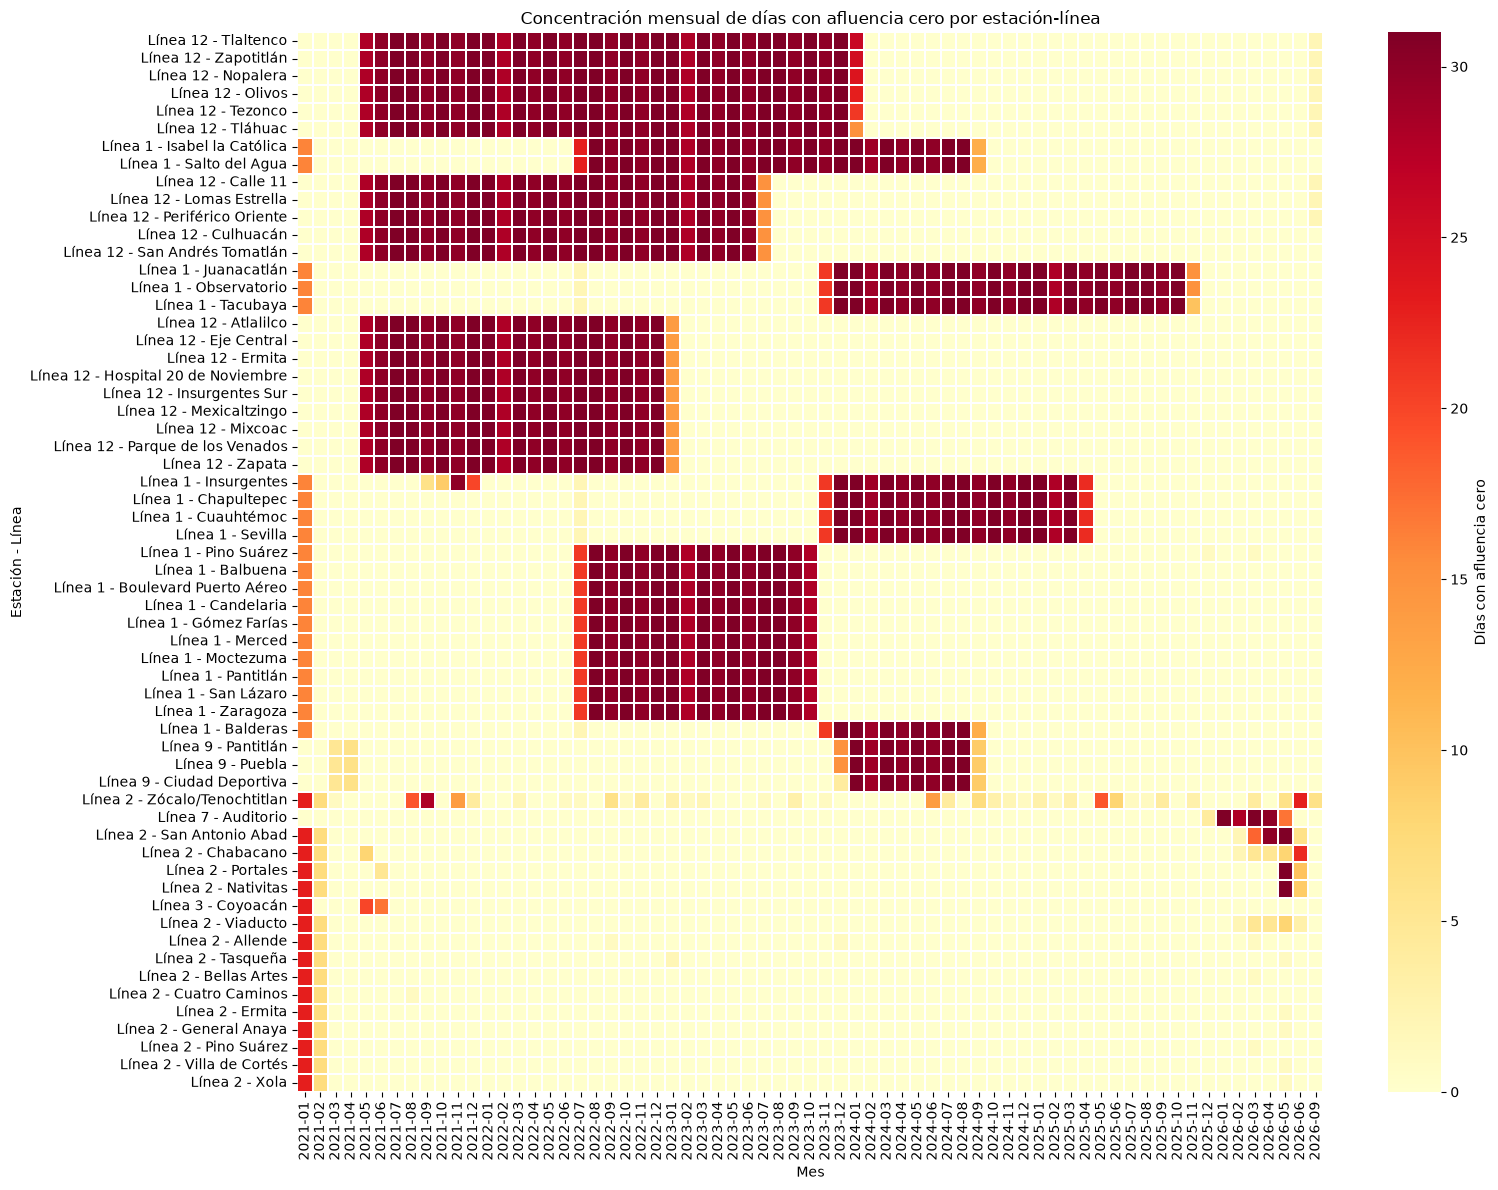

In [16]:

# Filtrar los registros con afluencia cero y obtener el mes
Metro_ceros = (
    Metro_estacion[Metro_estacion["afluencia"] == 0]
    .assign(mes=lambda x: x["fecha"].dt.to_period("M"))
)

# Identificar las 41 estaciones-línea con más días cero
Top_estaciones = (
    Metro_ceros.groupby(["linea", "estacion"])
    .size()
    .nlargest(60)
    .index
)

# Construir la matriz mensual y ordenar por días cero
Matriz_ceros = (
    Metro_ceros
    .groupby(["linea", "estacion", "mes"])
    .size()
    .unstack(fill_value=0)
    .reindex(Top_estaciones)
)

Matriz_ceros.index = [
    f"{linea} - {estacion}" for linea, estacion in Matriz_ceros.index
]
Matriz_ceros.columns = Matriz_ceros.columns.astype(str)

# Graficar la concentración mensual de días cero
plt.figure(figsize=(16, 12))

sns.heatmap(
    Matriz_ceros,
    cmap="YlOrRd",
    linewidths=0.3,
    cbar_kws={"label": "Días con afluencia cero"}
)

plt.title("Concentración mensual de días con afluencia cero por estación-línea")
plt.xlabel("Mes")
plt.ylabel("Estación - Línea")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()



**Análisis de los días con afluencia cero durante el periodo completo**

El mapa de calor permite observar que **los registros de afluencia cero no se distribuyen de manera aleatoria**, sino que se concentran principalmente en periodos prolongados y en grupos de estaciones pertenecientes a una misma línea.

Las principales observaciones son:

- **Línea 12:** presenta la mayor concentración de días con afluencia cero. Destacan Tlaltenco, Zapotitlán, Nopalera, Olivos, Tezonco y Tláhuac, con entre 989 y 1,000 días, equivalentes aproximadamente al 47 % de los registros de cada estación. Asimismo, otras estaciones presentan entre 621 y 805 días con afluencia nula. El mapa de calor muestra concentraciones prolongadas que comienzan en mayo de 2021 y disminuyen progresivamente durante 2023 y principios de 2024.

- **Línea 1:** también presenta periodos prolongados de afluencia nula. Isabel la Católica y Salto del Agua registran 813 días (38.73 %), mientras que Juanacatlán y Observatorio acumulan 755 días (35.97 %). A diferencia de la Línea 12, se identifican distintos periodos de concentración, principalmente entre 2022 y 2025, con patrones compartidos por grupos de estaciones.

- **Línea 9:** Pantitlán y Puebla registran 279 días con afluencia cero (13.29 %), mientras que Ciudad Deportiva presenta 268 días (12.77 %). La mayor concentración se observa entre finales de 2023 y septiembre de 2024.

- **Otras líneas:** presentan, en general, concentraciones menores. Sin embargo, destacan casos particulares, como Zócalo/Tenochtitlan de la Línea 2, con 235 días (11.20 %), y Auditorio de la Línea 7, con 141 días (6.72 %). También se identifican periodos de afluencia cero durante enero de 2021 en distintas líneas.

**Implicaciones estadísticas**

La presencia de cierres prolongados tiene consecuencias importantes sobre la interpretación de las estadísticas descriptivas.

En particular, **incluir los días de cierre en el cálculo de la afluencia diaria promedio reduce el valor de esta medida**, debido a que durante dichos periodos las estaciones no estuvieron disponibles para prestar servicio.

Por lo tanto, una estación con un promedio histórico reducido no necesariamente presenta una menor utilización durante su operación, sino que podría haber permanecido cerrada durante una proporción considerable del periodo estudiado.

De igual manera, los percentiles y otras medidas descriptivas pueden verse afectados por la acumulación de registros con valor cero.

**Conclusión y tratamiento metodológico**

Considerando que **los valores de afluencia cero corresponden a cierres oficiales**, decidimos conservar el periodo histórico completo, evitando eliminar años o intervalos de manera generalizada.

Sin embargo, para garantizar comparaciones adecuadas entre estaciones y líneas, será necesario distinguir entre:

1. **Afluencia histórica:** considera todos los días registrados, incluidos aquellos en los que las estaciones permanecieron cerradas.

2. **Afluencia durante la operación:** considera únicamente los días en que las estaciones estuvieron abiertas, excluyendo los cierres.

3. **Disponibilidad operativa:** representa la proporción de días en los que cada estación estuvo en funcionamiento durante el periodo analizado.

Por lo tanto, **utilizaremos la afluencia durante los días de operación para comparar la intensidad de uso entre estaciones**, mientras que conservaremos la afluencia histórica para analizar la evolución de la movilidad y el impacto de los cierres sobre el sistema.

Este tratamiento permitirá aprovechar toda la información disponible sin confundir una menor afluencia asociada con cierres operativos con una menor utilización de las estaciones durante su funcionamiento.

**Valores atípicos: criterio del rango intercuartílico (IQR)**

El análisis de la afluencia a nivel de línea y estación podría ocultar diferencias importantes en los patrones de movilidad según el día de la semana. Por ello, para identificar valores atípicos mediante el criterio del **rango intercuartílico (IQR)**, decidimos incrementar la granularidad del análisis, considerando cada combinación de **línea, estación y día de la semana** de manera independiente.

Asimismo, para calcular los cuartiles y establecer los límites de identificación de valores atípicos, excluimos los registros con afluencia igual a cero, dado que corresponden a **cierres de las estaciones**. Esta decisión permite evitar que los periodos sin operación distorsionen la distribución de la afluencia y, en consecuencia, los límites utilizados para identificar observaciones atípicas durante los días de funcionamiento.

Para cada combinación de línea, estación y día de la semana, calculamos el rango intercuartílico como:

$$
IQR = Q_3 - Q_1
$$

Posteriormente, establecimos los siguientes límites:

$$
L_{\text{inferior}} = Q_1 - 1.5 \times IQR
$$

$$
L_{\text{superior}} = Q_3 + 1.5 \times IQR
$$

De esta manera, consideramos como **valores potencialmente atípicos** aquellas observaciones cuya afluencia se encuentra fuera de estos límites.

Es importante señalar que la identificación de un valor atípico no implica necesariamente un error en los datos, ya que podría corresponder a eventos extraordinarios, días festivos o variaciones reales en la demanda del transporte.

In [17]:
# Calcular la afluencia diaria por estación y línea, excluyendo cierres
Metro_dia = (
    Afluencia_Metro
    .groupby(["fecha", "estacion", "linea"], as_index=False)["afluencia"]
    .sum(min_count=1)
    .query("afluencia > 0")
    .assign(dia_semana=lambda x: x["fecha"].dt.dayofweek)
)

# Agrupar por estación, línea y día de la semana
grupo = Metro_dia.groupby(["estacion", "linea", "dia_semana"])["afluencia"]

# Calcular estadísticas descriptivas y rango intercuartílico
Estadisticas_Metro_dia = (
    grupo.describe(percentiles=[.01, .05, .25, .5, .75, .95, .99])
    .assign(
        RIC=lambda x: x["75%"] - x["25%"],
        asimetria=grupo.skew()
    )
    .rename(columns={
        "count": "n",
        "mean": "media",
        "std": "desv_std_muestral",
        "50%": "mediana"
    })
    .rename(
        index=dict(enumerate([
            "Lunes", "Martes", "Miércoles", "Jueves",
            "Viernes", "Sábado", "Domingo"
        ])),
        level="dia_semana"
    )
)

print("Estadísticas de afluencia por estación, línea y día de la semana:")
display(Estadisticas_Metro_dia.round(2))

C:\Users\jgallegos\AppData\Local\Temp\ipykernel_13544\3124142132.py:7: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  .assign(dia_semana=lambda x: x["fecha"].dt.dayofweek)


Estadísticas de afluencia por estación, línea y día de la semana:


n     media  desv_std_muestral  \
estacion            linea   dia_semana                                       
Acatitla            Línea A Lunes       300.0  13549.09            2678.79   
                            Martes      300.0  13973.18            2621.53   
                            Miércoles   300.0  17000.23            4556.49   
                            Jueves      299.0  14067.36            2688.87   
                            Viernes     300.0  14377.14            2694.25   
...                                       ...       ...                ...   
Zócalo/Tenochtitlan Línea 2 Miércoles   270.0  39195.22           13426.01   
                            Jueves      269.0  39481.63           12956.08   
                            Viernes     266.0  41186.17           15033.14   
                            Sábado      259.0  45174.05           17144.27   
                            Domingo     263.0  29450.48           13406.97   

                                           min       1%        5%       25%  \
estacion            linea   dia_semana                                        
Acatitla            Línea A Lunes       6360.0  6676.51   8220.65  12424.50   
                            Martes      5916.0  6844.87   8760.05  12742.50   
                            Miércoles   3646.0  4982.35   6675.55  16899.25   
                            Jueves      3931.0  6491.18   8854.40  12978.50   
                            Viernes     5126.0  6722.22   9373.85  13121.50   
...                                        ...      ...       ...       ...   
Zócalo/Tenochtitlan Línea 2 Miércoles    397.0   711.87  15785.30  31305.00   
                            Jueves         6.0  1902.92  18388.20  31790.00   
                            Viernes        1.0   150.30  14132.00  33767.50   
                            Sábado         2.0   106.94  13909.20  35356.50   
                            Domingo        6.0  1208.18   7794.80  20794.50   

                                        mediana       75%       95%       99%  \
estacion            linea   dia_semana                                          
Acatitla            Línea A Lunes       13994.5  15072.00  17284.80  19218.45   
                            Martes      14282.0  15418.00  17783.20  19508.30   
                            Miércoles   18235.5  19436.25  22057.15  24082.31   
                            Jueves      14355.0  15697.00  17782.70  19365.26   
                            Viernes     14748.5  16097.25  18461.35  19871.69   
...                                         ...       ...       ...       ...   
Zócalo/Tenochtitlan Línea 2 Miércoles   40045.0  49067.75  57908.70  62329.55   
                            Jueves      40240.0  49093.00  57540.40  67179.12   
                            Viernes     42144.0  51883.50  62566.25  70301.45   
                            Sábado      45923.0  56862.50  71640.10  76305.22   
                            Domingo     28397.0  38197.00  50972.20  63791.34   

                                            max       RIC  asimetria  
estacion            linea   dia_semana                                
Acatitla            Línea A Lunes       21643.0   2647.50      -0.54  
                            Martes      24207.0   2675.50      -0.37  
                            Miércoles   24301.0   2537.00      -1.42  
                            Jueves      22307.0   2718.50      -0.73  
                            Viernes     20967.0   2975.75      -0.78  
...                                         ...       ...        ...  
Zócalo/Tenochtitlan Línea 2 Miércoles   72204.0  17762.75      -0.61  
                            Jueves      78929.0  17303.00      -0.34  
                            Viernes     73787.0  18116.00      -0.57  
                            Sábado      81334.0  21506.00      -0.49  
                            Domingo     73143.0  17402.50       0.21  

[1365 rows x 14 columns

In [18]:
# 1. Calcular los límites IQR por estación, línea y día de la semana
Limites_IQR = (
    Estadisticas_Metro_dia
    .assign(
        limite_inferior=lambda x: x["25%"] - 1.5 * x["RIC"],
        limite_superior=lambda x: x["75%"] + 1.5 * x["RIC"]
    )[["RIC", "limite_inferior", "limite_superior"]]
    .rename(
        index=dict(zip(
            ["Lunes", "Martes", "Miércoles", "Jueves",
             "Viernes", "Sábado", "Domingo"], range(7)
        )),
        level="dia_semana"
    )
)

# 2. Calcular la afluencia diaria y agregar los límites
Metro_diario = (
    Afluencia_Metro
    .groupby(["fecha", "estacion", "linea"], as_index=False)["afluencia"]
    .sum(min_count=1)
    .rename(columns={"afluencia": "afluencia_diaria"})
    .assign(dia_semana=lambda x: x["fecha"].dt.dayofweek)
    .join(Limites_IQR, on=["estacion", "linea", "dia_semana"])
)

# 3. Identificar y clasificar valores atípicos
inferior = (
    (Metro_diario["afluencia_diaria"] > 0) &
    (Metro_diario["afluencia_diaria"] < Metro_diario["limite_inferior"])
)
superior = (
    (Metro_diario["afluencia_diaria"] > 0) &
    (Metro_diario["afluencia_diaria"] > Metro_diario["limite_superior"])
)

Metro_diario["tipo_atipico"] = "No atípico"
Metro_diario.loc[inferior, "tipo_atipico"] = "Inferior"
Metro_diario.loc[superior, "tipo_atipico"] = "Superior"
Metro_diario.loc[Metro_diario["afluencia_diaria"].eq(0), "tipo_atipico"] = "Cierre"
Metro_diario["atipico"] = inferior | superior

# 4. Incorporar los resultados a la tabla original
Metro_IQR = Afluencia_Metro.merge(
    Metro_diario,
    on=["fecha", "estacion", "linea"],
    how="left",
    validate="many_to_one"
)

assert len(Metro_IQR) == len(Afluencia_Metro)

print("Tabla original con identificación de valores atípicos:")
display(Metro_IQR.head(10).round(2))

# 5. Conteo y porcentaje de valores atípicos
Registros_operativos = Metro_diario["afluencia_diaria"].gt(0).sum()
Total_atipicos = Metro_diario["atipico"].sum()

print("Registros diarios operativos:", Registros_operativos)
print("Registros diarios atípicos:", Total_atipicos)
print("Porcentaje de atípicos:",
      round(100 * Total_atipicos / Registros_operativos, 2), "%")

# 6. Concentración de atípicos por línea
Resumen_atipicos_linea = (
    Metro_diario.groupby("linea")
    .agg(
        registros_operativos=("afluencia_diaria", lambda x: x.gt(0).sum()),
        registros_atipicos=("atipico", "sum")
    )
    .assign(porcentaje_atipicos=lambda x:
            100 * x["registros_atipicos"] / x["registros_operativos"])
    .sort_values("registros_atipicos", ascending=False)
)

print("Concentración de valores atípicos por línea:")
display(Resumen_atipicos_linea.round(2))

# 7. Fechas con mayor concentración de atípicos
Resumen_atipicos_fecha = (
    Metro_diario[Metro_diario["atipico"]]
    .groupby("fecha").size()
    .sort_values(ascending=False)
    .to_frame("estaciones_atipicas")
)

print("Fechas con mayor concentración de valores atípicos:")
display(Resumen_atipicos_fecha.head(10))
#with pd.option_context("display.max_rows", None):
#    display(Resumen_atipicos_fecha)

# 8. Resumen de atípicos por año y tipo
Resumen_atipicos_anio = (
    Metro_diario[Metro_diario["atipico"]]
    .assign(anio=lambda x: x["fecha"].dt.year)
    .groupby(["anio", "tipo_atipico"])
    .size().unstack(fill_value=0)
)

print("Valores atípicos por año y tipo:")
display(Resumen_atipicos_anio)

C:\Users\jgallegos\AppData\Local\Temp\ipykernel_13544\150659338.py:23: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  .assign(dia_semana=lambda x: x["fecha"].dt.dayofweek)


Tabla original con identificación de valores atípicos:


C:\Users\jgallegos\AppData\Local\Temp\ipykernel_13544\150659338.py:54: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(Metro_IQR.head(10).round(2))


,fecha,mes,anio,linea,estacion,tipo_pago,afluencia,afluencia_diaria,dia_semana,RIC,limite_inferior,limite_superior,tipo_atipico,atipico
0,2021-01-01,Enero,2021,Línea 1,Balbuena,Boleto,1848,2963,4,2610.00,2460.25,12900.25,No atípico,False
1,2021-01-01,Enero,2021,Línea 1,Balbuena,Prepago,790,2963,4,2610.00,2460.25,12900.25,No atípico,False
2,2021-01-01,Enero,2021,Línea 1,Balbuena,Gratuidad,325,2963,4,2610.00,2460.25,12900.25,No atípico,False
3,2021-01-01,Enero,2021,Línea 1,Balderas,Boleto,1103,2676,4,9957.25,-771.12,39057.88,No atípico,False
4,2021-01-01,Enero,2021,Línea 1,Balderas,Prepago,922,2676,4,9957.25,-771.12,39057.88,No atípico,False
5,2021-01-01,Enero,2021,Línea 1,Balderas,Gratuidad,651,2676,4,9957.25,-771.12,39057.88,No atípico,False
6,2021-01-01,Enero,2021,Línea 1,Boulevard Puerto Aéreo,Boleto,4890,8740,4,4622.50,7147.50,25637.50,No atípico,False
7,2021-01-01,Enero,2021,Línea 1,Boulevard Puerto Aéreo,Prepago,2797,8740,4,4622.50,7147.50,25637.50,No atípico,False
8,2021-01-01,Enero,2021,Línea 1,Boulevard Puerto Aéreo,Gratuidad,1053,8740,4,4622.50,7147.50,25637.50,No atípico,False
9,2021-01-01,Enero,2021,Línea 1,Candelaria,Boleto,0,2732,4,4348.25,8944.62,26337.62,Inferior,True


Registros diarios operativos: 379541
Registros diarios atípicos: 14913
Porcentaje de atípicos: 3.93 %
Concentración de valores atípicos por línea:


,registros_operativos,registros_atipicos,porcentaje_atipicos
linea,,,
Línea 8,39880,2251,5.64
Línea B,44067,1915,4.35
Línea 3,43553,1447,3.32
Línea 4,20958,1421,6.78
Línea 12,26392,1296,4.91
Línea 6,23055,1198,5.20
Línea 2,49192,1175,2.39
Línea 9,24362,1152,4.73
Línea 5,27248,941,3.45


Fechas con mayor concentración de valores atípicos:


,estaciones_atipicas
fecha,
2021-01-01,162
2026-01-01,143
2025-01-01,143
2024-12-25,140
2025-12-25,136
2021-04-03,127
2022-01-01,126
2021-01-02,123
2021-12-25,122


Valores atípicos por año y tipo:


tipo_atipico,Inferior,Superior
anio,,
2021,6474,459
2022,695,1260
2023,584,1586
2024,870,611
2025,818,662
2026,602,292


In [19]:
# Convertir los números de día de la semana a sus nombres
dias = ["Lunes", "Martes", "Miércoles", "Jueves",
        "Viernes", "Sábado", "Domingo"]

Metro_IQR["dia_semana"] = Metro_IQR["dia_semana"].map(dict(enumerate(dias)))

display(Metro_IQR.head(10).round(2))

C:\Users\jgallegos\AppData\Local\Temp\ipykernel_13544\280298618.py:7: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(Metro_IQR.head(10).round(2))


,fecha,mes,anio,linea,estacion,tipo_pago,afluencia,afluencia_diaria,dia_semana,RIC,limite_inferior,limite_superior,tipo_atipico,atipico
0,2021-01-01,Enero,2021,Línea 1,Balbuena,Boleto,1848,2963,Viernes,2610.00,2460.25,12900.25,No atípico,False
1,2021-01-01,Enero,2021,Línea 1,Balbuena,Prepago,790,2963,Viernes,2610.00,2460.25,12900.25,No atípico,False
2,2021-01-01,Enero,2021,Línea 1,Balbuena,Gratuidad,325,2963,Viernes,2610.00,2460.25,12900.25,No atípico,False
3,2021-01-01,Enero,2021,Línea 1,Balderas,Boleto,1103,2676,Viernes,9957.25,-771.12,39057.88,No atípico,False
4,2021-01-01,Enero,2021,Línea 1,Balderas,Prepago,922,2676,Viernes,9957.25,-771.12,39057.88,No atípico,False
5,2021-01-01,Enero,2021,Línea 1,Balderas,Gratuidad,651,2676,Viernes,9957.25,-771.12,39057.88,No atípico,False
6,2021-01-01,Enero,2021,Línea 1,Boulevard Puerto Aéreo,Boleto,4890,8740,Viernes,4622.50,7147.50,25637.50,No atípico,False
7,2021-01-01,Enero,2021,Línea 1,Boulevard Puerto Aéreo,Prepago,2797,8740,Viernes,4622.50,7147.50,25637.50,No atípico,False
8,2021-01-01,Enero,2021,Línea 1,Boulevard Puerto Aéreo,Gratuidad,1053,8740,Viernes,4622.50,7147.50,25637.50,No atípico,False
9,2021-01-01,Enero,2021,Línea 1,Candelaria,Boleto,0,2732,Viernes,4348.25,8944.62,26337.62,Inferior,True


El análisis de valores atípicos mediante el criterio del **rango intercuartílico (IQR)**, considerando la afluencia diaria por estación, línea y día de la semana, permitió identificar fechas en las que la demanda del Metro presentó comportamientos inusuales respecto a su distribución histórica.

Al examinar las fechas con mayor concentración de estaciones atípicas, observamos que una parte importante coincide con **días festivos oficiales, celebraciones no obligatorias y periodos vacacionales**. Entre los casos más representativos destacan:

- **Año Nuevo (1 de enero):** con hasta 162 estaciones atípicas.
- **Navidad (25 de diciembre):** con hasta 140 estaciones atípicas.
- **Día de la Independencia (16 de septiembre):** con hasta 115 estaciones atípicas.
- **Semana Santa:** particularmente el Viernes Santo y el Sábado de Gloria, con hasta 127 estaciones atípicas.
- **Otros días festivos:** como los descansos por el Día de la Constitución, el natalicio de Benito Juárez y el Día del Trabajo.

Estos resultados sugieren que las festividades y los periodos de descanso podrían estar asociados con modificaciones importantes en los patrones habituales de movilidad, debido a cambios en las actividades laborales, educativas, comerciales y recreativas.

Por otra parte, encontramos una **concentración considerable de fechas atípicas durante los primeros meses de 2021**, muchas de las cuales no corresponden a festividades nacionales. Este comportamiento podría estar relacionado con la emergencia sanitaria por COVID-19 y las restricciones de movilidad y actividad económica implementadas durante ese periodo.

La presencia recurrente de valores atípicos en estas fechas sugiere que el contexto sanitario pudo haber provocado modificaciones importantes en la demanda habitual del transporte, especialmente en comparación con los años posteriores.

Asimismo, identificamos fechas con concentraciones menores de valores atípicos que no coinciden necesariamente con festividades o restricciones sanitarias. Estas podrían estar relacionadas con eventos extraordinarios, modificaciones operativas o fluctuaciones particulares en la demanda de determinadas estaciones.

En conclusión, **los valores atípicos identificados no necesariamente representan errores en los datos**, sino que pueden reflejar variaciones reales en los patrones de movilidad de la Ciudad de México. Los resultados permiten identificar dos posibles factores asociados con los comportamientos más extremos: **las festividades y periodos de descanso, así como las condiciones extraordinarias derivadas de la pandemia de COVID-19**.

## 2.2 Metrobus

In [20]:
# Calcular la afluencia diaria por línea
Metrobus_dia = (
    Afluencia_Metrobus
    .groupby(["fecha", "linea"], as_index=False)["afluencia"]
    .sum(min_count=1)
    .assign(dia_semana=lambda x: x["fecha"].dt.dayofweek)
)

# Agrupar por línea y día de la semana
grupo = Metrobus_dia.groupby(["linea", "dia_semana"])["afluencia"]

# Calcular estadísticas descriptivas y rango intercuartílico
Estadisticas_Metrobus_dia = (
    grupo.describe(percentiles=[.01, .05, .25, .5, .75, .95, .99])
    .assign(
        RIC=lambda x: x["75%"] - x["25%"],
        asimetria=grupo.skew()
    )
    .rename(columns={
        "count": "n",
        "mean": "media",
        "std": "desv_std_muestral",
        "50%": "mediana"
    })
    .rename(
        index=dict(enumerate([
            "Lunes", "Martes", "Miércoles", "Jueves",
            "Viernes", "Sábado", "Domingo"
        ])),
        level="dia_semana"
    )
)

print("Estadísticas de afluencia por línea y día de la semana:")
display(Estadisticas_Metrobus_dia.round(2))


C:\Users\jgallegos\AppData\Local\Temp\ipykernel_13544\3883107769.py:6: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  .assign(dia_semana=lambda x: x["fecha"].dt.dayofweek)


Estadísticas de afluencia por línea y día de la semana:


n      media  desv_std_muestral       min         1%  \
linea   dia_semana                                                             
Línea 1 Lunes       300.0  387616.46           95190.58   99973.0  133704.50   
        Martes      300.0  420995.14           88749.72  163962.0  219470.66   
        Miércoles   300.0  426524.09           94199.03  105596.0  190257.29   
        Jueves      299.0  426656.23           99428.21  101035.0  169549.38   
        Viernes     300.0  430065.99           95974.72   42650.0  155471.35   
        Sábado      300.0  282328.31           61088.53   80808.0  121882.12   
        Domingo     300.0  183280.77           45407.80   70939.0   95424.47   
Línea 2 Lunes       300.0  192940.27           50593.28   64027.0   69066.17   
        Martes      300.0  203140.26           46712.93   88446.0  100977.86   
        Miércoles   300.0  202849.29           47743.27   58229.0   79459.50   
        Jueves      299.0  201460.66           49440.41   51382.0   81896.24   
        Viernes     300.0  201110.75           48569.42   26201.0   80218.91   
        Sábado      300.0  139891.75           29013.42   44817.0   69051.32   
        Domingo     300.0   93955.78           19531.68   41892.0   50673.87   
Línea 3 Lunes       300.0  156444.46           35339.90   55995.0   63429.90   
        Martes      300.0  166236.38           33333.50   68929.0   87081.07   
        Miércoles   300.0  167986.46           34758.91   59646.0   70528.18   
        Jueves      299.0  167746.49           36551.49   45579.0   65470.46   
        Viernes     300.0  170870.97           36089.63   20964.0   70943.91   
        Sábado      300.0  124967.67           25011.01   43300.0   65964.08   
        Domingo     300.0   89049.13           19978.12   34583.0   45509.32   
Línea 4 Lunes       300.0   88308.34           21752.01   17501.0   31064.59   
        Martes      300.0   90167.27           22368.45   12394.0   20868.23   
        Miércoles   300.0   91873.73           22399.19   20717.0   29094.54   
        Jueves      299.0   91900.94           23387.66   11796.0   18358.38   
        Viernes     300.0   95446.63           23884.95    7756.0   18744.13   
        Sábado      300.0   91670.91           21495.30   15734.0   26752.21   
        Domingo     300.0   48500.71           13203.82    9779.0   18091.27   
Línea 5 Lunes       300.0  227382.79           55603.63   77019.0   95182.34   
        Martes      300.0  237228.73           52917.33  101903.0  105824.74   
        Miércoles   300.0  238840.29           53789.37   86206.0   99390.45   
        Jueves      299.0  236621.15           55519.05   71898.0   91814.94   
        Viernes     300.0  238025.35           53325.89   35599.0   97034.22   
        Sábado      300.0  171811.48           31522.41   66471.0   74393.27   
        Domingo     300.0  132479.15           28602.70   56826.0   64326.40   
Línea 6 Lunes       300.0  172563.45           42036.23   62441.0   69715.29   
        Martes      300.0  182518.54           39062.68   74413.0   98704.58   
        Miércoles   300.0  182008.53           38904.32   62605.0   93629.30   
        Jueves      299.0  180795.15           40692.79   53064.0   82979.64   
        Viernes     300.0  179290.75           38260.11   29342.0   72269.63   
        Sábado      300.0  123878.91           22383.39   48189.0   66486.63   
        Domingo     300.0   91674.47           18648.57   45062.0   50343.38   
Línea 7 Lunes       300.0  128242.49           28508.34   44886.0   53378.07   
        Martes      300.0  136803.84           27877.19   47509.0   63127.09   
        Miércoles   300.0  137419.80           28600.07   45154.0   57648.51   
        Jueves      299.0  137756.40           28718.79   49777.0   55810.62   
        Viernes     300.0  139720.57           29705.25   21818.0   68517.88   
        Sábado      300.0  105414.95           22304.43   39760.0   52954.25   
        Domingo     300.

In [21]:
# 1. Calcular los límites IQR por línea y día de la semana
Limites_IQR_Metrobus = (
    Estadisticas_Metrobus_dia
    .assign(
        limite_inferior=lambda x: x["25%"] - 1.5 * x["RIC"],
        limite_superior=lambda x: x["75%"] + 1.5 * x["RIC"]
    )[["RIC", "limite_inferior", "limite_superior"]]
    .rename(
        index=dict(zip(
            ["Lunes", "Martes", "Miércoles", "Jueves",
             "Viernes", "Sábado", "Domingo"], range(7)
        )),
        level="dia_semana"
    )
)

# 2. Calcular la afluencia diaria y agregar los límites
Metrobus_diario = (
    Afluencia_Metrobus
    .groupby(["fecha", "linea"], as_index=False)["afluencia"]
    .sum(min_count=1)
    .rename(columns={"afluencia": "afluencia_diaria"})
    .assign(dia_semana=lambda x: x["fecha"].dt.dayofweek)
    .join(Limites_IQR_Metrobus, on=["linea", "dia_semana"])
)

# 3. Identificar y clasificar los valores atípicos
inferior = (
    (Metrobus_diario["afluencia_diaria"] > 0) &
    (Metrobus_diario["afluencia_diaria"] < Metrobus_diario["limite_inferior"])
)
superior = (
    (Metrobus_diario["afluencia_diaria"] > 0) &
    (Metrobus_diario["afluencia_diaria"] > Metrobus_diario["limite_superior"])
)

Metrobus_diario["tipo_atipico"] = "No atípico"
Metrobus_diario.loc[inferior, "tipo_atipico"] = "Inferior"
Metrobus_diario.loc[superior, "tipo_atipico"] = "Superior"
Metrobus_diario.loc[
    Metrobus_diario["afluencia_diaria"].eq(0), "tipo_atipico"
] = "Cierre"
Metrobus_diario["atipico"] = inferior | superior

# 4. Incorporar los resultados a la tabla original
Metrobus_IQR = Afluencia_Metrobus.merge(
    Metrobus_diario,
    on=["fecha", "linea"],
    how="left",
    validate="many_to_one"
)

assert len(Metrobus_IQR) == len(Afluencia_Metrobus)

print("Tabla original con identificación de valores atípicos:")
display(Metrobus_IQR.head(10).round(2))

# 5. Conteo y porcentaje de valores atípicos
Registros_operativos = Metrobus_diario["afluencia_diaria"].gt(0).sum()
Total_atipicos = Metrobus_diario["atipico"].sum()

print("Registros diarios operativos:", Registros_operativos)
print("Registros diarios atípicos:", Total_atipicos)
print("Porcentaje de atípicos:",
      round(100 * Total_atipicos / Registros_operativos, 2), "%")

# 6. Concentración de atípicos por línea
Resumen_atipicos_Metrobus_linea = (
    Metrobus_diario.groupby("linea")
    .agg(
        registros_operativos=("afluencia_diaria", lambda x: x.gt(0).sum()),
        registros_atipicos=("atipico", "sum")
    )
    .assign(porcentaje_atipicos=lambda x:
            100 * x["registros_atipicos"] / x["registros_operativos"])
    .sort_values("registros_atipicos", ascending=False)
)

print("Concentración de valores atípicos por línea:")
display(Resumen_atipicos_Metrobus_linea.round(2))

# 7. Fechas con mayor concentración de atípicos
Resumen_atipicos_Metrobus_fecha = (
    Metrobus_diario[Metrobus_diario["atipico"]]
    .groupby("fecha").size()
    .sort_values(ascending=False)
    .to_frame("lineas_atipicas")
)

print("Fechas con mayor concentración de valores atípicos:")
display(Resumen_atipicos_Metrobus_fecha.head(10))

# 8. Resumen de atípicos por año y tipo
Resumen_atipicos_Metrobus_anio = (
    Metrobus_diario[Metrobus_diario["atipico"]]
    .assign(anio=lambda x: x["fecha"].dt.year)
    .groupby(["anio", "tipo_atipico"])
    .size().unstack(fill_value=0)
)

print("Valores atípicos por año y tipo:")
display(Resumen_atipicos_Metrobus_anio)

Tabla original con identificación de valores atípicos:


C:\Users\jgallegos\AppData\Local\Temp\ipykernel_13544\2800354051.py:23: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  .assign(dia_semana=lambda x: x["fecha"].dt.dayofweek)
C:\Users\jgallegos\AppData\Local\Temp\ipykernel_13544\2800354051.py:56: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(Metrobus_IQR.head(10).round(2))


,fecha,mes,anio,linea,tipo_pago,afluencia,afluencia_diaria,dia_semana,RIC,limite_inferior,limite_superior,tipo_atipico,atipico
0,2021-01-01,Enero,2021,Línea 1,Prepago,39122.0,42650.0,4,123251.25,189929.12,682934.12,Inferior,True
1,2021-01-01,Enero,2021,Línea 1,Gratuidad,3528.0,42650.0,4,123251.25,189929.12,682934.12,Inferior,True
2,2021-01-01,Enero,2021,Línea 2,Prepago,23669.0,26201.0,4,59783.25,87841.62,326974.62,Inferior,True
3,2021-01-01,Enero,2021,Línea 2,Gratuidad,2532.0,26201.0,4,59783.25,87841.62,326974.62,Inferior,True
4,2021-01-01,Enero,2021,Línea 3,Prepago,18229.0,20964.0,4,45559.25,82515.88,264752.88,Inferior,True
5,2021-01-01,Enero,2021,Línea 3,Gratuidad,2735.0,20964.0,4,45559.25,82515.88,264752.88,Inferior,True
6,2021-01-01,Enero,2021,Línea 4,Prepago,6907.0,7756.0,4,28810.50,41036.00,156278.00,Inferior,True
7,2021-01-01,Enero,2021,Línea 4,Gratuidad,849.0,7756.0,4,28810.50,41036.00,156278.00,Inferior,True
8,2021-01-01,Enero,2021,Línea 5,Prepago,31429.0,35599.0,4,57197.75,133228.88,362019.88,Inferior,True
9,2021-01-01,Enero,2021,Línea 5,Gratuidad,4170.0,35599.0,4,57197.75,133228.88,362019.88,Inferior,True


Registros diarios operativos: 14693
Registros diarios atípicos: 252
Porcentaje de atípicos: 1.72 %
Concentración de valores atípicos por línea:


,registros_operativos,registros_atipicos,porcentaje_atipicos
linea,,,
Línea 5,2099,99,4.72
Línea 4,2099,47,2.24
Línea 7,2099,29,1.38
Línea 1,2099,21,1.00
Línea 2,2099,20,0.95
Línea 3,2099,18,0.86
Línea 6,2099,18,0.86


Fechas con mayor concentración de valores atípicos:


,lineas_atipicas
fecha,
2021-01-01,7
2021-01-02,7
2021-01-06,7
2021-01-08,7
2025-01-01,7
2021-04-02,7
2021-09-16,7
2021-12-25,7
2024-12-25,6


Valores atípicos por año y tipo:


tipo_atipico,Inferior,Superior
anio,,
2021,146,0
2022,20,0
2023,8,1
2024,13,7
2025,23,1
2026,33,0


In [22]:
# Convertir los números de día de la semana a sus nombres
dias = ["Lunes", "Martes", "Miércoles", "Jueves",
        "Viernes", "Sábado", "Domingo"]

Metrobus_IQR["dia_semana"] = Metrobus_IQR["dia_semana"].map(dict(enumerate(dias)))

display(Metrobus_IQR.round(2))

C:\Users\jgallegos\AppData\Local\Temp\ipykernel_13544\3888197604.py:7: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(Metrobus_IQR.round(2))


,fecha,mes,anio,linea,tipo_pago,afluencia,afluencia_diaria,dia_semana,RIC,limite_inferior,limite_superior,tipo_atipico,atipico
0,2021-01-01,Enero,2021,Línea 1,Prepago,39122.0,42650.0,Viernes,123251.25,189929.12,682934.12,Inferior,True
1,2021-01-01,Enero,2021,Línea 1,Gratuidad,3528.0,42650.0,Viernes,123251.25,189929.12,682934.12,Inferior,True
2,2021-01-01,Enero,2021,Línea 2,Prepago,23669.0,26201.0,Viernes,59783.25,87841.62,326974.62,Inferior,True
3,2021-01-01,Enero,2021,Línea 2,Gratuidad,2532.0,26201.0,Viernes,59783.25,87841.62,326974.62,Inferior,True
4,2021-01-01,Enero,2021,Línea 3,Prepago,18229.0,20964.0,Viernes,45559.25,82515.88,264752.88,Inferior,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...
29381,2026-09-28,Septiembre,2026,Línea 7,Gratuidad,4876.0,109863.0,Lunes,37372.00,57353.75,206841.75,No atípico,False
29382,2026-09-29,Septiembre,2026,Línea 7,Prepago,121262.0,126867.0,Martes,36090.50,67404.25,211766.25,No atípico,False
29383,2026-09-29,Septiembre,2026,Línea 7,Gratuidad,5605.0,126867.0,Martes,36090.50,67404.25,211766.25,No atípico,False
29384,2026-09-30,Septiembre,2026,Línea 7,Prepago,119991.0,125637.0,Miércoles,38719.50,63424.50,218302.50,No atípico,False


In [23]:
Metrobus_IQR[Metrobus_IQR["afluencia_diaria"] == 0]

,fecha,mes,anio,linea,tipo_pago,afluencia,afluencia_diaria,dia_semana,RIC,limite_inferior,limite_superior,tipo_atipico,atipico


El análisis de valores atípicos mediante el criterio del **rango intercuartílico (IQR)**, calculado por línea y día de la semana, permitió identificar fechas en las que la afluencia del Metrobús presentó comportamientos inusuales respecto a su distribución histórica.

Al examinar las **60 fechas con registros atípicos**, encontramos que **15 corresponden a días de descanso obligatorio y 10 a celebraciones o periodos festivos sin descanso obligatorio general**. En conjunto, estas 25 fechas representan aproximadamente el **41.7 %** de las fechas analizadas.

Entre los días con mayor concentración de líneas atípicas destacan:

- **1 de enero:** celebración de Año Nuevo, con hasta 7 líneas atípicas.
- **16 de septiembre:** conmemoración de la Independencia de México, con hasta 7 líneas atípicas.
- **25 de diciembre:** celebración de Navidad, con hasta 7 líneas atípicas.
- **Semana Santa:** particularmente el Viernes Santo, con hasta 7 líneas atípicas.

Estos resultados sugieren que las festividades y los periodos de descanso podrían estar relacionados con modificaciones importantes en los patrones habituales de movilidad.

Por otra parte, observamos una concentración considerable de fechas atípicas durante **enero, febrero y marzo de 2021**, muchas de las cuales no corresponden a festividades nacionales. Este comportamiento podría estar relacionado con las restricciones sanitarias y las modificaciones de la actividad económica y social ocasionadas por la pandemia de COVID-19.

Asimismo, identificamos algunas fechas que requieren un análisis particular, como el **15 de junio de 2024** y el **11 de junio de 2026**, debido a que podrían estar asociadas con circunstancias extraordinarias que no necesariamente responden al calendario habitual de días festivos.

En conclusión, los resultados muestran que una parte importante de los valores atípicos coincide con festividades, periodos vacacionales o acontecimientos extraordinarios. Por tanto, **no deben interpretarse automáticamente como errores en los datos**, sino como posibles variaciones reales en la demanda del transporte.

## 2.3 Histórico

In [24]:
# Preparar las fechas y la afluencia de la tabla histórica
TP_base = Afluencia_TP_historico.copy()

TP_base["fecha"] = pd.to_datetime(TP_base["fecha"])
TP_base["afluencia_total_preliminar"] = pd.to_numeric(
    TP_base["afluencia_total_preliminar"]
    .astype("string").str.replace(",", "", regex=False),
    errors="coerce"
)

# Calcular la afluencia diaria por organismo y servicio
TP_dia = (
    TP_base
    .groupby(["fecha", "organismo", "linea_servicio"],
             as_index=False, dropna=False)["afluencia_total_preliminar"]
    .sum(min_count=1)
    .query("afluencia_total_preliminar > 0")
    .assign(dia_semana=lambda x: x["fecha"].dt.dayofweek)
)

# Agrupar por organismo, servicio y día de la semana
grupo = TP_dia.groupby(
    ["organismo", "linea_servicio", "dia_semana"],
    dropna=False
)["afluencia_total_preliminar"]

# Calcular estadísticas descriptivas y rango intercuartílico
Estadisticas_TP_dia = (
    grupo.describe(percentiles=[.01, .05, .25, .5, .75, .95, .99])
    .assign(
        RIC=lambda x: x["75%"] - x["25%"],
        asimetria=grupo.skew()
    )
    .rename(columns={
        "count": "n",
        "mean": "media",
        "std": "desv_std_muestral",
        "50%": "mediana"
    })
    .rename(
        index=dict(enumerate([
            "Lunes", "Martes", "Miércoles", "Jueves",
            "Viernes", "Sábado", "Domingo"
        ])),
        level="dia_semana"
    )
)

print("Estadísticas de afluencia por organismo, servicio y día de la semana:")
display(Estadisticas_TP_dia.round(2))

C:\Users\jgallegos\AppData\Local\Temp\ipykernel_13544\4110321778.py:18: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  .assign(dia_semana=lambda x: x["fecha"].dt.dayofweek)


Estadísticas de afluencia por organismo, servicio y día de la semana:


n     media  desv_std_muestral  \
organismo linea_servicio dia_semana                                      
Ecobici   nan            Lunes       70.0   9910.77            3884.22   
                         Martes      70.0  10988.29            4720.55   
                         Miércoles   70.0  10899.54            4668.59   
                         Jueves      70.0  10814.76            4695.84   
                         Viernes     69.0  10562.32            4410.85   
...                                   ...       ...                ...   
Suburbano L1             Miércoles   69.0  77206.99           25982.51   
                         Jueves      68.0  75895.31           26072.13   
                         Viernes     68.0  78028.68           29847.22   
                         Sábado      68.0  60978.84           17295.97   
                         Domingo     69.0  33464.28           10122.34   

                                         min        1%        5%       25%  \
organismo linea_servicio dia_semana                                          
Ecobici   nan            Lunes        4722.0   4846.89   5396.45   7520.75   
                         Martes       4611.0   4869.06   5453.75    8129.5   
                         Miércoles    4563.0   4888.68    5211.1    7807.0   
                         Jueves       3785.0   4343.21    5134.8    8242.0   
                         Viernes      2519.0   2679.48    4330.0    7734.0   
...                                      ...       ...       ...       ...   
Suburbano L1             Miércoles   26898.0  36810.36   44094.8   65979.0   
                         Jueves      32185.0  37462.59   42941.5  61538.75   
                         Viernes     17334.0  18779.86   29794.4   65339.5   
                         Sábado      23814.0  27945.22  32224.15  49788.75   
                         Domingo     16052.0   16283.2   18037.6   27193.0   

                                     mediana       75%        95%        99%  \
organismo linea_servicio dia_semana                                            
Ecobici   nan            Lunes        9882.0  11655.25   13975.75   25113.51   
                         Martes      10917.5   12498.0   15222.15   31410.64   
                         Miércoles   10976.0   12245.0    15144.8   31517.92   
                         Jueves      11058.5  12488.75    14925.4   31143.17   
                         Viernes     10804.0   12344.0    14499.0    28385.6   
...                                      ...       ...        ...        ...   
Suburbano L1             Miércoles   79438.0   85256.0    96320.2  189141.48   
                         Jueves      77745.5  85268.75   94036.55  189246.69   
                         Viernes     82063.0  89806.25  100284.45  197593.27   
                         Sábado      64256.5  71109.25    78082.6  111458.32   
                         Domingo     34595.0   37947.0    44699.4   66618.16   

                                          max       RIC  asimetria  
organismo linea_servicio dia_semana                                 
Ecobici   nan            Lunes        29475.0    4134.5        2.3  
                         Martes       31855.0    4368.5        2.4  
                         Miércoles    31609.0    4438.0        2.4  
                         Jueves       31493.0   4246.75       2.18  
                         Viernes      29035.0    4610.0       1.67  
...                                       ...       ...        ...  
Suburbano L1             Miércoles   189763.0   19277.0        2.2  
                         Jueves      189309.0   23730.0       2.32  
                         Viernes     197740.0  24466.75       1.46  
                         Sábado      119501.0   21320.5       0.29  
                         Domingo      68174.0   10754.0       0.76  

[326 rows x 14 columns]

In [25]:
# 1. Calcular los límites IQR
Limites_IQR_TP = (
    Estadisticas_TP_dia
    .assign(
        limite_inferior=lambda x: x["25%"] - 1.5 * x["RIC"],
        limite_superior=lambda x: x["75%"] + 1.5 * x["RIC"]
    )[["RIC", "limite_inferior", "limite_superior"]]
    .rename(
        index=dict(zip(
            ["Lunes", "Martes", "Miércoles", "Jueves",
             "Viernes", "Sábado", "Domingo"], range(7)
        )),
        level="dia_semana"
    )
    .reset_index()
)

# 2. Calcular afluencia diaria e incorporar los límites
TP_diario = (
    TP_base
    .groupby(["fecha", "organismo", "linea_servicio"],
             as_index=False, dropna=False)["afluencia_total_preliminar"]
    .sum(min_count=1)
    .rename(columns={"afluencia_total_preliminar": "afluencia_diaria"})
    .assign(dia_semana=lambda x: x["fecha"].dt.dayofweek)
    .merge(
        Limites_IQR_TP,
        on=["organismo", "linea_servicio", "dia_semana"],
        how="left",
        validate="many_to_one"
    )
)

# 3. Identificar y clasificar valores atípicos
inferior = (
    TP_diario["afluencia_diaria"].gt(0) &
    TP_diario["afluencia_diaria"].lt(TP_diario["limite_inferior"])
)
superior = (
    TP_diario["afluencia_diaria"].gt(0) &
    TP_diario["afluencia_diaria"].gt(TP_diario["limite_superior"])
)

TP_diario["tipo_atipico"] = "No atípico"
TP_diario.loc[inferior, "tipo_atipico"] = "Inferior"
TP_diario.loc[superior, "tipo_atipico"] = "Superior"
TP_diario.loc[TP_diario["afluencia_diaria"].eq(0),
              "tipo_atipico"] = "Sin afluencia registrada"
TP_diario.loc[TP_diario["afluencia_diaria"].isna(),
              "tipo_atipico"] = "Sin dato"

TP_diario["atipico"] = inferior | superior

# 4. Incorporar los resultados a la tabla original
TP_IQR = TP_base.merge(
    TP_diario,
    on=["fecha", "organismo", "linea_servicio"],
    how="left",
    validate="many_to_one"
)

assert len(TP_IQR) == len(Afluencia_TP_historico)

# Mostrar los nombres de los días de la semana
dias = ["Lunes", "Martes", "Miércoles", "Jueves",
        "Viernes", "Sábado", "Domingo"]

TP_IQR["dia_semana"] = TP_IQR["dia_semana"].map(dict(enumerate(dias)))

print("Tabla histórica con identificación de valores atípicos:")
display(TP_IQR.head(10).round(2))

# 5. Conteo y porcentaje de valores atípicos
Registros_operativos = TP_diario["afluencia_diaria"].gt(0).sum()
Total_atipicos = TP_diario["atipico"].sum()

print("Registros diarios operativos:", Registros_operativos)
print("Registros diarios atípicos:", Total_atipicos)
print("Porcentaje de atípicos:",
      round(100 * Total_atipicos / Registros_operativos, 2), "%")

# 6. Concentración de atípicos por organismo
Resumen_atipicos_TP_organismo = (
    TP_diario.groupby("organismo", dropna=False)
    .agg(
        registros_operativos=("afluencia_diaria", lambda x: x.gt(0).sum()),
        registros_atipicos=("atipico", "sum")
    )
    .assign(porcentaje_atipicos=lambda x:
            100 * x["registros_atipicos"] / x["registros_operativos"])
    .sort_values("registros_atipicos", ascending=False)
)

print("Concentración de valores atípicos por organismo:")
display(Resumen_atipicos_TP_organismo.round(2))

# 7. Fechas con mayor concentración de atípicos
Resumen_atipicos_TP_fecha = (
    TP_diario[TP_diario["atipico"]]
    .groupby("fecha").size()
    .sort_values(ascending=False)
    .to_frame("servicios_atipicos")
)

print("Fechas con mayor concentración de valores atípicos:")
display(Resumen_atipicos_TP_fecha.head(10))

# 8. Resumen de atípicos por año y tipo
Resumen_atipicos_TP_anio = (
    TP_diario[TP_diario["atipico"]]
    .assign(anio=lambda x: x["fecha"].dt.year)
    .groupby(["anio", "tipo_atipico"])
    .size().unstack(fill_value=0)
)

print("Valores atípicos por año y tipo:")
display(Resumen_atipicos_TP_anio)

Tabla histórica con identificación de valores atípicos:


C:\Users\jgallegos\AppData\Local\Temp\ipykernel_13544\1077727803.py:25: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  .assign(dia_semana=lambda x: x["fecha"].dt.dayofweek)
C:\Users\jgallegos\AppData\Local\Temp\ipykernel_13544\1077727803.py:71: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(TP_IQR.head(10).round(2))


,id,organismo,linea_servicio,dia,fecha,afluencia_tarjeta,afluencia_boleto,afluencia_total_preliminar,afluencia_diaria,dia_semana,RIC,limite_inferior,limite_superior,tipo_atipico,atipico
0,1,Ecobici,NaN,Domingo,2020-03-01,<NA>,<NA>,11238,11238,Domingo,2789.5,644.75,11802.75,No atípico,False
1,2,Ecobici,NaN,Lunes,2020-03-02,<NA>,<NA>,29475,29475,Lunes,4134.5,1319.0,17857.0,Superior,True
2,3,Ecobici,NaN,Martes,2020-03-03,<NA>,<NA>,31855,31855,Martes,4368.5,1576.75,19050.75,Superior,True
3,4,Ecobici,NaN,Miércoles,2020-03-04,<NA>,<NA>,31477,31477,Miércoles,4438.0,1150.0,18902.0,Superior,True
4,5,Ecobici,NaN,Jueves,2020-03-05,<NA>,<NA>,31493,31493,Jueves,4246.75,1871.88,18858.88,Superior,True
5,6,Ecobici,NaN,Viernes,2020-03-06,<NA>,<NA>,29035,29035,Viernes,4610.0,819.0,19259.0,Superior,True
6,7,Ecobici,NaN,Sábado,2020-03-07,<NA>,<NA>,12800,12800,Sábado,2748.0,2107.0,13099.0,No atípico,False
7,8,Ecobici,NaN,Domingo,2020-03-08,<NA>,<NA>,11911,11911,Domingo,2789.5,644.75,11802.75,Superior,True
8,9,Ecobici,NaN,Lunes,2020-03-09,<NA>,<NA>,23154,23154,Lunes,4134.5,1319.0,17857.0,Superior,True
9,10,Ecobici,NaN,Martes,2020-03-10,<NA>,<NA>,31211,31211,Martes,4368.5,1576.75,19050.75,Superior,True


Registros diarios operativos: 17737
Registros diarios atípicos: 794
Porcentaje de atípicos: 4.48 %
Concentración de valores atípicos por organismo:


,registros_operativos,registros_atipicos,porcentaje_atipicos
organismo,,,
STC,5719,422,7.38
RTP,3440,150,4.36
STE-Trolebús,3563,90,2.53
Metrobús,3443,81,2.35
Suburbano,480,22,4.58
Ecobici,488,13,2.66
STE-Tren Ligero,486,10,2.06
STE-Cablebús,118,6,5.08


Fechas con mayor concentración de valores atípicos:


,servicios_atipicos
fecha,
2020-03-04,30
2020-03-05,28
2020-03-06,28
2020-03-10,28
2020-03-03,27
2020-03-02,27
2020-03-12,27
2020-03-11,27
2020-03-13,26


Valores atípicos por año y tipo:


tipo_atipico,Inferior,Superior
anio,,
2020,228,441
2021,48,77


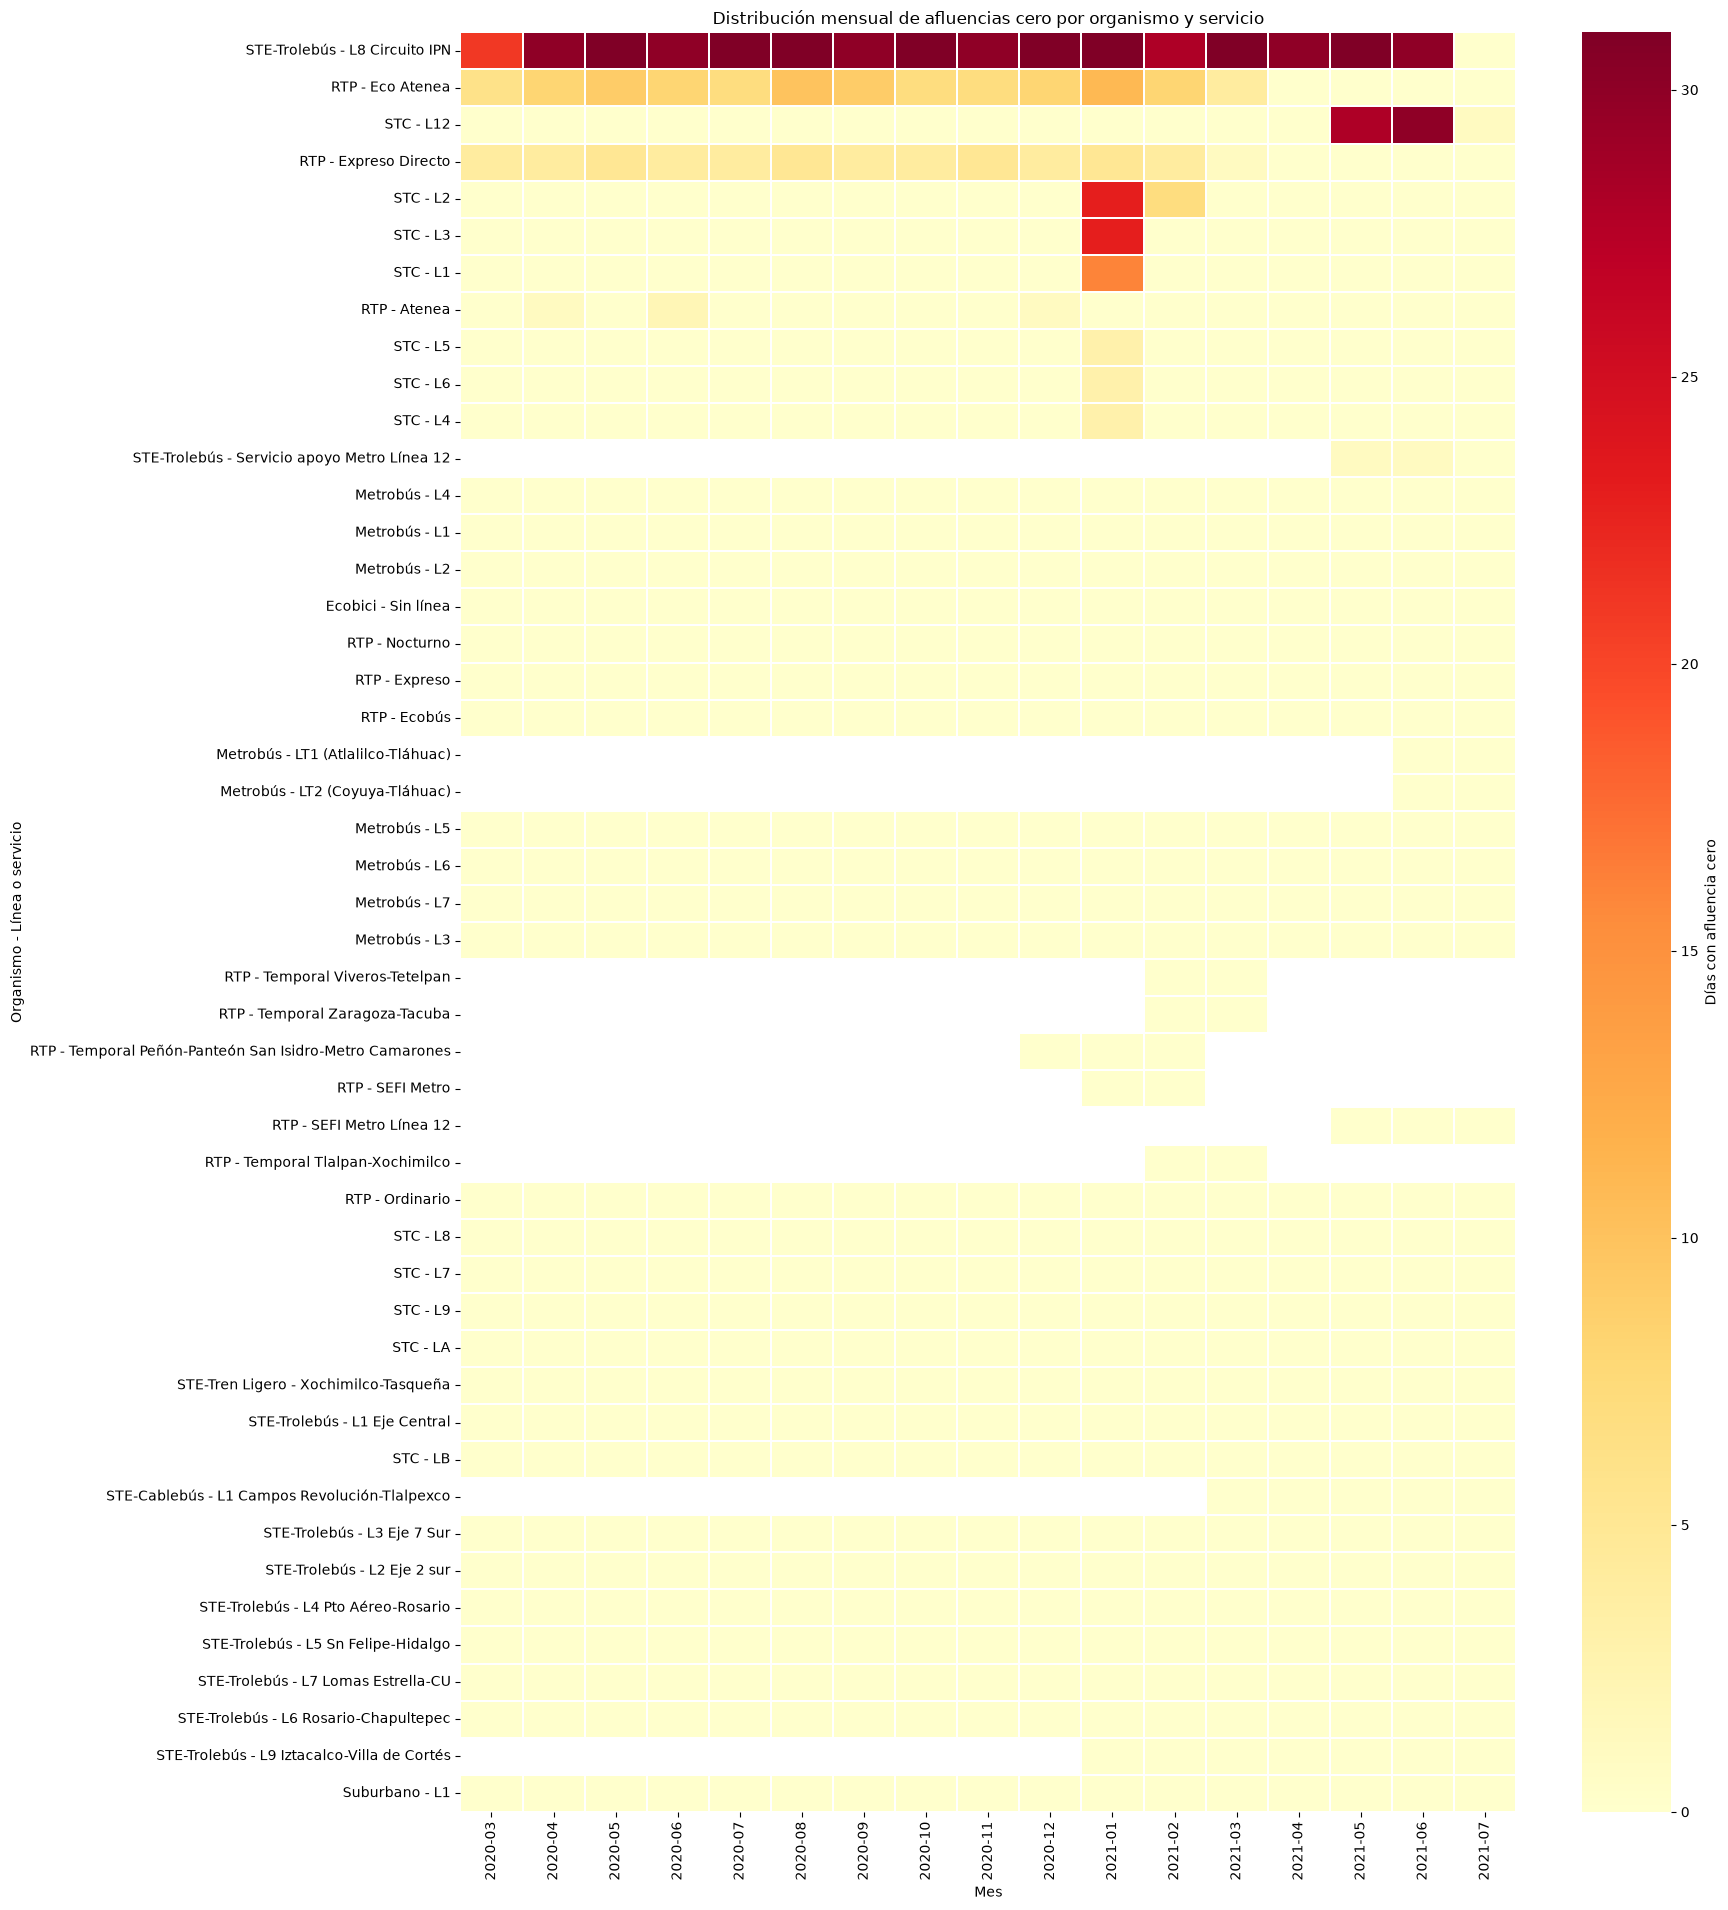

In [26]:
# Construir una matriz que conserve meses sin datos como NaN
TP_ceros = (
    TP_IQR
    .assign(
        periodo=lambda x: x["fecha"].dt.to_period("M"),
        servicio=lambda x: (
            x["organismo"].astype(str) + " - " +
            x["linea_servicio"].fillna("Sin línea").astype(str)
        ),
        cero=lambda x: x["afluencia_diaria"].eq(0).fillna(False).astype(int)
    )
    .groupby(["servicio", "periodo"])["cero"]
    .sum()
    .unstack()
)

# Ordenar por cantidad de registros en cero
TP_ceros = TP_ceros.loc[
    TP_ceros.sum(axis=1).sort_values(ascending=False).index
]

# Convertir a float64 y conservar los meses sin registros
TP_ceros = TP_ceros.astype(float)

plt.figure(figsize=(18, max(6, len(TP_ceros) * 0.4)))

sns.heatmap(
    TP_ceros,
    cmap="YlOrRd",
    mask=TP_ceros.isna(),
    linewidths=0.1,
    cbar_kws={"label": "Días con afluencia cero"}
)

plt.title("Distribución mensual de afluencias cero por organismo y servicio")
plt.xlabel("Mes")
plt.ylabel("Organismo - Línea o servicio")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


In [27]:
# Calcular valores faltantes por organismo y línea o servicio
Resumen_faltantes_TP = (
    TP_IQR
    .groupby(["organismo", "linea_servicio"], dropna=False)
    .agg(
        registros=("fecha", "size"),
        faltantes_tarjeta=("afluencia_tarjeta", lambda x: x.isna().sum()),
        faltantes_boleto=("afluencia_boleto", lambda x: x.isna().sum())
    )
    .assign(
        pct_tarjeta=lambda x: 100 * x["faltantes_tarjeta"] / x["registros"],
        pct_boleto=lambda x: 100 * x["faltantes_boleto"] / x["registros"]
    )
    .sort_values(
        ["faltantes_tarjeta", "faltantes_boleto"],
        ascending=False
    )
)

print("Valores faltantes por organismo y línea o servicio:")
display(Resumen_faltantes_TP.round(2))

Valores faltantes por organismo y línea o servicio:


registros  \
organismo       linea_servicio                                                 
Ecobici         NaN                                                      489   
Metrobús        L1                                                       489   
                L2                                                       489   
                L3                                                       489   
                L4                                                       489   
                L5                                                       489   
                L6                                                       489   
                L7                                                       489   
STC             L1                                                       489   
                L12                                                      489   
                L2                                                       489   
                L3                                                       489   
                L4                                                       489   
                L5                                                       489   
                L6                                                       489   
                L7                                                       489   
                L8                                                       489   
                L9                                                       489   
                LA                                                       489   
                LB                                                       489   
STE-Tren Ligero Xochimilco-Tasqueña                                      489   
STE-Trolebús    L1 Eje Central                                           489   
                L2 Eje 2 sur                                             489   
                L3 Eje 7 Sur                                             489   
                L4 Pto Aéreo-Rosario                                     489   
                L5 Sn Felipe-Hidalgo                                     489   
                L6 Rosario-Chapultepec                                   489   
                L7 Lomas Estrella-CU                                     489   
                L8 Circuito IPN                                          489   
Suburbano       L1                                                       489   
RTP             Eco Atenea                                               489   
                Atenea                                                   489   
STE-Trolebús    L9 Iztacalco-Villa de Cortés                             154   
STE-Cablebús    L1 Campos Revolución-Tlalpexco                           121   
STE-Trolebús    Servicio apoyo Metro Línea 12                             60   
Metrobús        LT1 (Atlalilco-Tláhuac)                                   26   
RTP             Expreso Directo                                          489   
Metrobús        LT2 (Coyuya-Tláhuac)                                      12   
RTP             Temporal Viveros-Tetelpan                                 30   
                Ecobús                                                   489   
                Ordinario                                                489   
                Expreso                                                  489   
                Nocturno                                                 489   
                SEFI Metro Línea 12                                       60   
                SEFI Metro                                                33   
                Temporal Peñón-Panteón San Isidro-Metro Camarones         80   
                Temporal Tlalpan-Xochimilco                               15   
                Temporal Zaragoza-Tacuba                                  30   

                                                                  


**Conclusiones del análisis de afluencia histórica del transporte público**

El análisis exploratorio de `Afluencia_TP_historico` permitió identificar patrones relevantes en los **valores atípicos, registros con afluencia cero y valores faltantes** de los distintos organismos y servicios de transporte.

1. Valores atípicos

Mediante el criterio del **rango intercuartílico (IQR)**, encontramos que las mayores concentraciones de valores atípicos ocurren durante **marzo de 2020**, destacando el 4 de marzo con 30 servicios atípicos y los días 5, 6 y 10 de marzo con 28 cada uno.

Este comportamiento podría estar relacionado con los cambios en los patrones de movilidad asociados con el inicio de la pandemia de **COVID-19**, aunque varias de estas fechas son anteriores a las principales restricciones sanitarias. Asimismo, identificamos valores atípicos durante festividades como **Navidad, Año Nuevo, Semana Santa y el Día de la Independencia**, lo que sugiere modificaciones en la demanda habitual del transporte.

2. Registros con afluencia cero

El mapa de calor permitió observar que los registros con afluencia cero no se distribuyen uniformemente entre los servicios. Destacan:

- **STE-Trolebús, Línea 8 (Circuito IPN):** presenta numerosos registros con afluencia cero durante gran parte del periodo.
- **RTP, Eco Atenea y Expreso Directo:** muestran concentraciones importantes de afluencias cero en distintos meses.
- **STC, Línea 12:** registra una elevada concentración de ceros durante mayo y junio de 2021.
- **Otras líneas del STC:** presentan concentraciones puntuales, principalmente durante enero de 2021.

Estos comportamientos podrían estar relacionados con cierres, modificaciones operativas o circunstancias extraordinarias, por lo que **no deben considerarse automáticamente errores de registro**.

3. Valores faltantes

La variable `afluencia_total_preliminar` presenta **202 valores faltantes (1.08 %)**. El análisis temporal muestra periodos sin información para determinados servicios, especialmente aquellos de carácter temporal, por lo que parte de esta ausencia podría estar relacionada con su disponibilidad operativa.

Por otra parte, identificamos porcentajes considerablemente elevados de información faltante en las variables:

- **`afluencia_tarjeta`:** 16,027 valores faltantes (85.64 %).
- **`afluencia_boleto`:** 15,116 valores faltantes (80.77 %).

El desglose por organismo y línea muestra que **la totalidad de los registros de Ecobici, Metrobús, STC y diversos servicios del STE presentan valores faltantes en ambas variables**. En contraste, algunos servicios de RTP disponen de información más completa, lo que evidencia diferencias importantes en la disponibilidad de datos entre organismos.

Dada la elevada proporción de valores faltantes y su concentración en múltiples sistemas de transporte, **se considera conveniente excluir `afluencia_tarjeta` y `afluencia_boleto` de los análisis estadísticos posteriores**, priorizando `afluencia_total_preliminar`, que presenta una cobertura considerablemente mayor.


## 2.4 Ecobici

In [28]:
# Conservar los registros originales
Ecobici = Viajes_Ecobici_202601.copy()

# Combinar fechas y horas de retiro y arribo
Ecobici["retiro"] = pd.to_datetime(Ecobici["Fecha_Retiro"].astype(str) + " " + Ecobici["Hora_Retiro"].astype(str), errors="coerce")

Ecobici["arribo"] = pd.to_datetime(Ecobici["Fecha_Arribo"].astype(str) + " " + Ecobici["Hora_Arribo"].astype(str), errors="coerce")

# Calcular la duración de cada viaje en minutos
Ecobici["duracion_min"] = ((Ecobici["arribo"] - Ecobici["retiro"]).dt.total_seconds() / 60)

# Crear variables temporales
dias = ["Lunes", "Martes", "Miércoles", "Jueves","Viernes", "Sábado", "Domingo"]

Ecobici["fecha"] = Ecobici["retiro"].dt.normalize()
Ecobici["hora"] = Ecobici["retiro"].dt.hour
Ecobici["dia_semana"] = Ecobici["retiro"].dt.day_of_week.map(
    dict(enumerate(dias))
)

print("Tabla Ecobici con variables temporales:")
display(Ecobici.head(10))

Tabla Ecobici con variables temporales:


,Genero_Usuario,Edad_Usuario,Bici,Ciclo_Estacion_Retiro,Fecha_Retiro,Hora_Retiro,Ciclo_EstacionArribo,Fecha_Arribo,Hora_Arribo,retiro,arribo,duracion_min,fecha,hora,dia_semana
0,M,30.0,4933404,059,2025-12-31,23:25:20,565,2026-01-01,00:00:16,2025-12-31 23:25:20,2026-01-01 00:00:16,34.933333,2025-12-31,23,Miércoles
1,M,27.0,4162376,180,2025-12-31,23:43:53,672,2026-01-01,00:00:31,2025-12-31 23:43:53,2026-01-01 00:00:31,16.633333,2025-12-31,23,Miércoles
2,M,29.0,3749272,014,2025-12-31,23:52:15,030,2026-01-01,00:00:50,2025-12-31 23:52:15,2026-01-01 00:00:50,8.583333,2025-12-31,23,Miércoles
3,M,44.0,5680772,014,2025-12-31,23:46:43,145,2026-01-01,00:00:53,2025-12-31 23:46:43,2026-01-01 00:00:53,14.166667,2025-12-31,23,Miércoles
4,M,22.0,5128459,031,2025-12-31,23:39:58,155,2026-01-01,00:01:05,2025-12-31 23:39:58,2026-01-01 00:01:05,21.116667,2025-12-31,23,Miércoles
5,M,67.0,2706091,015,2025-12-31,23:41:23,165,2026-01-01,00:01:15,2025-12-31 23:41:23,2026-01-01 00:01:15,19.866667,2025-12-31,23,Miércoles
6,M,33.0,6206304,041,2025-12-31,23:46:39,027,2026-01-01,00:01:18,2025-12-31 23:46:39,2026-01-01 00:01:18,14.650000,2025-12-31,23,Miércoles
7,M,34.0,7702525,538,2025-12-31,23:48:04,027,2026-01-01,00:01:37,2025-12-31 23:48:04,2026-01-01 00:01:37,13.550000,2025-12-31,23,Miércoles
8,M,28.0,7849797,538,2025-12-31,23:47:55,027,2026-01-01,00:01:37,2025-12-31 23:47:55,2026-01-01 00:01:37,13.700000,2025-12-31,23,Miércoles
9,M,32.0,4707477,328,2025-12-31,23:46:28,022,2026-01-01,00:01:46,2025-12-31 23:46:28,2026-01-01 00:01:46,15.300000,2025-12-31,23,Miércoles


In [29]:
# Analizar únicamente viajes con duración válida y positiva
Duracion_Ecobici = Ecobici.loc[Ecobici["duracion_min"] > 0, "duracion_min"]

# Calcular estadísticas descriptivas
Estadisticas_Ecobici = (
    Duracion_Ecobici
    .describe(percentiles=[.01, .05, .25, .5, .75, .95, .99])
    .to_frame("duracion_min")
    .T
    .assign(
        RIC=lambda x: x["75%"] - x["25%"],
        asimetria=Duracion_Ecobici.skew()
    )
    .rename(columns={
        "count": "n",
        "mean": "media",
        "std": "desv_std_muestral",
        "50%": "mediana"
    })
)

print("Estadísticas descriptivas de duración de los viajes:")
display(Estadisticas_Ecobici.round(2))

Estadísticas descriptivas de duración de los viajes:


,n,media,desv_std_muestral,min,1%,5%,25%,mediana,75%,95%,99%,max,RIC,asimetria
duracion_min,1525302.0,15.71,275.8,0.23,2.25,3.53,7.08,11.83,19.85,36.78,50.05,257146.3,12.77,722.39


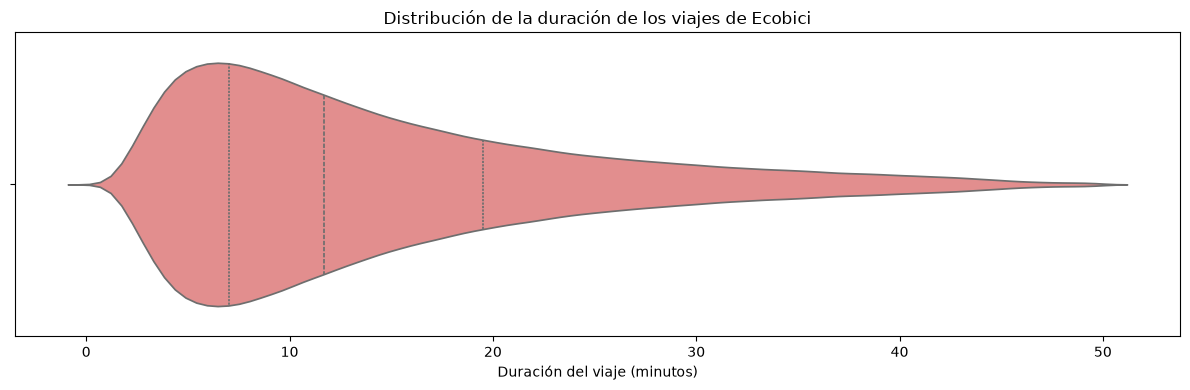

In [30]:
# Diagrama de violín
plt.figure(figsize=(12, 4))

Duracion_Ecobici_99 = Duracion_Ecobici[
    Duracion_Ecobici <= Duracion_Ecobici.quantile(0.99)
]

sns.violinplot(x=Duracion_Ecobici_99, color="lightcoral", inner="quart")

plt.title("Distribución de la duración de los viajes de Ecobici")
plt.xlabel("Duración del viaje (minutos)")
plt.tight_layout()
plt.show()


In [31]:
# 1. Calcular límites IQR
Q1, Q3, RIC = Estadisticas_Ecobici[["25%", "75%", "RIC"]].iloc[0]
limite_inferior, limite_superior = Q1 - 1.5 * RIC, Q3 + 1.5 * RIC

print(f"Límite inferior: {limite_inferior:.2f} minutos")
print(f"Límite superior: {limite_superior:.2f} minutos")

# 2. Identificar y clasificar valores atípicos
Ecobici_IQR = Ecobici.copy()
d = Ecobici_IQR["duracion_min"]

inferior = d.gt(0) & d.lt(limite_inferior)
superior = d.gt(limite_superior)

Ecobici_IQR["tipo_atipico"] = "No atípico"
Ecobici_IQR.loc[inferior, "tipo_atipico"] = "Inferior"
Ecobici_IQR.loc[superior, "tipo_atipico"] = "Superior"
Ecobici_IQR.loc[d.le(0), "tipo_atipico"] = "Duración no válida"
Ecobici_IQR.loc[d.isna(), "tipo_atipico"] = "Sin dato"

Ecobici_IQR = Ecobici_IQR.assign(
    atipico=inferior | superior,
    RIC=RIC,
    limite_inferior=limite_inferior,
    limite_superior=limite_superior
)

# 3. Tabla principal y conteos
print("Tabla Ecobici con identificación de valores atípicos:")
display(Ecobici_IQR.head(10))

validos = d.gt(0).sum()
atipicos = Ecobici_IQR["atipico"].sum()

print("Viajes con duración válida:", validos)
print("Viajes con duración atípica:", atipicos)
print("Porcentaje de atípicos:", round(100 * atipicos / validos, 2), "%")

print("Clasificación de las duraciones:")
display(Ecobici_IQR["tipo_atipico"].value_counts().to_frame("registros"))

# 4. Función para resumir atípicos por agrupación
def resumen_atipicos(columna):
    return (
        Ecobici_IQR.groupby(columna, dropna=False)
        .agg(
            viajes_validos=("duracion_min", lambda x: x.gt(0).sum()),
            viajes_atipicos=("atipico", "sum")
        )
        .assign(porcentaje_atipicos=lambda x:
                100 * x["viajes_atipicos"] / x["viajes_validos"])
        .sort_values("viajes_atipicos", ascending=False)
    )

# 5. Resúmenes por fecha, hora, día y estación
Resumen_atipicos_Ecobici_fecha = (
    Ecobici_IQR[Ecobici_IQR["atipico"]]
    .groupby("fecha").size()
    .sort_values(ascending=False)
    .to_frame("viajes_atipicos")
)

Resumen_atipicos_Ecobici_hora = resumen_atipicos("hora")
Resumen_atipicos_Ecobici_dia = resumen_atipicos("dia_semana").reindex(
    ["Lunes", "Martes", "Miércoles", "Jueves",
     "Viernes", "Sábado", "Domingo"]
)
Resumen_atipicos_Ecobici_estacion = resumen_atipicos("Ciclo_Estacion_Retiro")

print("Fechas con mayor concentración de viajes atípicos:")
display(Resumen_atipicos_Ecobici_fecha.head(10))

print("Concentración de valores atípicos por hora:")
display(Resumen_atipicos_Ecobici_hora.round(2))

print("Concentración de valores atípicos por día de la semana:")
display(Resumen_atipicos_Ecobici_dia.round(2))

print("Estaciones de retiro con más viajes atípicos:")
display(Resumen_atipicos_Ecobici_estacion.head(20).round(2))

# 6. Atípicos por año y tipo
Resumen_atipicos_Ecobici_anio = (
    Ecobici_IQR[Ecobici_IQR["atipico"]]
    .assign(anio=lambda x: x["retiro"].dt.year)
    .groupby(["anio", "tipo_atipico"])
    .size().unstack(fill_value=0)
)

print("Valores atípicos por año y tipo:")
display(Resumen_atipicos_Ecobici_anio)

# 7. Muestra de los viajes atípicos más largos
print("Muestra de viajes con duración atípica:")
display(
    Ecobici_IQR[Ecobici_IQR["atipico"]]
    .sort_values("duracion_min", ascending=False)
    .head(10)
)


Límite inferior: -12.07 minutos
Límite superior: 39.00 minutos
Tabla Ecobici con identificación de valores atípicos:


,Genero_Usuario,Edad_Usuario,Bici,Ciclo_Estacion_Retiro,Fecha_Retiro,Hora_Retiro,Ciclo_EstacionArribo,Fecha_Arribo,Hora_Arribo,retiro,arribo,duracion_min,fecha,hora,dia_semana,tipo_atipico,atipico,RIC,limite_inferior,limite_superior
0,M,30.0,4933404,059,2025-12-31,23:25:20,565,2026-01-01,00:00:16,2025-12-31 23:25:20,2026-01-01 00:00:16,34.933333,2025-12-31,23,Miércoles,No atípico,False,12.766667,-12.066667,39.0
1,M,27.0,4162376,180,2025-12-31,23:43:53,672,2026-01-01,00:00:31,2025-12-31 23:43:53,2026-01-01 00:00:31,16.633333,2025-12-31,23,Miércoles,No atípico,False,12.766667,-12.066667,39.0
2,M,29.0,3749272,014,2025-12-31,23:52:15,030,2026-01-01,00:00:50,2025-12-31 23:52:15,2026-01-01 00:00:50,8.583333,2025-12-31,23,Miércoles,No atípico,False,12.766667,-12.066667,39.0
3,M,44.0,5680772,014,2025-12-31,23:46:43,145,2026-01-01,00:00:53,2025-12-31 23:46:43,2026-01-01 00:00:53,14.166667,2025-12-31,23,Miércoles,No atípico,False,12.766667,-12.066667,39.0
4,M,22.0,5128459,031,2025-12-31,23:39:58,155,2026-01-01,00:01:05,2025-12-31 23:39:58,2026-01-01 00:01:05,21.116667,2025-12-31,23,Miércoles,No atípico,False,12.766667,-12.066667,39.0
5,M,67.0,2706091,015,2025-12-31,23:41:23,165,2026-01-01,00:01:15,2025-12-31 23:41:23,2026-01-01 00:01:15,19.866667,2025-12-31,23,Miércoles,No atípico,False,12.766667,-12.066667,39.0
6,M,33.0,6206304,041,2025-12-31,23:46:39,027,2026-01-01,00:01:18,2025-12-31 23:46:39,2026-01-01 00:01:18,14.650000,2025-12-31,23,Miércoles,No atípico,False,12.766667,-12.066667,39.0
7,M,34.0,7702525,538,2025-12-31,23:48:04,027,2026-01-01,00:01:37,2025-12-31 23:48:04,2026-01-01 00:01:37,13.550000,2025-12-31,23,Miércoles,No atípico,False,12.766667,-12.066667,39.0
8,M,28.0,7849797,538,2025-12-31,23:47:55,027,2026-01-01,00:01:37,2025-12-31 23:47:55,2026-01-01 00:01:37,13.700000,2025-12-31,23,Miércoles,No atípico,False,12.766667,-12.066667,39.0
9,M,32.0,4707477,328,2025-12-31,23:46:28,022,2026-01-01,00:01:46,2025-12-31 23:46:28,2026-01-01 00:01:46,15.300000,2025-12-31,23,Miércoles,No atípico,False,12.766667,-12.066667,39.0


Viajes con duración válida: 1525302
Viajes con duración atípica: 57796
Porcentaje de atípicos: 3.79 %
Clasificación de las duraciones:


,registros
tipo_atipico,
No atípico,1467506
Superior,57796


Fechas con mayor concentración de viajes atípicos:


,viajes_atipicos
fecha,
2026-01-25,3981
2026-01-18,3598
2026-01-04,3365
2026-01-11,3164
2026-01-30,2116
2026-01-29,2036
2026-01-23,1956
2026-01-27,1928
2026-01-28,1850


... (6 outputs left out)

Valores atípicos por año y tipo:


tipo_atipico,Superior
anio,
2025,31
2026,57765


Muestra de viajes con duración atípica:


,Genero_Usuario,Edad_Usuario,Bici,Ciclo_Estacion_Retiro,Fecha_Retiro,Hora_Retiro,Ciclo_EstacionArribo,Fecha_Arribo,Hora_Arribo,retiro,arribo,duracion_min,fecha,hora,dia_semana,tipo_atipico,atipico,RIC,limite_inferior,limite_superior
1329971,M,30.0,4852091,229,2025-08-02,23:24:30,1000,2026-01-28,13:10:48,2025-08-02 23:24:30,2026-01-28 13:10:48,257146.300000,2025-08-02,23,Sábado,Superior,True,12.766667,-12.066667,39.0
1043980,M,45.0,3668118,146,2025-10-03,16:36:04,1000,2026-01-22,21:06:01,2025-10-03 16:36:04,2026-01-22 21:06:01,160109.950000,2025-10-03,16,Viernes,Superior,True,12.766667,-12.066667,39.0
728276,F,37.0,8460511,296,2025-11-09,16:53:59,1000,2026-01-16,19:45:59,2025-11-09 16:53:59,2026-01-16 19:45:59,98092.000000,2025-11-09,16,Domingo,Superior,True,12.766667,-12.066667,39.0
349714,M,24.0,6155329,571,2025-11-03,17:36:53,625,2026-01-09,16:16:22,2025-11-03 17:36:53,2026-01-09 16:16:22,96399.483333,2025-11-03,17,Lunes,Superior,True,12.766667,-12.066667,39.0
1002918,M,28.0,7738578,192-193,2025-12-20,11:57:50,1000,2026-01-22,10:20:35,2025-12-20 11:57:50,2026-01-22 10:20:35,47422.750000,2025-12-20,11,Sábado,Superior,True,12.766667,-12.066667,39.0
154233,M,46.0,3262086,067,2025-12-14,18:41:22,542,2026-01-06,00:11:44,2025-12-14 18:41:22,2026-01-06 00:11:44,32010.366667,2025-12-14,18,Domingo,Superior,True,12.766667,-12.066667,39.0
718937,M,31.0,3811031,099,2025-12-28,16:49:33,1000,2026-01-16,17:40:46,2025-12-28 16:49:33,2026-01-16 17:40:46,27411.216667,2025-12-28,16,Domingo,Superior,True,12.766667,-12.066667,39.0
257833,M,32.0,5346036,250,2025-12-27,22:40:41,256,2026-01-07,21:38:17,2025-12-27 22:40:41,2026-01-07 21:38:17,15777.600000,2025-12-27,22,Sábado,Superior,True,12.766667,-12.066667,39.0
48260,M,52.0,5346341,354,2025-12-23,21:51:05,369,2026-01-03,08:48:21,2025-12-23 21:51:05,2026-01-03 08:48:21,15057.266667,2025-12-23,21,Martes,Superior,True,12.766667,-12.066667,39.0
38814,F,26.0,6152623,560,2025-12-23,13:35:51,124,2026-01-02,18:56:40,2025-12-23 13:35:51,2026-01-02 18:56:40,14720.816667,2025-12-23,13,Martes,Superior,True,12.766667,-12.066667,39.0


In [32]:
# Contar viajes por fecha y hora de retiro
Ecobici_hora = (
    Ecobici
    .dropna(subset=["fecha", "hora"])
    .groupby(["fecha", "hora"])
    .size()
    .reset_index(name="viajes")
)

# Estadísticas descriptivas por hora del día
grupo = Ecobici_hora.groupby("hora")["viajes"]

Estadisticas_Ecobici_hora = (
    grupo.describe(percentiles=[.01, .05, .25, .5, .75, .95, .99])
    .assign(
        RIC=lambda x: x["75%"] - x["25%"],
        asimetria=grupo.skew()
    )
    .rename(columns={
        "count": "n",
        "mean": "media",
        "std": "desv_std_muestral",
        "50%": "mediana"
    })
)

print("Estadísticas de viajes por hora del día:")
display(Estadisticas_Ecobici_hora.round(2))

Estadísticas de viajes por hora del día:


,n,media,desv_std_muestral,min,1%,5%,25%,mediana,75%,95%,99%,max,RIC,asimetria
hora,,,,,,,,,,,,,,
0,31.0,184.45,69.66,68.0,74.90,91.0,136.00,168.0,216.50,297.50,346.50,363.0,80.50,0.68
5,31.0,362.29,182.02,83.0,86.30,95.5,143.00,439.0,504.50,564.00,573.70,574.0,361.50,-0.52
6,31.0,1206.87,663.67,116.0,154.10,244.5,464.00,1455.0,1760.00,1970.00,2002.20,2004.0,1296.00,-0.47
7,31.0,2520.65,1385.71,184.0,272.80,528.0,1001.00,3032.0,3721.00,4035.50,4070.40,4074.0,2720.00,-0.48
8,31.0,3483.71,1722.58,236.0,462.50,1031.5,1592.50,4294.0,4935.00,5315.00,5429.90,5471.0,3342.50,-0.51
9,31.0,2833.23,869.82,311.0,613.10,1535.5,2090.50,3168.0,3463.00,3725.00,3794.70,3822.0,1372.50,-1.03
10,31.0,2417.61,533.45,461.0,786.80,1548.0,2309.00,2491.0,2645.00,3095.50,3401.60,3446.0,336.00,-1.61
11,32.0,2364.75,742.97,1.0,175.53,1114.0,2238.25,2414.0,2577.50,3644.30,3903.82,3928.0,339.25,-0.91
12,31.0,2605.10,602.49,789.0,1077.90,1878.5,2391.50,2653.0,2762.00,3798.50,3995.80,4033.0,370.50,-0.06


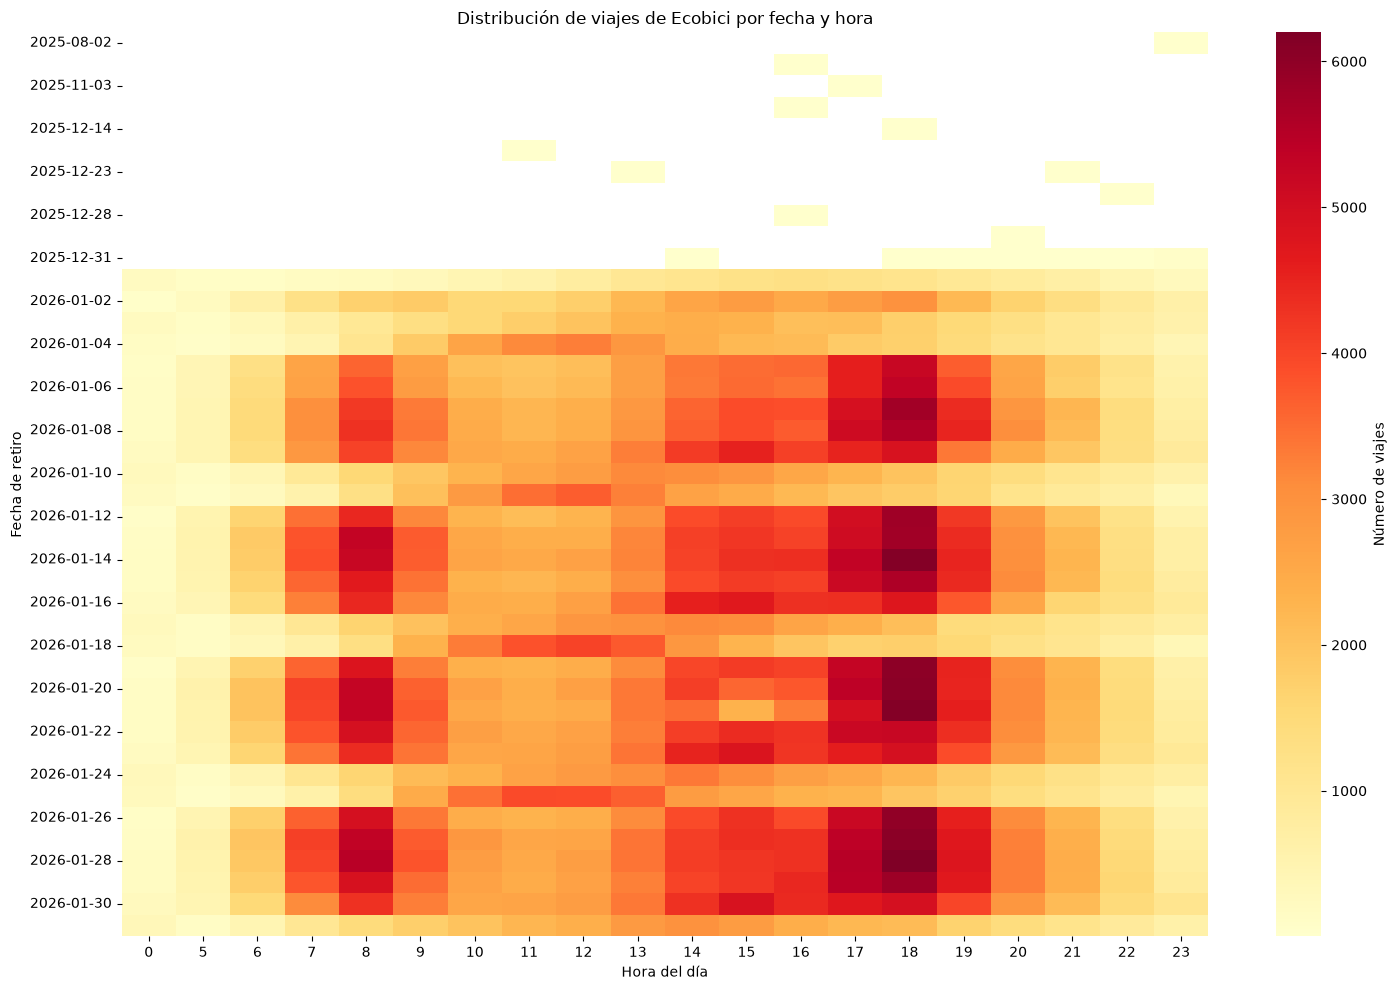

In [33]:
# Crear matriz de viajes por fecha y hora
Mapa_Ecobici = (
    Ecobici_hora
    .pivot(index="fecha", columns="hora", values="viajes")
    .astype(float)
    .sort_index()
)

# Mostrar únicamente la fecha
Mapa_Ecobici.index = pd.to_datetime(Mapa_Ecobici.index).strftime("%Y-%m-%d")

# Graficar el mapa de calor
plt.figure(figsize=(15, 10))

sns.heatmap(
    Mapa_Ecobici,
    cmap="YlOrRd",
    mask=Mapa_Ecobici.isna(),
    cbar_kws={"label": "Número de viajes"},
    yticklabels=2
)

plt.title("Distribución de viajes de Ecobici por fecha y hora")
plt.xlabel("Hora del día")
plt.ylabel("Fecha de retiro")
plt.tight_layout()
plt.show()

In [34]:
# Calcular límites IQR por hora
Limites_Ecobici_hora = (
    Estadisticas_Ecobici_hora
    .assign(
        limite_inferior=lambda x: x["25%"] - 1.5 * x["RIC"],
        limite_superior=lambda x: x["75%"] + 1.5 * x["RIC"]
    )[["RIC", "limite_inferior", "limite_superior"]]
)

# Incorporar límites y clasificar valores atípicos
Ecobici_IQR_hora = Ecobici_hora.join(
    Limites_Ecobici_hora, on="hora"
)

inferior = (
    Ecobici_IQR_hora["viajes"] < Ecobici_IQR_hora["limite_inferior"]
)
superior = (
    Ecobici_IQR_hora["viajes"] > Ecobici_IQR_hora["limite_superior"]
)

Ecobici_IQR_hora["tipo_atipico"] = "No atípico"
Ecobici_IQR_hora.loc[inferior, "tipo_atipico"] = "Inferior"
Ecobici_IQR_hora.loc[superior, "tipo_atipico"] = "Superior"
Ecobici_IQR_hora["atipico"] = inferior | superior

print("Horas con cantidad de viajes atípica:")
display(
    Ecobici_IQR_hora[Ecobici_IQR_hora["atipico"]]
    .sort_values("fecha")
    .round(2)
)

Horas con cantidad de viajes atípica:


C:\Users\jgallegos\AppData\Local\Temp\ipykernel_13544\184513415.py:31: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  .round(2)


,fecha,hora,viajes,RIC,limite_inferior,limite_superior,tipo_atipico,atipico
0,2025-08-02,23,1,221.00,228.50,1112.50,Inferior,True
5,2025-12-20,11,1,339.25,1729.38,3086.38,Inferior,True
6,2025-12-23,13,1,447.25,2227.38,4016.38,Inferior,True
8,2025-12-27,22,1,566.00,5.00,2269.00,Inferior,True
11,2025-12-31,14,1,1122.25,1276.38,5765.38,Inferior,True
16,2025-12-31,22,2,566.00,5.00,2269.00,Inferior,True
17,2025-12-31,23,87,221.00,228.50,1112.50,Inferior,True
24,2026-01-01,10,461,336.00,1805.00,3149.00,Inferior,True
25,2026-01-01,11,564,339.25,1729.38,3086.38,Inferior,True
26,2026-01-01,12,789,370.50,1835.75,3317.75,Inferior,True


**Lectura de Ecobici (enero 2026).** La duración de los viajes tiene una cola derecha muy larga: la mayoría dura entre 5 y 20 minutos, pero hay registros de días e incluso meses, que no corresponden a viajes reales (se tratan en D4). Por eso usamos la mediana y el rango intercuartílico en lugar de la media. El mapa de calor muestra dos picos diarios en días laborales (mañana y tarde) y un patrón más plano los fines de semana.

## 2.5 Tipo de pago (P1)

Revisamos qué proporción de los accesos corresponde a cada tipo de pago en cada sistema, por año y por línea. Todavía no se aplica la corrección de febrero de 2025 (decisión D5), por lo que ese mes puede verse distinto.

In [35]:
# Proporción de accesos por tipo de pago, por sistema y año
pago_sistema = pd.concat([
    Afluencia_Metro.assign(sistema="Metro"),
    Afluencia_Metrobus.assign(sistema="Metrobús"),
])
pago_anual = (pago_sistema
              .assign(anio=pago_sistema["fecha"].dt.year)
              .pivot_table(index=["sistema", "anio"], columns="tipo_pago",
                           values="afluencia", aggfunc="sum", fill_value=0))
pago_anual_pct = pago_anual.div(pago_anual.sum(axis=1), axis=0).mul(100).round(1)
display(pago_anual_pct)

# Distribución del % de gratuidad diario por línea (Metro): centro, dispersión y posición
metro_pago_dia = (Afluencia_Metro.pivot_table(index=["fecha", "linea"], columns="tipo_pago",
                                              values="afluencia", aggfunc="sum", fill_value=0))
metro_pago_dia = metro_pago_dia[metro_pago_dia.sum(axis=1) > 0]   # solo días con servicio
metro_pago_dia["pct_gratuidad"] = 100 * metro_pago_dia["Gratuidad"] / metro_pago_dia.sum(axis=1)
resumen_gratuidad = (metro_pago_dia.groupby("linea")["pct_gratuidad"]
                     .describe(percentiles=[.25, .5, .75]).round(1)
                     .sort_values("50%"))
display(resumen_gratuidad)

g = pago_anual_pct
display(Markdown(
    f"**Lectura.** En el Metro el prepago pasa de **{g.loc[('Metro', 2021), 'Prepago']:.1f} %** de los accesos en 2021 "
    f"a **{g.loc[('Metro', 2025), 'Prepago']:.1f} %** en 2025, mientras que el boleto cae de "
    f"**{g.loc[('Metro', 2021), 'Boleto']:.1f} %** a prácticamente cero. La gratuidad sube poco a poco desde "
    f"{g.loc[('Metro', 2021), 'Gratuidad']:.1f} % en 2021, pero en 2025 salta a **{g.loc[('Metro', 2025), 'Gratuidad']:.1f} %**: "
    f"al revisar por mes, el salto viene solo de febrero de 2025, donde gratuidad y prepago parecen intercambiados "
    f"(se corrige en la decisión D5). "
    f"En el Metrobús no existe boleto: el prepago representa más del 90 % todos los años. "
    f"Por línea del Metro, la mediana diaria de gratuidad va de **{resumen_gratuidad['50%'].min():.1f} %** "
    f"({resumen_gratuidad.index[0]}) a **{resumen_gratuidad['50%'].max():.1f} %** ({resumen_gratuidad.index[-1]})."
))

tipo_pago      Boleto  Gratuidad  Prepago
sistema  anio                            
Metro    2021    30.1        9.3     60.6
         2022    28.4       11.4     60.2
         2023    21.2       11.8     67.0
         2024     0.2       12.8     87.0
         2025     0.0       18.6     81.4
         2026     0.0       13.1     86.9
Metrobús 2021     0.0        6.6     93.4
         2022     0.0        5.3     94.7
         2023     0.0        5.7     94.3
         2024     0.0        6.5     93.5
         2025     0.0        7.5     92.5
         2026     0.0        7.3     92.7

,count,mean,std,min,25%,50%,75%,max
linea,,,,,,,,
Línea 9,2099.0,10.4,9.5,0.1,8.5,9.5,10.3,91.5
Línea 6,2096.0,11.1,9.3,0.1,9.4,10.0,10.8,91.7
Línea 7,2099.0,10.7,9.3,0.1,9.0,10.1,10.8,90.3
Línea A,2099.0,11.7,9.4,0.1,8.7,11.3,13.4,89.0
Línea 12,1478.0,13.3,10.8,0.6,11.0,11.7,12.4,89.3
Línea 5,2096.0,12.6,8.9,0.1,10.7,11.8,12.8,88.9
Línea 2,2069.0,12.9,8.9,0.1,10.4,11.9,14.0,87.5
Línea 3,2076.0,12.7,9.0,0.1,11.0,12.0,12.7,89.9
Línea B,2099.0,13.6,9.0,0.1,11.7,12.9,14.0,91.9


**Lectura.** En el Metro el prepago pasa de **60.6 %** de los accesos en 2021 a **81.4 %** en 2025, mientras que el boleto cae de **30.1 %** a prácticamente cero. La gratuidad sube poco a poco desde 9.3 % en 2021, pero en 2025 salta a **18.6 %**: al revisar por mes, el salto viene solo de febrero de 2025, donde gratuidad y prepago parecen intercambiados (se corrige en la decisión D5). En el Metrobús no existe boleto: el prepago representa más del 90 % todos los años. Por línea del Metro, la mediana diaria de gratuidad va de **9.5 %** (Línea 9) a **17.3 %** (Línea 1).

### 2.6 Ingresos del Metro (P3)

Describimos el ingreso diario por tipo de ingreso y comparamos los totales mensuales con la afluencia del Metro en el periodo común (enero 2021 – julio 2023). Esta base todavía contiene duplicados y faltantes, que se tratan en la decisión D3.

In [36]:
# Estadística descriptiva del ingreso diario por tipo de ingreso
display(Ingresos_SCTM.groupby("tipo_ingreso")["ingreso"]
        .describe(percentiles=[.25, .5, .75]).round(0))

# Totales mensuales en el periodo común
inicio, fin = "2021-01-01", "2023-07-31"
ing_mes = (Ingresos_SCTM[Ingresos_SCTM["fecha"].between(inicio, fin)]
           .groupby(Ingresos_SCTM["fecha"].dt.to_period("M"))["ingreso"].sum(min_count=1))
afl_mes = (Afluencia_Metro[Afluencia_Metro["fecha"].between(inicio, fin)]
           .groupby(Afluencia_Metro["fecha"].dt.to_period("M"))["afluencia"].sum())
mensual_eda = pd.concat([afl_mes.rename("afluencia"), ing_mes.rename("ingreso")], axis=1).dropna()

pearson = mensual_eda.corr(method="pearson").iloc[0, 1]
spearman = mensual_eda.corr(method="spearman").iloc[0, 1]
display(mensual_eda.describe().round(0))
display(Markdown(
    f"**Lectura.** En los {len(mensual_eda)} meses del periodo común, la correlación entre afluencia e ingreso mensual es "
    f"**r = {pearson:.3f} (Pearson)** y **ρ = {spearman:.3f} (Spearman)**. Ambas son muy altas: la relación es "
    f"fuerte y prácticamente lineal. Spearman, que solo usa el orden de los meses, confirma que el resultado no "
    f"depende de unos cuantos valores extremos. Esto se retoma en la visualización de P3."
))

,count,mean,std,min,25%,50%,75%,max
tipo_ingreso,,,,,,,,
Boletos,50455.0,618383.0,507403.0,0.0,241200.0,501225.0,874718.0,8337195.0
QR/Validación,7576.0,938.0,3314.0,0.0,0.0,0.0,0.0,24105.0
Recargas,50455.0,681513.0,500986.0,0.0,288026.0,574199.0,949907.0,3497492.0
Tarjetas,50395.0,5558.0,12139.0,0.0,120.0,2080.0,5375.0,368110.0


,afluencia,ingreso
count,31.0,31.0
mean,79503144.0,370702483.0
std,14135014.0,61550348.0
min,41033642.0,192975952.0
25%,69988158.0,329151058.0
50%,84154004.0,392352477.0
75%,90082955.0,413060428.0
max,99399033.0,448072803.0


**Lectura.** En los 31 meses del periodo común, la correlación entre afluencia e ingreso mensual es **r = 0.991 (Pearson)** y **ρ = 0.969 (Spearman)**. Ambas son muy altas: la relación es fuerte y prácticamente lineal. Spearman, que solo usa el orden de los meses, confirma que el resultado no depende de unos cuantos valores extremos. Esto se retoma en la visualización de P3.

# 3. Calidad, limpieza y transformación

## 3.1 Limpieza de los datos

Trabajamos sobre **copias** de las tablas cargadas en la sección 1: los archivos de `Datasets/` no se modifican y las versiones limpias se exportan a `data/processed/`. Cada decisión se registra en una bitácora (problema, criterio, filas afectadas, acción y limitación). La decisión D1 (etiquetas mal codificadas) ya se aplicó en la sección 1.

In [37]:
# Definir las rutas para guardar los datos procesados, gráficas y tablas
ROOT = DATA_DIR.parent
OUT_DATA = ROOT / "data" / "processed"
OUT_FIG = ROOT / "resultados" / "figuras"
OUT_TAB = ROOT / "resultados" / "tablas"

# Crear las carpetas de resultados si todavía no existen
for carpeta in (OUT_DATA, OUT_FIG, OUT_TAB):
    carpeta.mkdir(parents=True, exist_ok=True)

# Crear copias de los DataFrames para trabajar sin modificar los originales
metro_raw = Afluencia_Metro.copy()
metro = metro_raw.copy()
metrobus = Afluencia_Metrobus.copy()
ingresos = Ingresos_SCTM.copy()
historico = Afluencia_TP_historico.copy()
ecobici = Viajes_Ecobici_202601.copy()

Revisamos los rangos de las variables numéricas. No hay valores negativos en ninguna tabla. Sí hay muchos ceros en el Metro (D2), 57 afluencias con decimales en el Metrobús y faltantes en ingresos (D3).

In [38]:
# Rangos de las variables numéricas y valores 
rangos = pd.DataFrame({
    "metro_afluencia": metro["afluencia"].describe(),
    "metrobus_afluencia": metrobus["afluencia"].describe(),
    "ingreso": ingresos["ingreso"].describe(),
    "ecobici_edad": ecobici["Edad_Usuario"].describe(),
}).round(1)
display(rangos)

print("Negativos  -> metro:", (metro["afluencia"] < 0).sum(),
      "| metrobús:", (metrobus["afluencia"] < 0).sum(),
      "| ingresos:", (ingresos["ingreso"] < 0).sum())
print("Ceros      -> metro:", f"{(metro['afluencia'] == 0).sum():,}",
      f"({100 * (metro['afluencia'] == 0).mean():.1f} % de las filas)")
print("Afluencia Metrobús no entera:", (metrobus["afluencia"] % 1 != 0).sum())

,metro_afluencia,metrobus_afluencia,ingreso,ecobici_edad
count,1227915.0,29386.0,158881.0,1525223.0
mean,5129.7,90640.8,414608.9,34.6
std,8758.5,105655.8,508479.6,9.8
min,0.0,42.0,0.0,16.0
25%,7.0,10865.0,2680.0,28.0
50%,2045.0,35209.5,233225.0,33.0
75%,6052.0,148693.8,662765.0,40.0
max,119577.0,586643.0,8337195.0,100.0


Negativos  -> metro: 0 | metrobús: 0 | ingresos: 0
Ceros      -> metro: 303,400 (24.7 % de las filas)
Afluencia Metrobús no entera: 57


### D2 · Ceros en la afluencia del Metro: ¿error, faltante o cierre?

**Problema.** Alrededor de una cuarta parte de las filas del Metro tienen afluencia 0. Un cero en un tipo de pago puede ser legítimo, pero si una estación completa suma 0 en un día, la estación no operó. Agregamos a nivel estación-día y buscamos periodos en que líneas completas suman cero.

In [39]:
metro["fecha"] = pd.to_datetime(metro["fecha"], format="%Y-%m-%d")

estacion_dia = metro.groupby(["fecha", "linea", "estacion"], as_index=False)["afluencia"].sum()
estacion_dia["en_servicio"] = estacion_dia["afluencia"] > 0
print(f"Estación-día con afluencia total 0: {(~estacion_dia['en_servicio']).sum():,} "
      f"de {len(estacion_dia):,} ({100 * (~estacion_dia['en_servicio']).mean():.1f} %)")

# Periodos en que una LÍNEA completa suma cero
linea_dia = metro.groupby(["fecha", "linea"])["afluencia"].sum().reset_index()
cerradas = linea_dia[linea_dia["afluencia"] == 0]
resumen_cierres = cerradas.groupby("linea")["fecha"].agg(dias="count", desde="min", hasta="max")
display(resumen_cierres)

# Estaciones con más días en cero
display(estacion_dia[~estacion_dia["en_servicio"]]
        .groupby(["linea", "estacion"]).size().sort_values(ascending=False).head(10)
        .to_frame("dias_en_cero"))

Estación-día con afluencia total 0: 29,764 de 409,305 (7.3 %)


,dias,desde,hasta
linea,,,
Línea 1,16,2021-01-09,2021-01-24
Línea 12,621,2021-05-04,2023-01-14
Línea 2,30,2021-01-09,2021-02-07
Línea 3,23,2021-01-09,2021-01-31
Línea 4,3,2021-01-09,2021-01-11
Línea 5,3,2021-01-09,2021-01-11
Línea 6,3,2021-01-09,2021-01-11


dias_en_cero
linea    estacion                        
Línea 12 Tlaltenco                   1000
         Zapotitlán                   999
         Nopalera                     998
         Olivos                       997
         Tezonco                      995
         Tláhuac                      989
Línea 1  Isabel la Católica           813
         Salto del Agua               813
Línea 12 Lomas Estrella               805
         Calle 11                     805

**Contexto.** Los periodos en cero coinciden con cierres conocidos: la **Línea 12** del 4 de mayo de 2021 al 14 de enero de 2023 (tras el colapso del tramo elevado), las **líneas 1 a 6** tras el incendio del Centro de Control del 9 de enero de 2021, y tramos de la **Línea 1** durante su modernización. No son errores de captura, pero tampoco son demanda cero.

**Decisión.** No borramos ni imputamos los ceros: creamos la bandera `en_servicio`. Para **totales** usamos todas las filas; para **promedios típicos**, solo los días con servicio. La tabla de sensibilidad muestra cuánto cambia la media de cada línea con y sin días de cierre.

In [40]:
# Sensibilidad: afluencia diaria promedio por estación, con y sin días sin servicio
con = estacion_dia.groupby("linea")["afluencia"].agg(media_con_ceros="mean", mediana_con_ceros="median")
sin = (estacion_dia[estacion_dia["en_servicio"]].groupby("linea")["afluencia"]
       .agg(media_en_servicio="mean", mediana_en_servicio="median"))
pct = (~estacion_dia["en_servicio"]).groupby(estacion_dia["linea"]).mean().mul(100).rename("pct_dias_sin_servicio")
sens = pd.concat([con, sin, pct], axis=1).round(1)
sens["cambio_media_%"] = (100 * (sens["media_en_servicio"] / sens["media_con_ceros"] - 1)).round(1)
sens = sens.sort_values("pct_dias_sin_servicio", ascending=False)
display(sens)
sens.to_csv(OUT_TAB / "D2_sensibilidad_ceros_metro.csv")

# Marcamos la bandera en la tabla a nivel fila (no se borra nada)
metro = metro.merge(estacion_dia[["fecha", "linea", "estacion", "en_servicio"]],
                    on=["fecha", "linea", "estacion"], how="left", validate="many_to_one")

log_decision("D2", "metro", "afluencia",
             "estación-día con afluencia total 0 = sin servicio (cierres L12, incendio ene-2021, obras L1)",
             (~metro["en_servicio"]).sum(),
             "conservar filas y crear bandera en_servicio; promedios 'típicos' solo con en_servicio=True",
             "una estación abierta con 0 accesos reales sería clasificada como cerrada")

,media_con_ceros,mediana_con_ceros,media_en_servicio,mediana_en_servicio,pct_dias_sin_servicio,cambio_media_%
linea,,,,,,
Línea 12,9074.6,6611.5,14434.3,11685.0,37.1,59.1
Línea 1,14549.6,14169.5,19961.1,18153.0,27.1,37.2
Línea 9,19333.0,12505.5,19988.4,12960.5,3.3,3.4
Línea 2,21085.8,17118.5,21593.3,17395.5,2.4,2.4
Línea 3,20789.0,15761.0,21040.0,15879.0,1.2,1.2
Línea 7,14868.0,11853.0,14939.7,11927.0,0.5,0.5
Línea 4,6376.9,5428.5,6386.6,5436.0,0.2,0.2
Línea 5,11622.3,6725.0,11638.9,6733.5,0.1,0.1
Línea 6,8849.4,6987.0,8862.5,6996.0,0.1,0.1


**Consecuencia.** Si incluyéramos los días de cierre, la media de la Línea 12 bajaría alrededor de 59 % y parecería la línea con menor demanda, cuando en realidad estuvo cerrada casi dos años. **Limitación:** la regla no distingue una estación cerrada de una abierta en la que nadie entró, algo muy improbable en el Metro.

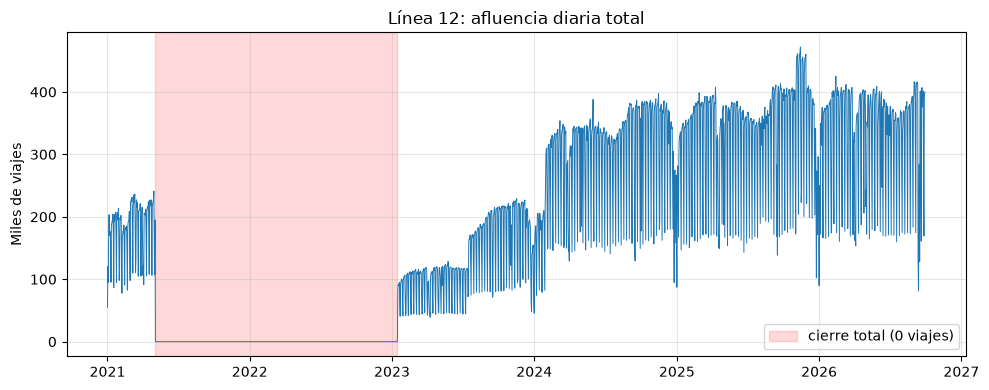

In [41]:
fig, ax = plt.subplots(figsize=(10, 4))
s = linea_dia[linea_dia["linea"] == "Línea 12"].set_index("fecha")["afluencia"] / 1e3
ax.plot(s.index, s.values, lw=.7)
ax.axvspan(pd.Timestamp("2021-05-04"), pd.Timestamp("2023-01-14"), alpha=.15, color="red",
           label="cierre total (0 viajes)")
ax.set_title("Línea 12: afluencia diaria total")
ax.set_ylabel("Miles de viajes"); ax.legend(); ax.grid(alpha=.3)
fig.tight_layout(); fig.savefig(OUT_FIG / "D2_ceros_linea12.png", dpi=150); plt.show()

### D3 · Ingresos del Metro: duplicados y faltantes

**Problema.** La tabla tiene 11 duplicados exactos (una carga repetida del 31 de agosto de 2022) y un conflicto en la llave: Línea 9, `QR/Validación`, aparece ese día con 14,435 y con 0. Eliminamos las copias exactas y conservamos el valor distinto de cero.

In [42]:
llave_ing = ["fecha", "linea", "tipo_ingreso"]
display(ingresos[ingresos.duplicated(llave_ing, keep=False)]
        .sort_values(llave_ing).head(6))

# 1) Duplicados exactos
n_dup = ingresos.duplicated().sum()
ingresos = ingresos.drop_duplicates()
log_decision("D3", "ingresos", "todas", "duplicado exacto (carga repetida 2022-08-31)",
             n_dup, "eliminar copia", "ninguna: la fila es idéntica")

# 2) Conflicto en la llave: conservar el registro distinto de cero
conflicto = ingresos.duplicated(llave_ing, keep=False)
n_conf = conflicto.sum()
ingresos = (ingresos.sort_values("ingreso", ascending=False, na_position="last")
                    .drop_duplicates(llave_ing, keep="first")
                    .sort_values(llave_ing).reset_index(drop=True))
log_decision("D3", "ingresos", "ingreso", "misma llave con dos valores (14,435 vs 0) dentro del bloque repetido",
             n_conf, "conservar el valor distinto de 0",
             "supone que el 0 viene de la carga repetida; afecta 1 día de 1 línea")

print("Duplicados restantes en la llave:", ingresos.duplicated(llave_ing).sum())

,fecha,tipo_ingreso,linea,ingreso
143892,2022-08-31,QR/Validación,Línea 1,0.0
143904,2022-08-31,QR/Validación,Línea 1,0.0
143903,2022-08-31,QR/Validación,Línea 12,0.0
143915,2022-08-31,QR/Validación,Línea 12,0.0
143893,2022-08-31,QR/Validación,Línea 2,0.0
143905,2022-08-31,QR/Validación,Línea 2,0.0


Duplicados restantes en la llave: 0


**Mecanismo de los faltantes.** Revisamos si los 1,067 faltantes de `ingreso` están dispersos al azar o concentrados.

In [43]:
# 3) Mecanismo de los faltantes: ¿al azar o concentrados?
ingresos["fecha"] = pd.to_datetime(ingresos["fecha"], format="%Y-%m-%d")
ingresos["falta_ingreso"] = ingresos["ingreso"].isna()
faltantes = ingresos[ingresos["falta_ingreso"]]
display(faltantes.groupby([faltantes["fecha"].dt.year.rename("anio"), "linea", "tipo_ingreso"])["fecha"]
        .agg(registros="count", desde="min", hasta="max"))

# ¿Qué reportó la Línea 12 en los meses vecinos al bloque de 2022?
l12 = ingresos[(ingresos["linea"] == "Línea 12") &
               ingresos["fecha"].between("2021-05-01", "2023-02-28")]
display(l12.groupby(l12["fecha"].dt.to_period("M"))["ingreso"]
        .agg(suma="sum", registros="count", faltantes=lambda x: x.isna().sum()).T)

registros      desde      hasta
anio linea    tipo_ingreso                                  
2012 Línea 12 Boletos              305 2012-01-01 2012-10-31
              Recargas             305 2012-01-01 2012-10-31
              Tarjetas             305 2012-01-01 2012-10-31
2022 Línea 12 QR/Validación         92 2022-03-01 2022-07-31
              Tarjetas              60 2022-03-01 2022-06-29

fecha,2021-05,2021-06,2021-07,2021-08,2021-09,2021-10,2021-11,2021-12,2022-01,2022-02,...,2022-05,2022-06,2022-07,2022-08,2022-09,2022-10,2022-11,2022-12,2023-01,2023-02
suma,2703062.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,6.535660e+06,1.167442e+07
registros,93.0,90.0,93.0,93.0,90.0,93.0,120.0,124.0,124.0,112.0,...,124.0,61.0,93.0,124.0,120.0,124.0,120.0,124.0,1.240000e+02,1.120000e+02
faltantes,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,59.0,31.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00,0.000000e+00


Los faltantes **no son al azar**: el 100 % son de la **Línea 12**, en 2012 (antes de su inauguración, a finales de octubre) y entre marzo y julio de 2022 (cuando estaba cerrada). Es una ausencia estructural: sabemos por qué falta el dato y que no hubo ingresos.

**Decisión.** No imputamos con la mediana ni con otras líneas, porque eso inventaría ingresos de una línea que no operaba. Conservamos el `NaN` y registramos el motivo en `motivo_faltante`. En las comparaciones por línea se excluyen los periodos de cierre, igual que en D2.

In [44]:
ingresos["motivo_faltante"] = np.select(
    [ingresos["falta_ingreso"] & (ingresos["fecha"].dt.year == 2012),
     ingresos["falta_ingreso"]],
    ["Línea 12 aún no inaugurada", "Línea 12 cerrada"],
    default="",
)
display(ingresos["motivo_faltante"].value_counts())

log_decision("D3", "ingresos", "ingreso",
             "100 % de los faltantes son de L12: antes de su apertura (2012) o durante su cierre (2022)",
             ingresos["falta_ingreso"].sum(),
             "no imputar; columna motivo_faltante; excluir cierres de L12 en comparaciones por línea",
             "no distingue entre 'no hubo ingreso' y 'no se registró', aunque el contexto indica lo primero")

motivo_faltante
                              158869
Línea 12 aún no inaugurada       915
Línea 12 cerrada                 152
Name: count, dtype: int64

### D4 · Viajes de Ecobici (enero 2026)

**Género.** Además de `M` y `F` aparecen `?`, `O` y vacíos. Los no reportados se agrupan como categoría explícita "No especificado" en lugar de imputarlos con la moda, que inflaría artificialmente la proporción masculina.

In [45]:
print(ecobici["Genero_Usuario"].value_counts(dropna=False))

# Género: categoría explícita en lugar de imputar con la moda
n_gen = (~ecobici["Genero_Usuario"].isin(["M", "F", "O"])).sum()
ecobici["genero"] = ecobici["Genero_Usuario"].map(
    {"M": "Masculino", "F": "Femenino", "O": "Otro"}).fillna("No especificado")
log_decision("D4", "ecobici", "Genero_Usuario", "'?' y faltante = el usuario no reportó género",
             n_gen, "categoría explícita 'No especificado' (no imputar con la moda)",
             "las proporciones por género se calculan con y sin esta categoría")

print("\nComparación: si imputáramos con la moda ('M'), la proporción masculina pasaría de",
      f"{(ecobici['genero'] == 'Masculino').mean():.1%} a",
      f"{((ecobici['genero'] == 'Masculino') | (ecobici['genero'] == 'No especificado')).mean():.1%}")

Genero_Usuario
M      1029960
F       418009
?        49853
O        27479
NaN          1
Name: count, dtype: int64

Comparación: si imputáramos con la moda ('M'), la proporción masculina pasaría de 67.5% a 70.8%


**Edad.** El criterio IQR marca como atípicos a los usuarios mayores de unos 58 años, que son ciclistas reales: aquí el IQR es una señal, no una regla. Las edades de 96 y 100 años se repiten más de lo esperable y probablemente son valores por defecto del registro; se marcan con `edad_atipica`, pero no se borran. Los 79 faltantes de edad solo quedan fuera de los análisis por edad.

In [46]:
# Edad: faltantes y extremos
edad = ecobici["Edad_Usuario"]
q1, q3 = edad.quantile([.25, .75]); ric = q3 - q1
lim_sup = q3 + 1.5 * ric
print(f"Faltantes: {edad.isna().sum()} | Q1={q1:.0f}, Q3={q3:.0f}, RIC={ric:.0f}, límite IQR superior={lim_sup:.0f}")
print(f"Por encima del límite IQR: {(edad > lim_sup).sum():,} ({(edad > lim_sup).mean():.2%})")
print(f"Mayores de 80: {(edad > 80).sum()} | distribución de los mayores de 90:",
      edad[edad > 90].value_counts().to_dict())

ecobici["edad_atipica"] = edad > 90
ecobici["rango_edad"] = pd.cut(edad, bins=[15, 24, 34, 44, 54, 64, 100],
                               labels=["16-24", "25-34", "35-44", "45-54", "55-64", "65+"])

log_decision("D4", "ecobici", "Edad_Usuario", "faltantes (79)", edad.isna().sum(),
             "no imputar; quedan fuera solo de los análisis por edad", "pérdida mínima (<0.01 %)")
log_decision("D4", "ecobici", "Edad_Usuario",
             "IQR marca muchos adultos mayores legítimos; >90 años concentrado en 96 y 100",
             ecobici["edad_atipica"].sum(),
             "conservar; bandera edad_atipica; rangos de edad con pd.cut",
             "96 y 100 parecen valores por defecto del registro, pero no es confirmable")

Faltantes: 79 | Q1=28, Q3=40, RIC=12, límite IQR superior=58
Por encima del límite IQR: 43,117 (2.83%)
Mayores de 80: 262 | distribución de los mayores de 90: {96.0: 12, 100.0: 6}


**Duración.** La duración no viene en los datos; la calculamos como arribo − retiro. La mediana es de unos 12 minutos y la distribución tiene una cola derecha muy larga.

In [47]:
# Duración del viaje (variable derivada)
# Las fechas ya se convirtieron a datetime en la sección 1; sumamos la hora
retiro = ecobici["Fecha_Retiro"] + pd.to_timedelta(ecobici["Hora_Retiro"].astype(str), errors="coerce")
arribo = ecobici["Fecha_Arribo"] + pd.to_timedelta(ecobici["Hora_Arribo"].astype(str), errors="coerce")
ecobici["fecha_retiro"] = retiro
ecobici["duracion_min"] = (arribo - retiro).dt.total_seconds() / 60

print(ecobici["duracion_min"].describe(percentiles=[.5, .9, .99, .999]).round(1))
print("Duración negativa:", (ecobici["duracion_min"] < 0).sum(),
      "| > 3 h:", (ecobici["duracion_min"] > 180).sum(),
      "| > 24 h:", (ecobici["duracion_min"] > 1440).sum())
print("Viajes retirados antes de enero 2026:", (retiro < "2026-01-01").sum(),
      "| el más antiguo:", retiro.min())

count    1525302.0
mean          15.7
std          275.8
min            0.2
50%           11.8
90%           30.2
99%           50.0
99.9%        108.4
max       257146.3
Name: duracion_min, dtype: float64
Duración negativa: 0 | > 3 h: 574 | > 24 h: 31
Viajes retirados antes de enero 2026: 105 | el más antiguo: 2025-08-02 23:24:30


**Decisión.** Distinguimos **errores confirmables** de **atípicos plausibles**. Excluimos con bandera los viajes de más de 24 horas (el máximo es de 178 días: una bicicleta no devuelta o un error de cierre) y los iniciados antes de enero de 2026. Los viajes largos pero posibles (1 a 3 horas) se conservan. Para graficar la duración usamos `log(1 + duración)`, que hace la distribución aproximadamente simétrica.

**Consecuencia.** Se excluyen 124 de 1.5 millones de viajes, así que ninguna proporción por género o edad cambia; lo que sí se corrige es la duración media, que con los registros imposibles estaría inflada.

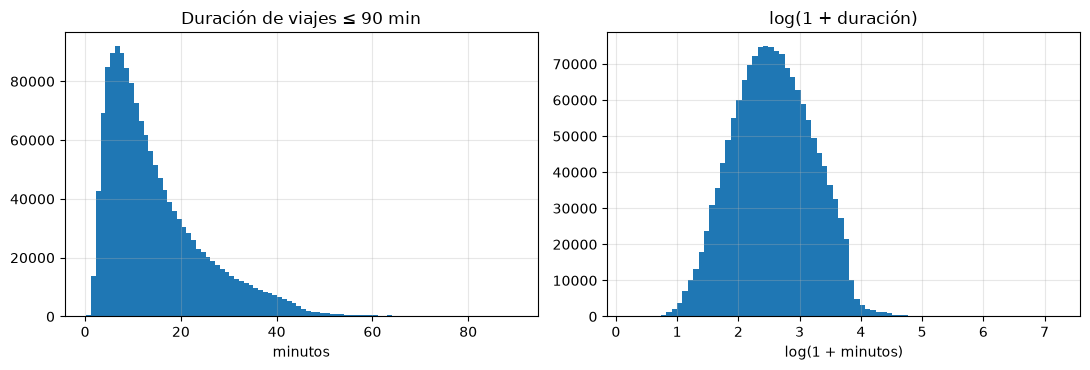

Viajes válidos para el análisis de enero: 1,525,178 de 1,525,302


In [48]:
# Error confirmable vs. atípico plausible
ecobici["duracion_imposible"] = ecobici["duracion_min"] > 1440     # bici fuera más de un día
ecobici["fuera_de_periodo"] = ecobici["fecha_retiro"] < "2026-01-01"

log_decision("D4", "ecobici", "duracion_min", "> 24 h: no es un viaje sino una bici no devuelta o error de cierre",
             ecobici["duracion_imposible"].sum(), "excluir de análisis de duración (bandera duracion_imposible)",
             "algún viaje real muy largo podría quedar fuera")
log_decision("D4", "ecobici", "Fecha_Retiro", "viajes retirados antes de 2026-01-01 que cerraron en enero",
             ecobici["fuera_de_periodo"].sum(), "excluir del análisis de enero (bandera fuera_de_periodo)",
             "el viaje de fin de año que cruza la medianoche del 31 de diciembre queda fuera")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
d = ecobici.loc[~ecobici["duracion_imposible"], "duracion_min"]
axes[0].hist(d[d <= 90], bins=90)
axes[0].set_title("Duración de viajes ≤ 90 min"); axes[0].set_xlabel("minutos")
axes[1].hist(np.log1p(d), bins=80)
axes[1].set_title("log(1 + duración)"); axes[1].set_xlabel("log(1 + minutos)")
for a in axes: a.grid(alpha=.3)
fig.tight_layout(); fig.savefig(OUT_FIG / "D4_duracion_ecobici.png", dpi=150); plt.show()

print(f"Viajes válidos para el análisis de enero: "
      f"{(~ecobici['duracion_imposible'] & ~ecobici['fuera_de_periodo']).sum():,} de {len(ecobici):,}")

### D5 · Un mes con el tipo de pago al revés
Al revisar qué proporción de pasajeros viaja gratis, febrero de 2025 sale muy distinto a los demás meses.

In [49]:
# Sumamos pasajeros por día y tipo de pago
diaria = metro.groupby(["fecha", "tipo_pago"])["afluencia"].sum().unstack()

# Calculamos el porcentaje de gratuidad y su mediana por mes
diaria["porcentaje_gratuidad"] = 100 * diaria["Gratuidad"] / diaria.sum(axis=1)
mensual = diaria.groupby(diaria.index.to_period("M"))["porcentaje_gratuidad"].median()
display(mensual.loc["2024-12":"2025-04"].round(1).to_frame("porcentaje_gratuidad_mediana"))

# Buscamos los días en que más de la mitad de los pasajeros aparece como gratuidad
dias_raros = diaria[diaria["porcentaje_gratuidad"] > 50]
print("Días con más de 50 % de gratuidad:", len(dias_raros))
print("Desde", dias_raros.index.min().date(), "hasta", dias_raros.index.max().date())

,porcentaje_gratuidad_mediana
fecha,
2024-12,12.7
2025-01,13.4
2025-02,87.2
2025-03,12.9
2025-04,13.1


Días con más de 50 % de gratuidad: 28
Desde 2025-02-01 hasta 2025-02-28


### Corrección
Intercambiamos las etiquetas solo en ese mes, sobre una copia `metro_corregido`, y dejamos una columna que indica qué filas se corrigieron. El total de pasajeros no debería cambiar.

In [50]:
# Copiamos la tabla para no modificar la original
metro_corregido = metro.copy()

# Marcamos las filas de febrero 2025 que vamos a corregir
feb_2025 = metro_corregido["fecha"].dt.to_period("M").eq("2025-02")
metro_corregido["tipo_pago_corregido"] = feb_2025 & metro_corregido["tipo_pago"].isin(["Gratuidad", "Prepago"])

# Intercambiamos Gratuidad y Prepago solo en ese mes
metro_corregido.loc[feb_2025, "tipo_pago"] = metro_corregido.loc[feb_2025, "tipo_pago"].replace(
    {"Gratuidad": "Prepago", "Prepago": "Gratuidad"})

# Verificamos que el total no cambie y que no haya duplicados
assert metro_corregido["afluencia"].sum() == metro["afluencia"].sum()
assert metro_corregido.duplicated(["fecha", "linea", "estacion", "tipo_pago"]).sum() == 0

# Revisamos otra vez los días con más de 50 % de gratuidad
revision = metro_corregido.groupby(["fecha", "tipo_pago"])["afluencia"].sum().unstack()
revision["porcentaje_gratuidad"] = 100 * revision["Gratuidad"] / revision.sum(axis=1)
print("Días con más de 50 % de gratuidad después de corregir:", (revision["porcentaje_gratuidad"] > 50).sum())
print("Filas corregidas:", metro_corregido["tipo_pago_corregido"].sum())

# Registramos la decisión
log_decision("D5", "metro", "tipo_pago",
                   "feb-2025: Gratuidad ≈ 87 % y Prepago ≈ 13 % en los 28 días y las 12 líneas (lo normal es al revés)",
                   metro_corregido["tipo_pago_corregido"].sum(),
                   "intercambiar las etiquetas Gratuidad/Prepago en ese mes; bandera tipo_pago_corregido",
                   "supone un error de captura de la fuente; el total de pasajeros no cambia")

# A partir de aquí la tabla del Metro ya lleva la corrección
metro = metro_corregido

Días con más de 50 % de gratuidad después de corregir: 0
Filas corregidas: 10920


### Transformaciones para el análisis

Creamos solo las variables que usamos después: día de la semana y tipo de día (laboral o fin de semana) para comparar patrones semanales; convertimos a número la afluencia histórica que venía como texto con comas de miles, y redondeamos los 57 conteos del Metrobús que tenían decimales.

In [51]:
DIAS = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]

def agregar_calendario(df, col_fecha="fecha"):
    df["dia_semana"] = pd.Categorical(df[col_fecha].dt.dayofweek.map(dict(enumerate(DIAS))),
                                      categories=DIAS, ordered=True)
    df["tipo_dia"] = np.where(df[col_fecha].dt.dayofweek >= 5, "Fin de semana", "Laboral")
    return df

metrobus["fecha"] = pd.to_datetime(metrobus["fecha"], format="%Y-%m-%d")
metro = agregar_calendario(metro)
metrobus = agregar_calendario(metrobus)
ecobici = agregar_calendario(ecobici, "fecha_retiro")
ecobici["hora_retiro"] = ecobici["fecha_retiro"].dt.hour

# Metrobús: afluencias no enteras (Línea 4, Prepago, enero 2025)
n_frac = (metrobus["afluencia"] % 1 != 0).sum()
metrobus["afluencia"] = metrobus["afluencia"].round().astype("int64")
log_decision("T", "metrobus", "afluencia", "57 conteos con decimales (L4, Prepago, ene-2025), probablemente estimados",
             n_frac, "redondear al entero", "el valor original pudo ser una estimación de la fuente")

# Afluencia histórica: texto con comas -> número
for col in ["afluencia_tarjeta", "afluencia_boleto", "afluencia_total_preliminar"]:
    historico[col] = pd.to_numeric(historico[col].astype(str).str.replace(",", "", regex=False),
                                   errors="coerce")
historico["fecha"] = pd.to_datetime(historico["fecha"], format="%Y-%m-%d")
log_decision("T", "historico", "afluencia_*", "números guardados como texto con comas de miles",
             len(historico), "convertir a numérico",
             "tarjeta/boleto faltan por estructura en organismos que no los distinguen; no se imputan")

display(historico.dtypes.to_frame("tipo"))

C:\Users\jgallegos\AppData\Local\Temp\ipykernel_13544\4045416696.py:4: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["dia_semana"] = pd.Categorical(df[col_fecha].dt.dayofweek.map(dict(enumerate(DIAS))),
C:\Users\jgallegos\AppData\Local\Temp\ipykernel_13544\4045416696.py:6: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["tipo_dia"] = np.where(df[col_fecha].dt.dayofweek >= 5, "Fin de semana", "Laboral")
C:\Users\jgallegos\AppData\Local\Temp\ipykernel_13544\4045416696.py:4: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["dia_semana"] = pd.Categorical(df[col_fecha].dt.dayofweek.map(dict(enumerate(DIAS))),
C:\Users\jgallegos\AppData\Local\Temp\ipykernel_13544\4045416696.py:6: Pandas4Warning: Series.dt.dayofweek is deprecated and will be remov

,tipo
id,int64
organismo,str
linea_servicio,str
dia,str
fecha,datetime64[us]
afluencia_tarjeta,float64
afluencia_boleto,float64
afluencia_total_preliminar,float64


### Bitácora y exportación

Guardamos la bitácora y las tablas limpias en `data/processed/`. Las tablas grandes van comprimidas (`.csv.gz`).

| # | Problema | Decisión | Consecuencia |
|---|---|---|---|
| D1 | Etiquetas de línea, estación y tipo de ingreso escritas de varias formas | Reparar la codificación y estandarizar | 24 → 12 líneas; las series dejan de cortarse en 2023 |
| D2 | Ceros por cierres del Metro | Conservar y marcar `en_servicio` | No se subestima la demanda de líneas que cerraron |
| D3 | Duplicados y faltantes en ingresos (solo L12) | Quitar duplicados; no imputar; registrar el motivo | No se inventan ingresos de una línea sin servicio |
| D4 | Género no reportado, edades extremas y duraciones imposibles en Ecobici | Categoría explícita; marcar atípicos; excluir errores confirmables | Proporciones y duración típica sin sesgo |
| D5 | Gratuidad y prepago intercambiados en febrero de 2025 | Intercambiar las etiquetas solo en ese mes | El % de gratuidad deja de tener un salto falso |

In [52]:
bitacora = pd.DataFrame(registro)
display(bitacora)

bitacora.to_csv(OUT_DATA / "bitacora_limpieza.csv", index=False)
metro.to_csv(OUT_DATA / "metro_limpio.csv.gz", index=False, compression="gzip")
metrobus.to_csv(OUT_DATA / "metrobus_limpio.csv", index=False)
ingresos.to_csv(OUT_DATA / "ingresos_limpio.csv.gz", index=False, compression="gzip")
historico.to_csv(OUT_DATA / "afluencia_historica_limpia.csv", index=False)
cols_eco = ["genero", "Edad_Usuario", "rango_edad", "edad_atipica", "Ciclo_Estacion_Retiro",
            "Ciclo_EstacionArribo", "fecha_retiro", "hora_retiro", "dia_semana", "tipo_dia",
            "duracion_min", "duracion_imposible", "fuera_de_periodo"]
ecobici[cols_eco].to_csv(OUT_DATA / "ecobici_2026_01_limpio.csv.gz", index=False, compression="gzip")

for f in sorted(OUT_DATA.iterdir()):
    print(f"{f.name:40s} {f.stat().st_size / 1e6:6.1f} MB")

,paso,tabla,variable,criterio,filas_afectadas,accion,limitacion
0,D1,metro,linea,mojibake y 'Linea' sin acento según el periodo,1227915,estandarizar a 'Línea X',ninguna: es la misma línea
1,D1,metro,estacion,mojibake y variantes de acentos/mayúsculas,396801,reparar codificación y unificar a la escritura...,la unificación supone que nombres iguales sin ...
2,D1,metrobus,linea,tres escrituras distintas según el periodo,6398,estandarizar a 'Línea X',ninguna
3,D1,ingresos,tipo_ingreso,'QR/Validador' renombrado por la fuente en dic...,2916,unificar en 'QR/Validación',supone que el cambio fue solo de nombre y no d...
4,D2,metro,afluencia,estación-día con afluencia total 0 = sin servi...,89292,conservar filas y crear bandera en_servicio; p...,una estación abierta con 0 accesos reales serí...
5,D3,ingresos,todas,duplicado exacto (carga repetida 2022-08-31),11,eliminar copia,ninguna: la fila es idéntica
6,D3,ingresos,ingreso,"misma llave con dos valores (14,435 vs 0) dent...",2,conservar el valor distinto de 0,supone que el 0 viene de la carga repetida; af...
7,D3,ingresos,ingreso,100 % de los faltantes son de L12: antes de su...,1067,no imputar; columna motivo_faltante; excluir c...,no distingue entre 'no hubo ingreso' y 'no se ...
8,D4,ecobici,Genero_Usuario,'?' y faltante = el usuario no reportó género,49854,categoría explícita 'No especificado' (no impu...,las proporciones por género se calculan con y ...
9,D4,ecobici,Edad_Usuario,faltantes (79),79,no imputar; quedan fuera solo de los análisis ...,pérdida mínima (<0.01 %)


afluencia_historica_limpia.csv              1.0 MB
bitacora_limpieza.csv                       0.0 MB
ecobici_2026_01_limpio.csv.gz              20.0 MB
ingresos_limpio.csv.gz                      0.9 MB
metro_limpio.csv.gz                         9.3 MB
metrobus_limpio.csv                         1.9 MB


## 3.2 Manipulación de los datos (transformación para el análisis)

Tomamos los datos limpios de la sección anterior y los **reorganizamos**
para responder nuestras preguntas, sin modificar los archivos originales.

Cada base cuenta los viajes de forma distinta: Metro por **estación y día**, Metrobús por **línea y día**, Ecobici por **viaje** individual. Compararlas así sería como comparar lo que pasa en una estación contra lo que pasa en una línea. Por eso primero las **sumamos a una misma medida** (por ejemplo, pasajeros por línea por día) y después las juntamos.

El resultado son tablas listas para la parte de estadística y de visualización.

### Contenido por tabla
Revisamos el contenido y el periodo de cada tabla limpia.

In [53]:
# Anotamos qué representa cada renglón y cuál es su columna de fecha
tablas = {"metro": (metro, "fecha", "estación × día × tipo de pago"),
          "metrobus": (metrobus, "fecha", "línea × día × tipo de pago"),
          "ingresos": (ingresos, "fecha", "línea × día × tipo de ingreso"),
          "historico": (historico, "fecha", "organismo/línea × día"),
          "ecobici": (ecobici, "fecha_retiro", "un viaje")}

# Armamos el inventario: filas, columnas y periodo de cada tabla
inventario = pd.DataFrame([
    {"tabla": nombre, "cada_renglon_es": unidad, "filas": len(tabla), "columnas": tabla.shape[1],
     "desde": tabla[columna_fecha].min().date(), "hasta": tabla[columna_fecha].max().date()}
    for nombre, (tabla, columna_fecha, unidad) in tablas.items()
])
display(inventario)

,tabla,cada_renglon_es,filas,columnas,desde,hasta
0,metro,estación × día × tipo de pago,1227915,11,2021-01-01,2026-09-30
1,metrobus,línea × día × tipo de pago,29386,8,2021-01-01,2026-09-30
2,ingresos,línea × día × tipo de ingreso,159936,6,2012-01-01,2023-07-31
3,historico,organismo/línea × día,18714,8,2020-03-01,2021-07-02
4,ecobici,un viaje,1525302,19,2025-08-02,2026-01-31


### Transformación del sistema del Metro
Cada renglón de Metro es una estación en un día. Para comparar líneas (y después con Metrobús e ingresos), sumamos todas las estaciones de cada línea. Los tipos de pago pasan a ser columnas.

In [54]:
# Sumamos pasajeros por línea, día y tipo de pago; cada tipo de pago queda como columna
pasajeros = (metro_corregido.groupby(["fecha", "linea", "tipo_pago"])["afluencia"].sum()
                            .unstack("tipo_pago")
                            .reset_index())
pasajeros.columns.name = None
pasajeros = pasajeros.rename(columns={"Boleto": "boleto", "Prepago": "prepago", "Gratuidad": "gratuidad"})

# Contamos cuántas estaciones tiene cada línea y cuántas abrieron ese día
estaciones = (metro_corregido.drop_duplicates(["fecha", "linea", "estacion"])
                             .groupby(["fecha", "linea"])
                             .agg(estaciones=("estacion", "size"),
                                  estaciones_abiertas=("en_servicio", "sum"))
                             .reset_index())

# Unimos ambas tablas y calculamos el total de pasajeros
metro_linea_dia = pasajeros.merge(estaciones, on=["fecha", "linea"], how="left", validate="one_to_one")
metro_linea_dia["total"] = metro_linea_dia[["boleto", "prepago", "gratuidad"]].sum(axis=1)

#### Conservación de pasajeros
El total de pasajeros antes y después tiene que ser idéntico.

In [55]:
# Verificamos que no haya duplicados ni se pierdan pasajeros
assert metro_linea_dia[["fecha", "linea"]].duplicated().sum() == 0
assert metro_linea_dia["total"].sum() == metro_corregido["afluencia"].sum()
assert len(metro_linea_dia) == metro_corregido["fecha"].nunique() * metro_corregido["linea"].nunique()

print("Filas antes:", len(metro_corregido), "- después:", len(metro_linea_dia))
print("Pasajeros antes:", metro_corregido["afluencia"].sum(), "- después:", metro_linea_dia["total"].sum())

# Registramos la decisión
log_decision("M1", "metro", "afluencia", "estación × día × tipo de pago → línea × día",
                   len(metro_corregido), "sumar estaciones; tipos de pago como columnas",
                   "se pierde el detalle por estación (sigue disponible en metro_corregido)")

Filas antes: 1227915 - después: 25188
Pasajeros antes: 6298847633 - después: 6298847633


#### Variables nuevas
- `linea_abierta`: la línea tuvo pasajeros ese día (si suma 0, estuvo cerrada).
- `cierre_parcial`: la línea operó, pero con alguna estación cerrada.
- `porcentaje_boleto`, `porcentaje_prepago`, `porcentaje_gratuidad`: qué porcentaje de los pasajeros pagó de cada forma (de 0 a 100). Si la línea estuvo cerrada, se deja vacío.
- `mes`, `dia_semana`, `tipo_dia`: para comparar por calendario.

In [56]:
# Marcamos si la línea abrió y si tuvo alguna estación cerrada
metro_linea_dia["linea_abierta"] = metro_linea_dia["total"].gt(0)
metro_linea_dia["cierre_parcial"] = (metro_linea_dia["linea_abierta"]
                                     & metro_linea_dia["estaciones_abiertas"].lt(metro_linea_dia["estaciones"]))

# Calculamos el porcentaje de cada tipo de pago (vacío si la línea estuvo cerrada)
for tipo in ["boleto", "prepago", "gratuidad"]:
    metro_linea_dia[f"porcentaje_{tipo}"] = np.where(metro_linea_dia["total"].gt(0),
                                                     100 * metro_linea_dia[tipo] / metro_linea_dia["total"], np.nan)

# Agregamos mes, día de la semana y tipo de día
metro_linea_dia["mes"] = metro_linea_dia["fecha"].dt.to_period("M").astype("string")
metro_linea_dia = agregar_calendario(metro_linea_dia)
display(metro_linea_dia.head())

C:\Users\jgallegos\AppData\Local\Temp\ipykernel_13544\4045416696.py:4: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["dia_semana"] = pd.Categorical(df[col_fecha].dt.dayofweek.map(dict(enumerate(DIAS))),
C:\Users\jgallegos\AppData\Local\Temp\ipykernel_13544\4045416696.py:6: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["tipo_dia"] = np.where(df[col_fecha].dt.dayofweek >= 5, "Fin de semana", "Laboral")


,fecha,linea,boleto,gratuidad,prepago,estaciones,estaciones_abiertas,total,linea_abierta,cierre_parcial,porcentaje_boleto,porcentaje_prepago,porcentaje_gratuidad,mes,dia_semana,tipo_dia
0,2021-01-01,Línea 1,69381,13533,46664,20,20,129578,True,False,53.543811,36.012286,10.443903,2021-01,Viernes,Laboral
1,2021-01-01,Línea 12,0,15390,39226,20,20,54616,True,False,0.000000,71.821444,28.178556,2021-01,Viernes,Laboral
2,2021-01-01,Línea 2,39314,13143,39425,24,24,91882,True,False,42.787488,42.908295,14.304216,2021-01,Viernes,Laboral
3,2021-01-01,Línea 3,41833,11587,43300,21,21,96720,True,False,43.251654,44.768404,11.979942,2021-01,Viernes,Laboral
4,2021-01-01,Línea 4,7168,2919,4199,10,10,14286,True,False,50.174997,29.392412,20.432591,2021-01,Viernes,Laboral


#### Resumen por línea
La mediana de pasajeros se calcula solo con los días en que la línea estuvo abierta,
para no mezclar cierres con días normales (decisión D2 de la limpieza).

In [57]:
# Resumimos cada línea en días, cierres y gratuidad
resumen_lineas = (metro_linea_dia.groupby("linea")
                                 .agg(dias=("fecha", "size"),
                                      dias_cerrada=("linea_abierta", lambda s: int((~s).sum())),
                                      dias_cierre_parcial=("cierre_parcial", "sum"),
                                      mediana_porcentaje_gratuidad=("porcentaje_gratuidad", "median")))

# Calculamos la mediana de pasajeros usando solo los días en que la línea abrió
dias_abiertos = metro_linea_dia.loc[metro_linea_dia["linea_abierta"]]
resumen_lineas["mediana_pasajeros_abierta"] = dias_abiertos.groupby("linea")["total"].median()
display(resumen_lineas.sort_values("mediana_pasajeros_abierta", ascending=False).round(1))

,dias,dias_cerrada,dias_cierre_parcial,mediana_porcentaje_gratuidad,mediana_pasajeros_abierta
linea,,,,,
Línea 2,2099,30,293,11.9,556664.0
Línea 3,2099,23,39,12.0,472032.0
Línea B,2099,0,2,12.8,346372.0
Línea 8,2099,0,1,13.1,336828.0
Línea 12,2099,621,382,11.7,255976.5
Línea 1,2099,16,1293,17.3,250024.0
Línea 9,2099,0,279,9.5,242935.0
Línea 7,2099,0,141,10.1,216958.0
Línea A,2099,0,0,11.3,206580.0


### Metrobús por línea y día
Metrobús ya viene por línea y día, así que solo pasamos los tipos de pago a columnas.
Metrobús no registra Boleto a diferencia del metro.

In [58]:
# Pasamos los tipos de pago a columnas
metrobus_linea_dia = (metrobus.pivot_table(index=["fecha", "linea"], columns="tipo_pago",
                                           values="afluencia", aggfunc="sum")
                              .reset_index())
metrobus_linea_dia.columns.name = None
metrobus_linea_dia = metrobus_linea_dia.rename(columns={"Prepago": "prepago", "Gratuidad": "gratuidad"})

# Calculamos el total y el porcentaje de gratuidad
metrobus_linea_dia["total"] = metrobus_linea_dia["prepago"] + metrobus_linea_dia["gratuidad"]
metrobus_linea_dia["porcentaje_gratuidad"] = 100 * metrobus_linea_dia["gratuidad"] / metrobus_linea_dia["total"]

# Verificamos que no haya duplicados ni se pierdan pasajeros
assert metrobus_linea_dia[["fecha", "linea"]].duplicated().sum() == 0
assert metrobus_linea_dia["total"].sum() == metrobus["afluencia"].sum()
print("Filas antes:", len(metrobus), "- después:", len(metrobus_linea_dia))
print("Celdas vacías:", metrobus_linea_dia.isna().sum().sum())

Filas antes: 29386 - después: 14693
Celdas vacías: 0


#### Metro y Metrobús en una misma tabla
Sumamos todas las líneas de cada sistema por día. Así cada renglón es un sistema en un día
y ambos quedan en la misma medida para compararlos.

In [59]:
# Sumamos todas las líneas de cada sistema por día y juntamos ambos sistemas
sistemas_dia = pd.concat([
    metro_linea_dia.groupby("fecha")[["prepago", "gratuidad", "boleto"]].sum().assign(sistema="Metro"),
    metrobus_linea_dia.groupby("fecha")[["prepago", "gratuidad"]].sum().assign(boleto=0, sistema="Metrobús"),
]).reset_index()

# Calculamos el total, el porcentaje de gratuidad y el calendario
sistemas_dia["total"] = sistemas_dia[["prepago", "gratuidad", "boleto"]].sum(axis=1)
sistemas_dia["porcentaje_gratuidad"] = 100 * sistemas_dia["gratuidad"] / sistemas_dia["total"]
sistemas_dia["mes"] = sistemas_dia["fecha"].dt.to_period("M").astype("string")
sistemas_dia = agregar_calendario(sistemas_dia)

# Verificamos que cada sistema aparezca una sola vez por día
assert sistemas_dia[["fecha", "sistema"]].duplicated().sum() == 0

# Comparamos días laborales contra fines de semana
display(sistemas_dia.groupby(["sistema", "tipo_dia"])
                    .agg(dias=("fecha", "size"), mediana_pasajeros=("total", "median"),
                         mediana_porcentaje_gratuidad=("porcentaje_gratuidad", "median")).round(1))

# Registramos la decisión
log_decision("M2", "metro + metrobus", "afluencia", "unir ambos sistemas a sistema × día",
                   len(sistemas_dia), "sumar líneas; boleto = 0 en Metrobús porque no existe",
                   "Metrobús no distingue boleto; comparar tipo de pago solo con prepago y gratuidad")

C:\Users\jgallegos\AppData\Local\Temp\ipykernel_13544\4045416696.py:4: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["dia_semana"] = pd.Categorical(df[col_fecha].dt.dayofweek.map(dict(enumerate(DIAS))),
C:\Users\jgallegos\AppData\Local\Temp\ipykernel_13544\4045416696.py:6: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["tipo_dia"] = np.where(df[col_fecha].dt.dayofweek >= 5, "Fin de semana", "Laboral")


dias  mediana_pasajeros  mediana_porcentaje_gratuidad
sistema  tipo_dia                                                            
Metro    Fin de semana   600          2076753.5                          11.9
         Laboral        1499          3455312.0                          12.4
Metrobús Fin de semana   600           833927.5                           6.5
         Laboral        1499          1542818.0                           6.2

### Ingresos y pasajeros del Metro (2021–2023)
Los ingresos solo existen hasta julio de 2023 y los pasajeros desde enero de 2021, así que trabajamos
en el periodo que comparten. Usamos **meses** y no días. Una recarga de tarjeta se compra un día
y se gasta en muchos viajes después, por lo que día con día los ingresos y los viajes no coinciden.

In [60]:
fecha_inicio, fecha_fin = "2021-01-01", "2023-07-31"

# Filtramos los ingresos al periodo que comparten ambas bases
ingresos_periodo = ingresos.loc[ingresos["fecha"].between(fecha_inicio, fecha_fin)].copy()
ingresos_periodo["mes"] = ingresos_periodo["fecha"].dt.to_period("M").astype("string")

# Sumamos los ingresos por línea y mes; cada tipo de ingreso queda como columna
ingresos_mes = (ingresos_periodo.pivot_table(index=["linea", "mes"], columns="tipo_ingreso",
                                             values="ingreso", aggfunc="sum", fill_value=0)
                                .reset_index())
ingresos_mes.columns.name = None
ingresos_mes = ingresos_mes.rename(columns={"Boletos": "ingreso_boletos", "Recargas": "ingreso_recargas",
                                            "Tarjetas": "ingreso_tarjetas", "QR/Validación": "ingreso_qr"})
ingresos_mes["ingreso_total"] = ingresos_mes[["ingreso_boletos", "ingreso_recargas",
                                              "ingreso_tarjetas", "ingreso_qr"]].sum(axis=1)

# Sumamos los pasajeros por línea y mes en el mismo periodo
pasajeros_mes = (metro_linea_dia.loc[metro_linea_dia["fecha"].between(fecha_inicio, fecha_fin)]
                                .groupby(["linea", "mes"])
                                .agg(pasajeros=("total", "sum"), boleto=("boleto", "sum"),
                                     prepago=("prepago", "sum"), gratuidad=("gratuidad", "sum"),
                                     dias_abierta=("linea_abierta", "sum"))
                                .reset_index())
pasajeros_mes["pagantes"] = pasajeros_mes["boleto"] + pasajeros_mes["prepago"]

#### Unión segura
Ambas tablas tienen ahora la misma medida (línea × mes), así que cada renglón debe encontrar
exactamente una pareja. `indicator` nos muestra si algún renglón se quedó sin pareja

In [61]:
# Unimos ambas tablas y revisamos si algún renglón quedó sin pareja
ingresos_pasajeros = pasajeros_mes.merge(ingresos_mes, on=["linea", "mes"], how="outer",
                                         validate="one_to_one", indicator=True)
display(ingresos_pasajeros["_merge"].value_counts().to_frame("filas"))
assert ingresos_pasajeros["_merge"].eq("both").all()

# Quitamos la columna de revisión
ingresos_pasajeros = ingresos_pasajeros.drop(columns="_merge")

,filas
_merge,
both,372
left_only,0
right_only,0


#### Ingreso por pasajero que paga
Dividimos el ingreso entre los pasajeros que pagan (Boleto + Prepago; la gratuidad no genera ingreso).
Si las bases cuadran, el resultado debe estar cerca de la tarifa del Metro: **$5**.
Los meses en que la Línea 12 estuvo cerrada quedan vacíos.

In [62]:
# Marcamos los meses en que la línea estuvo cerrada
ingresos_pasajeros["linea_cerrada"] = ingresos_pasajeros["dias_abierta"].eq(0)

# Calculamos el ingreso por pasajero que paga (vacío si no hubo pagantes)
ingresos_pasajeros["ingreso_por_pagante"] = np.where(ingresos_pasajeros["pagantes"].gt(0),
                                                     ingresos_pasajeros["ingreso_total"] / ingresos_pasajeros["pagantes"],
                                                     np.nan)
print("Meses-línea cerrados:", ingresos_pasajeros["linea_cerrada"].sum())
display(ingresos_pasajeros.groupby("linea")["ingreso_por_pagante"]
                          .describe()[["count", "min", "50%", "max"]].round(2))

# Sumamos todo el Metro por mes (tabla principal de la pregunta 3)
metro_ingresos_mes = (ingresos_pasajeros.groupby("mes")[["pasajeros", "pagantes", "gratuidad",
                                                         "ingreso_boletos", "ingreso_recargas", "ingreso_tarjetas",
                                                         "ingreso_qr", "ingreso_total"]]
                                        .sum().reset_index())
metro_ingresos_mes["ingreso_por_pagante"] = metro_ingresos_mes["ingreso_total"] / metro_ingresos_mes["pagantes"]
display(metro_ingresos_mes.head())

# Registramos la decisión
log_decision("M3", "ingresos + metro", "ingreso", "unir ingresos y pasajeros por línea × mes (ene-2021 a jul-2023)",
                   len(ingresos_pasajeros), "agregar por mes; ingreso_por_pagante = ingreso / (boleto + prepago)",
                   "la recarga se vende en una línea y puede usarse en otra: comparar por línea con cautela")

Meses-línea cerrados: 19


,count,min,50%,max
linea,,,,
Línea 1,31.0,4.56,5.22,5.61
Línea 12,12.0,5.44,5.80,6.67
Línea 2,31.0,4.97,5.40,5.74
Línea 3,31.0,4.84,5.31,5.73
Línea 4,31.0,3.40,5.16,5.66
Línea 5,31.0,4.54,4.82,5.30
Línea 6,31.0,3.60,4.29,4.49
Línea 7,31.0,5.30,5.86,6.13
Línea 8,31.0,4.52,4.98,5.28


,mes,pasajeros,pagantes,gratuidad,ingreso_boletos,ingreso_recargas,ingreso_tarjetas,ingreso_qr,ingreso_total,ingreso_por_pagante
0,2021-01,41033642,36287874,4745768,47454875.0,1.440367e+08,1484355.0,0.0,1.929760e+08,5.317918
1,2021-02,50436321,46141886,4294435,64846325.0,1.786339e+08,1705425.0,0.0,2.451857e+08,5.313733
2,2021-03,65449779,60433657,5016122,85644965.0,2.264336e+08,2241675.0,0.0,3.143203e+08,5.201080
3,2021-04,62577359,57661064,4916295,82950270.0,2.087748e+08,2150445.0,0.0,2.938756e+08,5.096603
4,2021-05,62689975,56985969,5704006,94883350.0,1.894670e+08,1648830.0,0.0,2.859992e+08,5.018766


### Ecobici: de viaje individual a día y hora
Cada renglón de Ecobici es un viaje. Primero quitamos los viajes marcados en la limpieza
(más de 24 h o iniciados antes de enero) y después contamos cuántos viajes hubo por
día, hora, género y rango de eda

In [63]:
# Filtramos los viajes válidos según las banderas de la limpieza
validos = ~ecobici["duracion_imposible"] & ~ecobici["fuera_de_periodo"]
ecobici_validos = ecobici.loc[validos].copy()
print("Viajes válidos:", len(ecobici_validos), "de", len(ecobici))
print("Viajes excluidos:", (~validos).sum())

# Separamos el día y conservamos a quienes no tienen edad registrada
ecobici_validos["fecha"] = ecobici_validos["fecha_retiro"].dt.normalize()
ecobici_validos["rango_edad"] = ecobici_validos["rango_edad"].astype("string").fillna("Sin edad")

# Contamos viajes y duración mediana por día, hora, género y edad
ecobici_hora = (ecobici_validos.groupby(["fecha", "hora_retiro", "genero", "rango_edad"])
                               .agg(viajes=("duracion_min", "size"),
                                    duracion_mediana=("duracion_min", "median"))
                               .reset_index())

# Agregamos día de la semana y tipo de día
ecobici_hora = agregar_calendario(ecobici_hora)

# Verificamos que no se pierdan viajes ni haya duplicados
assert ecobici_hora["viajes"].sum() == len(ecobici_validos)
assert ecobici_hora.duplicated(["fecha", "hora_retiro", "genero", "rango_edad"]).sum() == 0
print("Renglones resultantes:", len(ecobici_hora))

# Registramos la decisión
log_decision("M4", "ecobici", "viajes", "viaje → día × hora × género × rango de edad",
                   len(ecobici_validos), "excluir banderas D4 y contar viajes; mediana de duración por grupo",
                   "se pierde el detalle por estación; enero 2026 no permite ver estacionalidad")

Viajes válidos: 1525178 de 1525302
Viajes excluidos: 124
Renglones resultantes: 12995


C:\Users\jgallegos\AppData\Local\Temp\ipykernel_13544\4045416696.py:4: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["dia_semana"] = pd.Categorical(df[col_fecha].dt.dayofweek.map(dict(enumerate(DIAS))),
C:\Users\jgallegos\AppData\Local\Temp\ipykernel_13544\4045416696.py:6: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["tipo_dia"] = np.where(df[col_fecha].dt.dayofweek >= 5, "Fin de semana", "Laboral")


#### Viajes promedio por hora
Dividimos entre el número de días de cada tipo (22 laborales y 9 de fin de semana),
porque si no, los días laborales parecerían más usados solo por ser más.

In [64]:
# Sumamos los viajes por hora y tipo de día
viajes_por_hora = ecobici_hora.pivot_table(index="hora_retiro", columns="tipo_dia", values="viajes", aggfunc="sum")

# Dividimos entre el número de días de cada tipo para obtener el promedio diario
viajes_por_hora = viajes_por_hora / ecobici_hora.groupby("tipo_dia")["fecha"].nunique()
display(viajes_por_hora.round(0).astype(int).T)

hora_retiro,0,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
tipo_dia,,,,,,,,,,,,,,,,,,,,
Fin de semana,262,120,362,777,1369,1984,2526,2913,3087,3104,2862,2644,2332,2138,1943,1610,1337,1088,825,539
Laboral,153,461,1552,3234,4349,3180,2373,2248,2408,3027,3777,3918,3829,4735,5289,4041,2813,2052,1318,733


#### Los tres sistemas en enero 2026
Enero 2026 es el único mes en que tenemos Metro, Metrobús y Ecobici al mismo tiempo.
Juntamos sus viajes por día en una sola tabla.

In [65]:
# Contamos los viajes de Ecobici por día
ecobici_dia = ecobici_validos.groupby("fecha").size().rename("total").reset_index().assign(sistema="Ecobici")

# Juntamos los tres sistemas en enero 2026
enero_2026 = pd.concat([sistemas_dia.loc[sistemas_dia["mes"].eq("2026-01"), ["fecha", "sistema", "total"]],
                        ecobici_dia], ignore_index=True)
enero_2026 = agregar_calendario(enero_2026)
assert enero_2026[["fecha", "sistema"]].duplicated().sum() == 0

# Comparamos la mediana de fin de semana contra la de día laboral
comparacion = enero_2026.pivot_table(index="sistema", columns="tipo_dia", values="total", aggfunc="median")
comparacion["finde_entre_laboral"] = comparacion["Fin de semana"] / comparacion["Laboral"]
display(comparacion.round(2))

C:\Users\jgallegos\AppData\Local\Temp\ipykernel_13544\4045416696.py:4: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["dia_semana"] = pd.Categorical(df[col_fecha].dt.dayofweek.map(dict(enumerate(DIAS))),
C:\Users\jgallegos\AppData\Local\Temp\ipykernel_13544\4045416696.py:6: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["tipo_dia"] = np.where(df[col_fecha].dt.dayofweek >= 5, "Fin de semana", "Laboral")


tipo_dia,Fin de semana,Laboral,finde_entre_laboral
sistema,,,
Ecobici,34438.0,59092.5,0.58
Metro,2815078.0,3731433.0,0.75
Metrobús,996497.0,1546643.5,0.64


### Guardar resultados
Guardamos las tablas en `data/analitica/` con nombres que empiezan con `tabla_`, para distinguirlas
de los datos limpios. La bitácora va en un archivo aparte, así no se modifica la de la limpieza.

In [66]:
# Creamos la carpeta donde guardamos las tablas analíticas
carpeta_salida = ROOT / "data" / "analitica"
carpeta_salida.mkdir(parents=True, exist_ok=True)


# Definimos qué tabla va en cada archivo y para qué pregunta sirve
salidas = {
    "tabla_metro_linea_dia.csv":              (metro_linea_dia,    "línea del Metro × día",              "P1"),
    "tabla_metrobus_linea_dia.csv":           (metrobus_linea_dia, "línea del Metrobús × día",           "P1"),
    "tabla_sistemas_dia.csv":                 (sistemas_dia,       "sistema (Metro/Metrobús) × día",     "P1"),
    "tabla_ingresos_pasajeros_linea_mes.csv": (ingresos_pasajeros, "línea del Metro × mes (2021–2023)",  "P3"),
    "tabla_metro_ingresos_mes.csv":           (metro_ingresos_mes, "todo el Metro × mes (2021–2023)",    "P3"),
    "tabla_ecobici_dia_hora.csv":             (ecobici_hora,       "día × hora × género × edad",         "P2"),
    "tabla_enero_2026_sistemas.csv":          (enero_2026,         "sistema (los tres) × día, ene-2026", "P2"),
}

# Guardamos cada tabla y anotamos su tamaño
resumen_salidas = []
for archivo, (tabla, unidad, pregunta) in salidas.items():
    tabla.to_csv(carpeta_salida / archivo, index=False)
    resumen_salidas.append({"archivo": archivo, "cada_renglon_es": unidad, "pregunta": pregunta,
                            "filas": len(tabla), "columnas": tabla.shape[1]})
display(pd.DataFrame(resumen_salidas))

,archivo,cada_renglon_es,pregunta,filas,columnas
0,tabla_metro_linea_dia.csv,línea del Metro × día,P1,25188,16
1,tabla_metrobus_linea_dia.csv,línea del Metrobús × día,P1,14693,6
2,tabla_sistemas_dia.csv,sistema (Metro/Metrobús) × día,P1,4198,10
3,tabla_ingresos_pasajeros_linea_mes.csv,línea del Metro × mes (2021–2023),P3,372,15
4,tabla_metro_ingresos_mes.csv,todo el Metro × mes (2021–2023),P3,31,10
5,tabla_ecobici_dia_hora.csv,día × hora × género × edad,P2,12995,8
6,tabla_enero_2026_sistemas.csv,"sistema (los tres) × día, ene-2026",P2,93,5


#### Bitácora completa
Unimos las decisiones de limpieza (D1–D5, T) con las de manipulación (M1–M4) para tener todo el recorrido.

In [67]:
# Guardamos la bitácora de manipulación en un archivo aparte
bitacora_completa = pd.DataFrame(registro)
bitacora_manipulacion = bitacora_completa[bitacora_completa["paso"].str.startswith("M")]
bitacora_manipulacion.to_csv(carpeta_salida / "bitacora_manipulacion.csv", index=False)

# Mostramos la bitácora completa: limpieza y manipulación
display(bitacora_completa[["paso", "tabla", "variable", "accion"]])

,paso,tabla,variable,accion
0,D1,metro,linea,estandarizar a 'Línea X'
1,D1,metro,estacion,reparar codificación y unificar a la escritura...
2,D1,metrobus,linea,estandarizar a 'Línea X'
3,D1,ingresos,tipo_ingreso,unificar en 'QR/Validación'
4,D2,metro,afluencia,conservar filas y crear bandera en_servicio; p...
5,D3,ingresos,todas,eliminar copia
6,D3,ingresos,ingreso,conservar el valor distinto de 0
7,D3,ingresos,ingreso,no imputar; columna motivo_faltante; excluir c...
8,D4,ecobici,Genero_Usuario,categoría explícita 'No especificado' (no impu...
9,D4,ecobici,Edad_Usuario,no imputar; quedan fuera solo de los análisis ...


#### Resumen

Cátalogo de archivos creados:

| Tema | Archivo | Cada renglón es |
|:--|:--|:--|
| Tipo de pago | tabla_metro_linea_dia.csv | una línea del Metro en un día |
| Tipo de pago | tabla_metrobus_linea_dia.csv | una línea del Metrobús en un día |
| Tipo de pago | tabla_sistemas_dia.csv | un sistema (Metro o Metrobús) en un día |
| Ecobici | tabla_ecobici_dia_hora.csv | un grupo de género y edad en una hora de un día |
| Ecobici | tabla_enero_2026_sistemas.csv | un sistema (los tres) en un día de enero 2026 |
| Ingresos | tabla_metro_ingresos_mes.csv | todo el Metro en un mes (2021–2023) |
| Ingresos | tabla_ingresos_pasajeros_linea_mes.csv | una línea del Metro en un mes (2021–2023) |

Cada tabla conserva el total de pasajeros o viajes de su fuente (lo verificamos con `assert`).

# 4. Visualización de datos

Las visualizaciones están organizadas por **pregunta de investigación**. Cada gráfica se acompaña de su interpretación (qué muestra), su relevancia (por qué importa para la pregunta) y sus limitaciones. Al final se incluyen gráficas de contexto que ayudan a interpretar los resultados.

| Sección | Pregunta | Gráficas |
|---|---|---|
| 4.1 | P1 · Tipo de pago en Metro y Metrobús | 1 – 3 |
| 4.2 | P2 · Ecobici por género, edad y hora | 4 – 6 |
| 4.3 | P3 · Ingresos y afluencia del Metro | 7 – 8 |
| 4.4 | Contexto adicional | 9 – 14 |

### Preparación de los datos

In [68]:
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 50)

COL = {'verde':'#2A9D8F','azul':'#457B9D','amarillo':'#E9C46A','naranja':'#F4A261','rojo':'#E76F51','morado':'#7B6DCC'}

# Las tablas metro, metrobus, historico e ingresos ya están limpias (sección de limpieza).
# Solo agregamos el mes como fecha para las series mensuales.
for df in (metro, metrobus, historico, ingresos):
    df['mes_calc'] = df['fecha'].dt.to_period('M').dt.to_timestamp()

print(f"Cobertura Metro: {metro['fecha'].min().date()} a {metro['fecha'].max().date()}")

Cobertura Metro: 2021-01-01 a 2026-09-30


In [71]:
plt.rcParams.update({'figure.figsize':(11,5.5),'axes.titlesize':14,'axes.labelsize':11,'figure.dpi':110})

# Archivos de Ecobici que no se usaron en la limpieza (misma carpeta DATA_DIR)
ARCHIVOS = {
    'estaciones': DATA_DIR / 'Ubicación de estaciones ecobici.csv',
    'diarios': DATA_DIR / 'Viajes diarios del sistema Ecobici.csv',
    'mensuales': DATA_DIR / 'Viajes mensuales desglosados del sistema Ecobici.csv',
}

In [72]:
diarios = pd.read_csv(ARCHIVOS['diarios'], low_memory=False)
mensuales = pd.read_csv(ARCHIVOS['mensuales'], low_memory=False)
estaciones = pd.read_csv(ARCHIVOS['estaciones'], low_memory=False)

diarios['fecha'] = pd.to_datetime(diarios['fecha'], errors='coerce')
diarios['genero'] = diarios['genero'].fillna('No especificado')
dias_es = {0:'Lunes',1:'Martes',2:'Miércoles',3:'Jueves',4:'Viernes',5:'Sábado',6:'Domingo'}

mensuales['fecha_corte'] = pd.to_datetime(mensuales['fecha_corte'], errors='coerce')
mensuales['genero'] = mensuales['genero'].fillna('No especificado')
mensuales['hora_num'] = pd.to_numeric(mensuales['hora'].astype(str).str.extract(r'(^\d{1,2})')[0], errors='coerce')
mensuales['rango_edad_std'] = (mensuales['rango_edad'].astype('string').str.replace(r'\s*-\s*','-',regex=True).str.strip().fillna('No especificado'))

estaciones['estacion_id'] = pd.to_numeric(estaciones['num_cicloestacion'], errors='coerce').astype('Int64').astype('string')
# Identificador y descripción para etiquetar las estaciones en los gráficos.
# Si el catálogo no incluye un nombre, se utiliza el identificador.
columnas_nombre = [c for c in estaciones.columns if c.lower() in {
    'nombre', 'nombre_estacion', 'nombre_cicloestacion', 'cicloestacion',
    'estacion', 'direccion', 'ubicacion', 'ubicación'
}]
if columnas_nombre:
    nombre_map = (estaciones.dropna(subset=['estacion_id'])
                  .drop_duplicates('estacion_id')
                  .set_index('estacion_id')[columnas_nombre[0]]
                  .astype('string').to_dict())
else:
    nombre_map = {}


resumen = pd.DataFrame({'fuente':['Viajes diarios','Viajes mensuales','Estaciones'],
                        'filas':[len(diarios),len(mensuales),len(estaciones)],
                        'columnas':[diarios.shape[1],mensuales.shape[1],estaciones.shape[1]]})
display(resumen)


,fuente,filas,columnas
0,Viajes diarios,12261,5
1,Viajes mensuales,115773,9
2,Estaciones,480,12


In [73]:
# Viajes de enero 2026: usamos los viajes válidos de la limpieza (sin duraciones > 24 h ni retiros antes de enero)
def id_est(s): return pd.to_numeric(s, errors='coerce').astype('Int64').astype('string')

detalle = ecobici_validos.copy()
detalle['origen_id'] = id_est(detalle['Ciclo_Estacion_Retiro'])
detalle['destino_id'] = id_est(detalle['Ciclo_EstacionArribo'])
print('Viajes de enero 2026 usados:', len(detalle))

Viajes de enero 2026 usados: 1525178


## 4.1 P1 · Tipo de pago en el Metro y el Metrobús

### Gráfica 1 - barras apiladas al 100 % · Composición de los accesos por tipo de pago y año

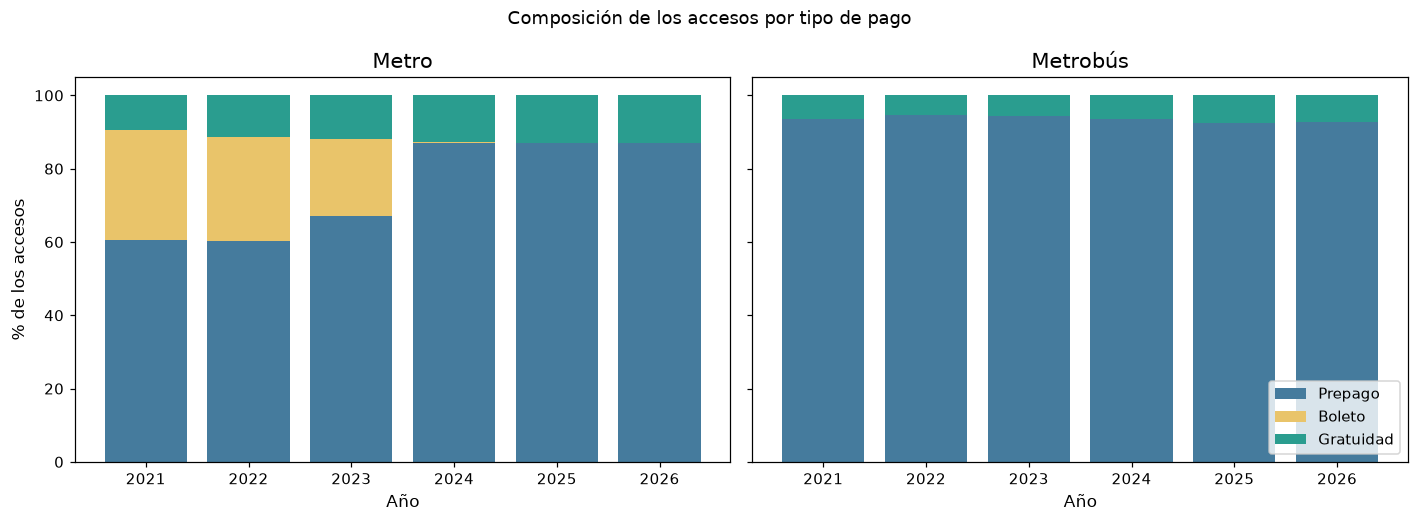

**Interpretación.** En el Metro el boleto pasa de **30.1 %** de los accesos en 2021 a **0.0 %** en 2025, y el prepago sube de 60.6 % a 87.0 %: el pago se trasladó casi por completo a tarjeta. La gratuidad crece poco, de 9.3 % a 13.0 %. En el Metrobús, que no tiene boleto, la gratuidad se mantiene entre 5.3 % y 7.5 %.  
**Relevancia.** Responde directamente cómo se distribuyen los pasajeros por tipo de pago y cómo ha cambiado.  
**Limitación.** El cambio coincide con la eliminación del boleto, pero los datos no permiten afirmar por qué cambió la forma de pago; 2026 solo tiene datos hasta septiembre.

In [74]:
pago_anio = (sistemas_dia.assign(anio=sistemas_dia["fecha"].dt.year)
             .groupby(["sistema", "anio"])[["boleto", "prepago", "gratuidad"]].sum())
pago_anio_pct = pago_anio.div(pago_anio.sum(axis=1), axis=0) * 100

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
colores = {"boleto": COL["amarillo"], "prepago": COL["azul"], "gratuidad": COL["verde"]}
for ax, sistema in zip(axes, ["Metro", "Metrobús"]):
    d = pago_anio_pct.xs(sistema)
    abajo = np.zeros(len(d))
    for tipo in ["prepago", "boleto", "gratuidad"]:
        ax.bar(d.index.astype(str), d[tipo], bottom=abajo, color=colores[tipo], label=tipo.capitalize())
        abajo += d[tipo].values
    ax.set(title=sistema, xlabel="Año")
axes[0].set_ylabel("% de los accesos"); axes[1].legend(loc="lower right")
fig.suptitle("Composición de los accesos por tipo de pago")
plt.tight_layout(); plt.show()

m = pago_anio_pct.xs("Metro"); mb = pago_anio_pct.xs("Metrobús")
display(Markdown(
    f"**Interpretación.** En el Metro el boleto pasa de **{m.loc[2021, 'boleto']:.1f} %** de los accesos en 2021 a "
    f"**{m.loc[2025, 'boleto']:.1f} %** en 2025, y el prepago sube de {m.loc[2021, 'prepago']:.1f} % a {m.loc[2025, 'prepago']:.1f} %: "
    f"el pago se trasladó casi por completo a tarjeta. La gratuidad crece poco, de {m.loc[2021, 'gratuidad']:.1f} % a "
    f"{m.loc[2025, 'gratuidad']:.1f} %. En el Metrobús, que no tiene boleto, la gratuidad se mantiene entre "
    f"{mb['gratuidad'].min():.1f} % y {mb['gratuidad'].max():.1f} %.  \n"
    "**Relevancia.** Responde directamente cómo se distribuyen los pasajeros por tipo de pago y cómo ha cambiado.  \n"
    "**Limitación.** El cambio coincide con la eliminación del boleto, pero los datos no permiten afirmar por qué cambió "
    "la forma de pago; 2026 solo tiene datos hasta septiembre."
))

### Gráfica 2 · Porcentaje de gratuidad por línea

**Tipo:** barras horizontales ordenadas. Se usan solo los días en que la línea operó (decisión D2) y los datos ya corregidos de febrero de 2025 (D5).

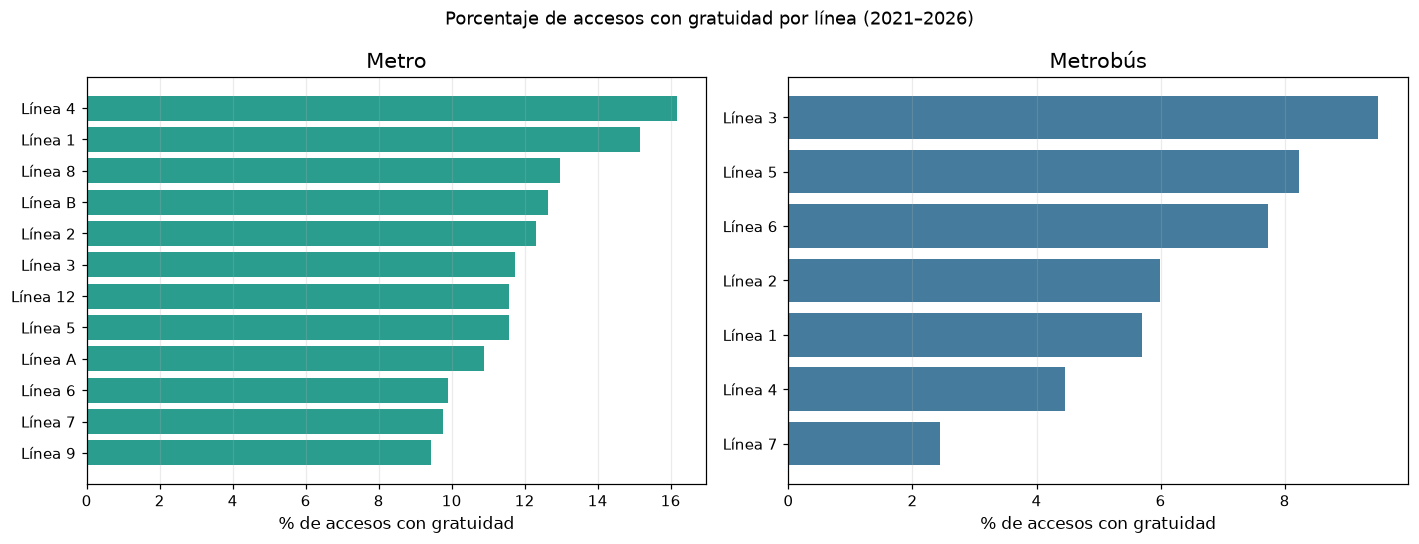

**Interpretación.** En el Metro la gratuidad va de **9.4 %** (Línea 9) a **16.2 %** (Línea 4); en el Metrobús, de **2.4 %** (Línea 7) a **9.5 %** (Línea 3). En promedio, la proporción de accesos gratuitos en el Metro es casi el doble que en el Metrobús.  
**Relevancia.** Muestra que la composición por tipo de pago no es homogénea entre líneas.  
**Limitación.** La gratuidad agrupa a varios grupos (personas mayores, con discapacidad, niños, etc.) que los datos no distinguen, y no sabemos si las diferencias se deben al perfil de los usuarios o a la ubicación de las líneas.

In [75]:
def pct_gratuidad_linea(df):
    t = df.groupby("linea")[["gratuidad", "total"]].sum()
    return (100 * t["gratuidad"] / t["total"]).sort_values()

g_metro = pct_gratuidad_linea(metro_linea_dia[metro_linea_dia["linea_abierta"]])
g_mb = pct_gratuidad_linea(metrobus_linea_dia)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].barh(g_metro.index, g_metro.values, color=COL["verde"]); axes[0].set(title="Metro", xlabel="% de accesos con gratuidad")
axes[1].barh(g_mb.index, g_mb.values, color=COL["azul"]); axes[1].set(title="Metrobús", xlabel="% de accesos con gratuidad")
for ax in axes: ax.grid(axis="x", alpha=.25)
fig.suptitle("Porcentaje de accesos con gratuidad por línea (2021–2026)")
plt.tight_layout(); plt.show()

display(Markdown(
    f"**Interpretación.** En el Metro la gratuidad va de **{g_metro.min():.1f} %** ({g_metro.idxmin()}) a "
    f"**{g_metro.max():.1f} %** ({g_metro.idxmax()}); en el Metrobús, de **{g_mb.min():.1f} %** ({g_mb.idxmin()}) a "
    f"**{g_mb.max():.1f} %** ({g_mb.idxmax()}). En promedio, la proporción de accesos gratuitos en el Metro es casi el "
    "doble que en el Metrobús.  \n"
    "**Relevancia.** Muestra que la composición por tipo de pago no es homogénea entre líneas.  \n"
    "**Limitación.** La gratuidad agrupa a varios grupos (personas mayores, con discapacidad, niños, etc.) que los datos "
    "no distinguen, y no sabemos si las diferencias se deben al perfil de los usuarios o a la ubicación de las líneas."
))

### Gráfica 3 · Gratuidad en días laborales y fines de semana

**Tipo:** diagramas de caja del % diario de gratuidad, para comparar centro y dispersión entre tipos de día.

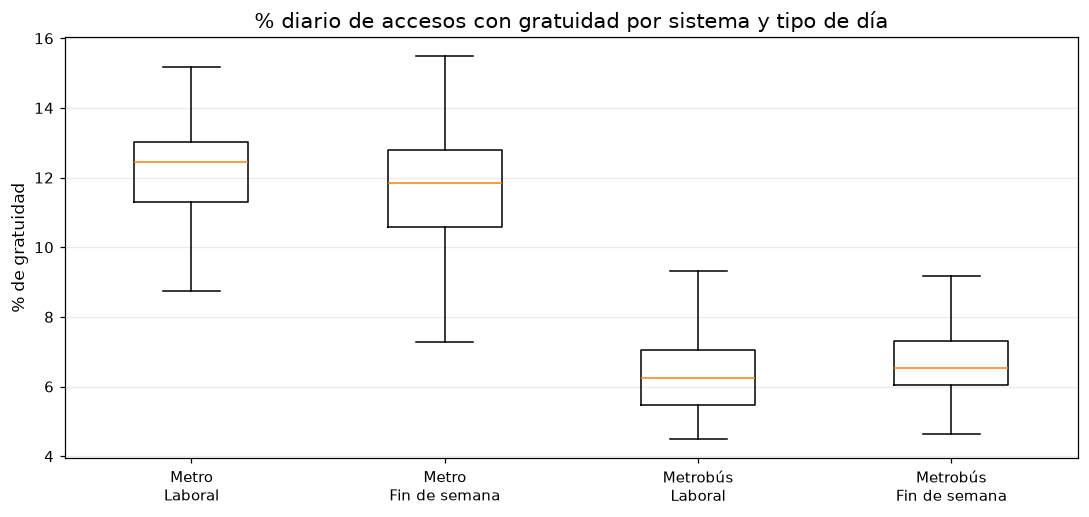

**Interpretación.** La mediana del % de gratuidad en el Metro es **12.4 %** en días laborales y **11.9 %** en fines de semana; en el Metrobús, **6.2 %** y **6.5 %**. La diferencia entre tipos de día es pequeña frente a la diferencia entre sistemas.  
**Relevancia.** Descarta que la composición por tipo de pago dependa mucho del día de la semana.  
**Limitación.** Se ocultan los atípicos (cierres, días festivos) para que las cajas sean legibles.

In [76]:
fig, ax = plt.subplots(figsize=(10, 4.8))
grupos, etiquetas = [], []
for sistema in ["Metro", "Metrobús"]:
    for tipo in ["Laboral", "Fin de semana"]:
        d = sistemas_dia[(sistemas_dia["sistema"] == sistema) & (sistemas_dia["tipo_dia"] == tipo)]
        grupos.append(d["porcentaje_gratuidad"].dropna()); etiquetas.append(f"{sistema}\n{tipo}")
ax.boxplot(grupos, showfliers=False)
ax.set_xticks(range(1, len(etiquetas) + 1), etiquetas)
ax.set(title="% diario de accesos con gratuidad por sistema y tipo de día", ylabel="% de gratuidad"); ax.grid(axis="y", alpha=.25)
plt.tight_layout(); plt.show()

med = sistemas_dia.groupby(["sistema", "tipo_dia"])["porcentaje_gratuidad"].median()
display(Markdown(
    f"**Interpretación.** La mediana del % de gratuidad en el Metro es **{med[('Metro', 'Laboral')]:.1f} %** en días laborales y "
    f"**{med[('Metro', 'Fin de semana')]:.1f} %** en fines de semana; en el Metrobús, **{med[('Metrobús', 'Laboral')]:.1f} %** y "
    f"**{med[('Metrobús', 'Fin de semana')]:.1f} %**. La diferencia entre tipos de día es pequeña frente a la diferencia entre sistemas.  \n"
    "**Relevancia.** Descarta que la composición por tipo de pago dependa mucho del día de la semana.  \n"
    "**Limitación.** Se ocultan los atípicos (cierres, días festivos) para que las cajas sean legibles."
))

## 4.2 P2 · Patrones de uso de Ecobici por género, edad y hora

### Gráfica 4 · Viajes de enero 2026 por rango de edad y género

**Tipo:** barras apiladas: el largo muestra cuántos viajes hace cada rango de edad y los colores la composición por género.

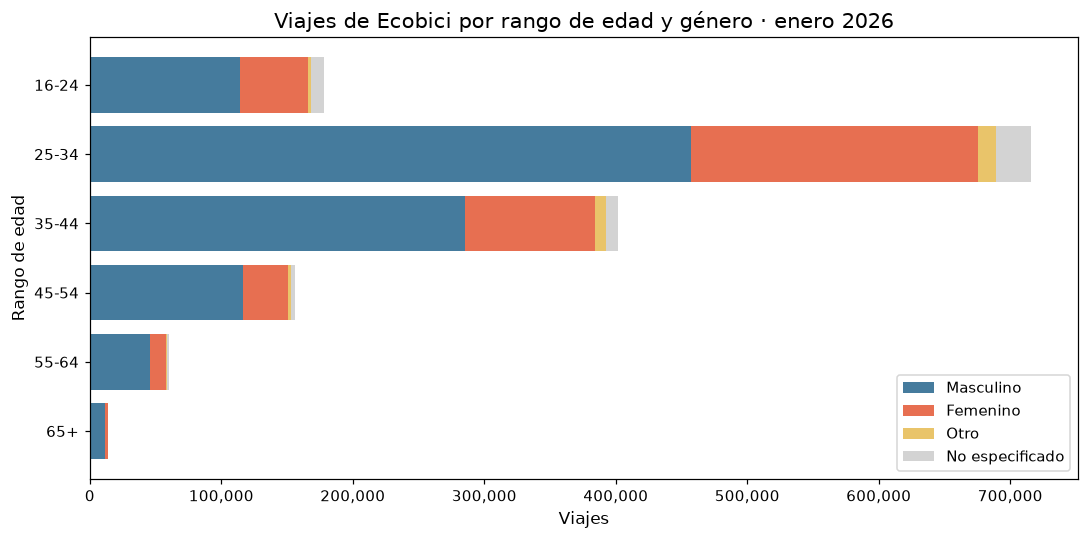

**Interpretación.** El **67.5 %** de los viajes los hacen hombres y el **27.4 %** mujeres. El rango de **25 a 34 años** concentra el **46.9 %** de los viajes. La participación femenina baja con la edad: es **29.0 %** entre los usuarios de 16-24 años y **15.4 %** entre los de 65+.  
**Relevancia.** Describe quién usa Ecobici y muestra que la brecha de género crece con la edad.  
**Limitación.** Se cuentan viajes, no personas: un usuario frecuente pesa más. El género y la edad son los registrados al darse de alta.

In [77]:
ge = (ecobici_validos[ecobici_validos["rango_edad"] != "Sin edad"]
      .groupby(["rango_edad", "genero"]).size().unstack(fill_value=0))
orden_gen = [g for g in ["Masculino", "Femenino", "Otro", "No especificado"] if g in ge.columns]
ge = ge[orden_gen]

fig, ax = plt.subplots(figsize=(10, 5))
izq = np.zeros(len(ge))
for gen, color in zip(orden_gen, [COL["azul"], COL["rojo"], COL["amarillo"], "lightgray"]):
    ax.barh(ge.index, ge[gen], left=izq, color=color, label=gen); izq += ge[gen].values
ax.set(title="Viajes de Ecobici por rango de edad y género · enero 2026", xlabel="Viajes", ylabel="Rango de edad")
ax.xaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}")); ax.legend(); ax.invert_yaxis()
plt.tight_layout(); plt.show()

pct_gen = 100 * ecobici_validos["genero"].value_counts(normalize=True)
pct_edad = 100 * ecobici_validos["rango_edad"].value_counts(normalize=True)
fem = 100 * ge["Femenino"] / ge.sum(axis=1)
display(Markdown(
    f"**Interpretación.** El **{pct_gen['Masculino']:.1f} %** de los viajes los hacen hombres y el **{pct_gen['Femenino']:.1f} %** mujeres. "
    f"El rango de **25 a 34 años** concentra el **{pct_edad['25-34']:.1f} %** de los viajes. La participación femenina baja con la edad: "
    f"es **{fem.iloc[0]:.1f} %** entre los usuarios de {fem.index[0]} años y **{fem.iloc[-1]:.1f} %** entre los de {fem.index[-1]}.  \n"
    "**Relevancia.** Describe quién usa Ecobici y muestra que la brecha de género crece con la edad.  \n"
    "**Limitación.** Se cuentan viajes, no personas: un usuario frecuente pesa más. El género y la edad son los registrados al darse de alta."
))

### Gráfica 5 · Viajes promedio por hora en enero 2026, por género y tipo de día

**Tipo:** líneas por hora. Se usa el promedio por día (22 laborales y 9 de fin de semana) para que los dos tipos de día sean comparables.

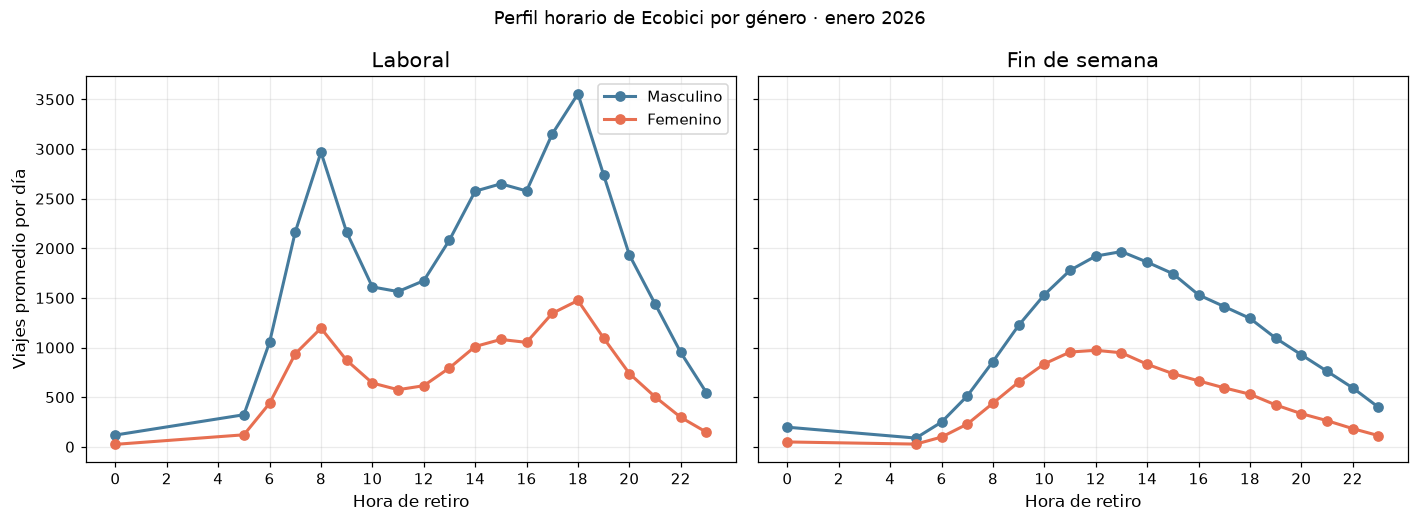

**Interpretación.** En días laborales el uso tiene dos picos, en la mañana y en la tarde; el máximo es a las **18:00** para hombres y a las **18:00** para mujeres, un patrón típico de traslados al trabajo o la escuela. En fines de semana el uso es más plano y el máximo se mueve a mediodía (**13:00** y **12:00**). Hombres y mujeres siguen el mismo perfil horario; lo que cambia es el volumen.  
**Relevancia.** Muestra que la diferencia por género está en cuántos viajes se hacen, no en a qué hora.  
**Limitación.** Es un solo mes (con vacaciones y el 1 de enero como día festivo), así que no permite hablar de estacionalidad; para eso se usa el histórico en las gráficas siguientes.

In [78]:
dias_tipo = ecobici_hora.groupby("tipo_dia")["fecha"].nunique()
hg = (ecobici_hora[ecobici_hora["genero"].isin(["Masculino", "Femenino"])]
      .groupby(["tipo_dia", "genero", "hora_retiro"])["viajes"].sum().reset_index())
hg["promedio"] = hg["viajes"] / hg["tipo_dia"].map(dias_tipo)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
picos = {}
for ax, tipo in zip(axes, ["Laboral", "Fin de semana"]):
    for gen, color in [("Masculino", COL["azul"]), ("Femenino", COL["rojo"])]:
        d = hg[(hg["tipo_dia"] == tipo) & (hg["genero"] == gen)]
        ax.plot(d["hora_retiro"], d["promedio"], marker="o", lw=2, color=color, label=gen)
        picos[(tipo, gen)] = int(d.loc[d["promedio"].idxmax(), "hora_retiro"])
    ax.set(title=tipo, xlabel="Hora de retiro"); ax.set_xticks(range(0, 24, 2)); ax.grid(alpha=.25)
axes[0].set_ylabel("Viajes promedio por día"); axes[0].legend()
fig.suptitle("Perfil horario de Ecobici por género · enero 2026")
plt.tight_layout(); plt.show()

display(Markdown(
    f"**Interpretación.** En días laborales el uso tiene dos picos, en la mañana y en la tarde; el máximo es a las "
    f"**{picos[('Laboral', 'Masculino')]}:00** para hombres y a las **{picos[('Laboral', 'Femenino')]}:00** para mujeres, "
    f"un patrón típico de traslados al trabajo o la escuela. En fines de semana el uso es más plano y el máximo se mueve a "
    f"mediodía (**{picos[('Fin de semana', 'Masculino')]}:00** y **{picos[('Fin de semana', 'Femenino')]}:00**). "
    "Hombres y mujeres siguen el mismo perfil horario; lo que cambia es el volumen.  \n"
    "**Relevancia.** Muestra que la diferencia por género está en cuántos viajes se hacen, no en a qué hora.  \n"
    "**Limitación.** Es un solo mes (con vacaciones y el 1 de enero como día festivo), así que no permite hablar de estacionalidad; "
    "para eso se usa el histórico en las gráficas siguientes."
))

La siguiente gráfica usa el **histórico 2010–2024** de Ecobici para poner en contexto el mes de enero de 2026: qué días de la semana concentran más viajes. La comparación por género con el histórico se presenta en la sección 5.

---
### Gráfica 6 · En 2024, ¿qué días de la semana concentran más viajes diarios?

**Tipo:** barras con promedio diario por día de la semana.


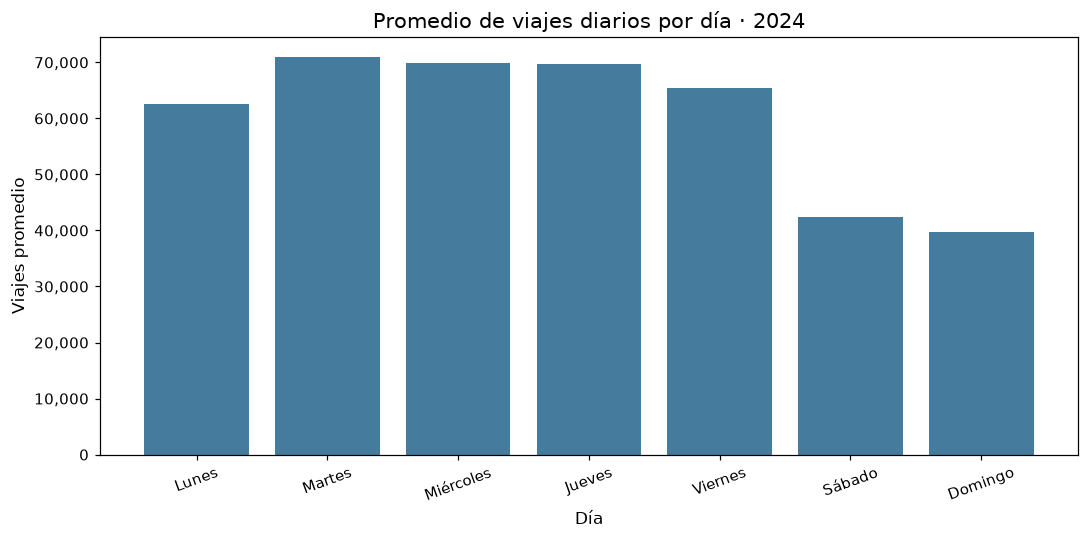

**Interpretación.** **Martes** presenta el mayor promedio (70,947) y **Domingo** el menor (39,650); la diferencia es **78.9%**.  
**Relevancia.** Distingue patrones laborales y de fin de semana.  
**Limitación.** La cobertura para 2024 debe verificarse: su última fecha registrada es 2024-07-31. Días festivos y días sin registro pueden modificar el promedio.

In [79]:
d2024=diarios[diarios.fecha.dt.year.eq(2024)].groupby('fecha',as_index=False).viajes.sum(); d2024['dia_num']=d2024.fecha.dt.dayofweek; d2024['dia']=d2024.dia_num.map(dias_es)
w=d2024.groupby(['dia_num','dia'],as_index=False).viajes.mean().sort_values('dia_num')
fig,ax=plt.subplots(figsize=(10,5)); ax.bar(w.dia,w.viajes,color=COL['azul']); ax.set(title='Promedio de viajes diarios por día · 2024',xlabel='Día',ylabel='Viajes promedio'); ax.tick_params(axis='x',rotation=20); ax.yaxis.set_major_formatter(mtick.StrMethodFormatter('{x:,.0f}')); plt.tight_layout(); plt.show()
a=w.loc[w.viajes.idxmax()]; b=w.loc[w.viajes.idxmin()]; pct=(a.viajes/b.viajes-1)*100
display(Markdown(f"""**Interpretación.** **{a.dia}** presenta el mayor promedio ({a.viajes:,.0f}) y **{b.dia}** el menor ({b.viajes:,.0f}); la diferencia es **{pct:.1f}%**.  
**Relevancia.** Distingue patrones laborales y de fin de semana.  
**Limitación.** La cobertura para 2024 debe verificarse: su última fecha registrada es {d2024.fecha.max().date() if not d2024.empty else "no disponible"}. Días festivos y días sin registro pueden modificar el promedio."""))


## 4.3 P3 · Ingresos y afluencia del Metro

### Gráfica 7 · Evolución conjunta de afluencia e ingresos del Metro
**¿Cuál es la evolución conjunta entre la afluencia del Metro y los ingresos reportados por el STC?**

Las dos fuentes no cubren exactamente el mismo periodo. Por ello se agregan por mes y se restringe el análisis al **intervalo temporal común** antes de comparar.


Periodo común: 2021-01 a 2023-07 | 31 meses


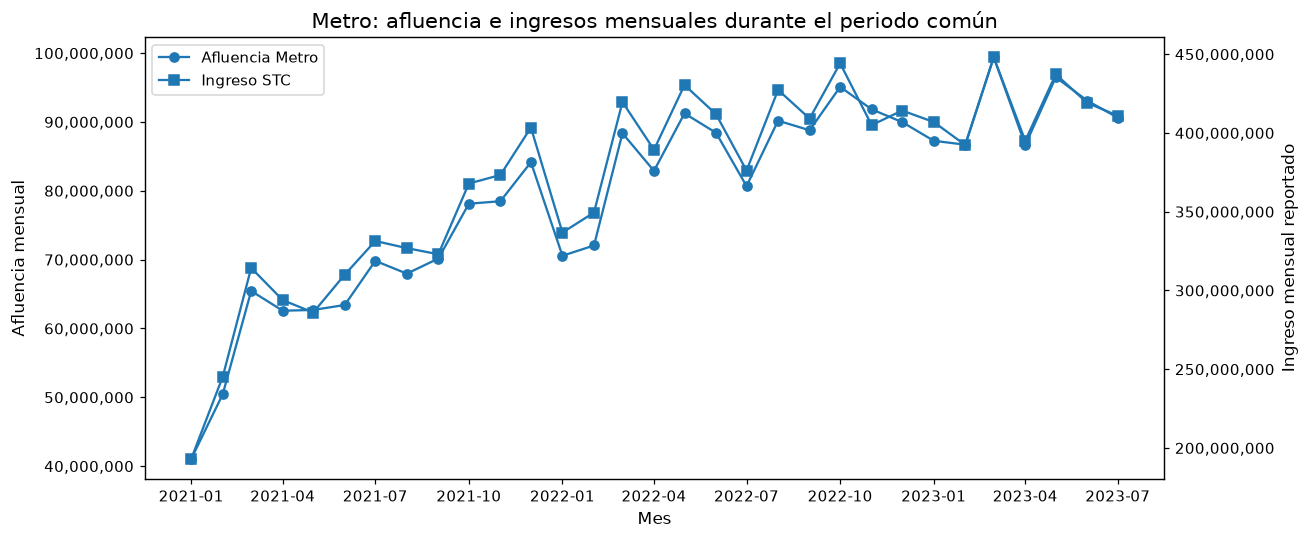

**Interpretación.** Durante el periodo común, la correlación de Pearson entre afluencia e ingreso mensual es **r = 0.991**.  
**Relevancia.** Permite evaluar si los meses de mayor utilización tienden a coincidir con mayores ingresos reportados.  
**Limitación.** La asociación no demuestra causalidad y puede estar afectada por tarifas, gratuidades, recargas anticipadas, descuentos e inflación.

In [80]:
# Usamos la tabla mensual ya unida y verificada en la manipulación (metro_ingresos_mes)
comun = (metro_ingresos_mes.assign(mes_calc=pd.to_datetime(metro_ingresos_mes['mes']))
                           .rename(columns={'pasajeros': 'afluencia_metro'})
                           .sort_values('mes_calc'))

print(f"Periodo común: {comun['mes_calc'].min():%Y-%m} a {comun['mes_calc'].max():%Y-%m} | {len(comun)} meses")

fig, ax1 = plt.subplots(figsize=(12, 5))
ax1.plot(comun['mes_calc'], comun['afluencia_metro'], marker='o', label='Afluencia Metro')
ax1.set_xlabel('Mes')
ax1.set_ylabel('Afluencia mensual')
ax1.yaxis.set_major_formatter(mtick.StrMethodFormatter('{x:,.0f}'))

ax2 = ax1.twinx()
ax2.plot(comun['mes_calc'], comun['ingreso_total'], marker='s', label='Ingreso STC')
ax2.set_ylabel('Ingreso mensual reportado')
ax2.yaxis.set_major_formatter(mtick.StrMethodFormatter('{x:,.0f}'))
ax2.grid(False)
ax1.set_title('Metro: afluencia e ingresos mensuales durante el periodo común')

h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc='upper left')
plt.tight_layout()
plt.show()

corr_total = comun[['afluencia_metro', 'ingreso_total']].corr().iloc[0, 1]
display(Markdown(
    f"**Interpretación.** Durante el periodo común, la correlación de Pearson entre afluencia e ingreso mensual es "
    f"**r = {corr_total:.3f}**.  \n"
    "**Relevancia.** Permite evaluar si los meses de mayor utilización tienden a coincidir con mayores ingresos reportados.  \n"
    "**Limitación.** La asociación no demuestra causalidad y puede estar afectada por tarifas, gratuidades, recargas anticipadas, descuentos e inflación."
))


### Gráfica 8 · Relación mes a mes entre afluencia e ingreso

**Tipo:** diagrama de dispersión (relación entre dos variables numéricas) y serie del ingreso por acceso pagado.

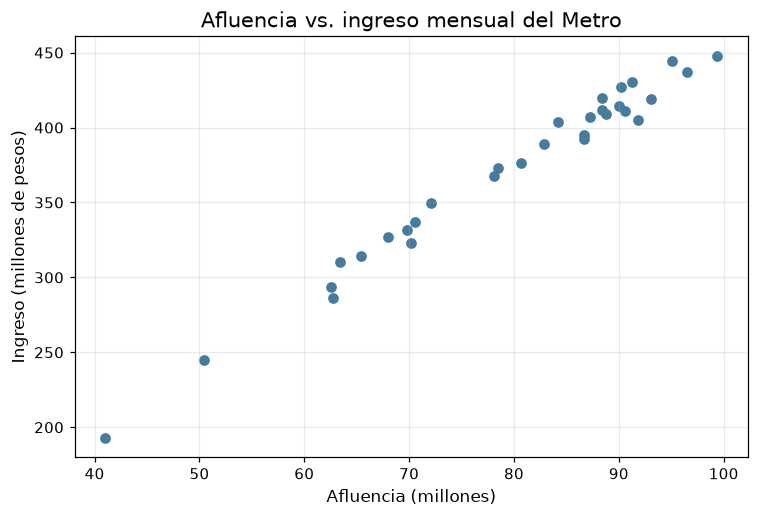

**Interpretación.** La relación es casi perfectamente lineal: **r = 0.991 (Pearson)** y **ρ = 0.969 (Spearman)**. El ingreso por acceso pagado se mantiene entre **5.00** y **5.42 pesos**, muy cerca de la tarifa de 5 pesos, lo que indica que ambas bases son consistentes entre sí.  
**Relevancia.** Responde P3: los ingresos se mueven prácticamente igual que la afluencia de pago.  
**Limitación.** La correlación es alta casi por construcción, porque con tarifa fija el ingreso es aproximadamente tarifa × accesos pagados; no demuestra que haya otros factores detrás. Solo hay 31 meses en común.

In [81]:
# Relación mes a mes: afluencia vs. ingreso del Metro
fig, ax = plt.subplots(figsize=(7, 4.8))
ax.scatter(comun["afluencia_metro"] / 1e6, comun["ingreso_total"] / 1e6, color=COL["azul"])
ax.set(title="Afluencia vs. ingreso mensual del Metro",
       xlabel="Afluencia (millones)", ylabel="Ingreso (millones de pesos)")
ax.grid(alpha=.25)
plt.tight_layout(); plt.show()


# Correlaciones que se reportan en la interpretación
r_p = comun[["afluencia_metro", "ingreso_total"]].corr(method="pearson").iloc[0, 1]
r_s = comun[["afluencia_metro", "ingreso_total"]].corr(method="spearman").iloc[0, 1]
ipp = comun["ingreso_por_pagante"]
display(Markdown(
    f"**Interpretación.** La relación es casi perfectamente lineal: **r = {r_p:.3f} (Pearson)** y **ρ = {r_s:.3f} (Spearman)**. "
    f"El ingreso por acceso pagado se mantiene entre **{ipp.min():.2f}** y **{ipp.max():.2f} pesos**, muy cerca de la tarifa de 5 pesos, "
    "lo que indica que ambas bases son consistentes entre sí.  \n"
    "**Relevancia.** Responde P3: los ingresos se mueven prácticamente igual que la afluencia de pago.  \n"
    "**Limitación.** La correlación es alta casi por construcción, porque con tarifa fija el ingreso es aproximadamente "
    "tarifa × accesos pagados; no demuestra que haya otros factores detrás. Solo hay 31 meses en común."
))

## 4.4 Contexto adicional

Estas gráficas no responden directamente las tres preguntas, pero ayudan a interpretarlas: qué líneas y estaciones concentran la demanda, cómo evolucionan los sistemas en el tiempo y cómo está distribuida la infraestructura de Ecobici.

### Gráfica 9 · Líneas con mayor afluencia diaria
**¿Qué líneas concentran la mayor afluencia diaria promedio en cada sistema?**

Se utiliza el **promedio diario por línea** en vez del acumulado total. Así se reduce el sesgo que introducirían diferencias en la cantidad de días disponibles por línea o año.


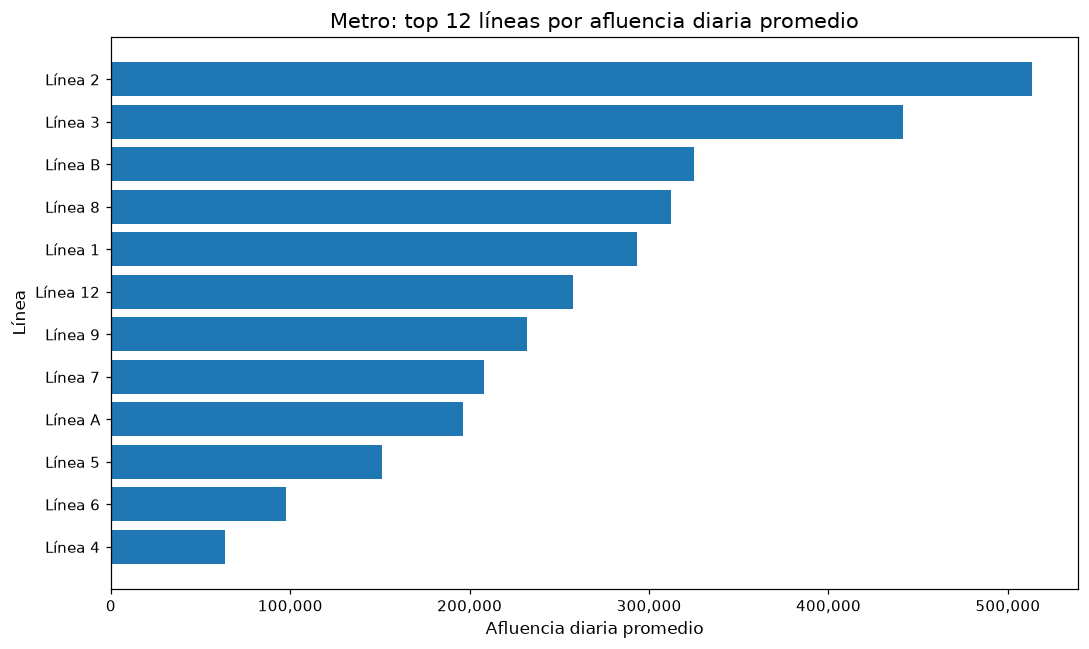

**Interpretación — Metro.** **Línea 2** registra la mayor afluencia diaria promedio: **513,397** pasajeros.  
**Relevancia.** Identifica corredores estratégicos por volumen de demanda.  
**Limitación.** El ranking no incorpora capacidad, longitud, número de estaciones ni kilómetros operados; por tanto, no mide eficiencia ni saturación.

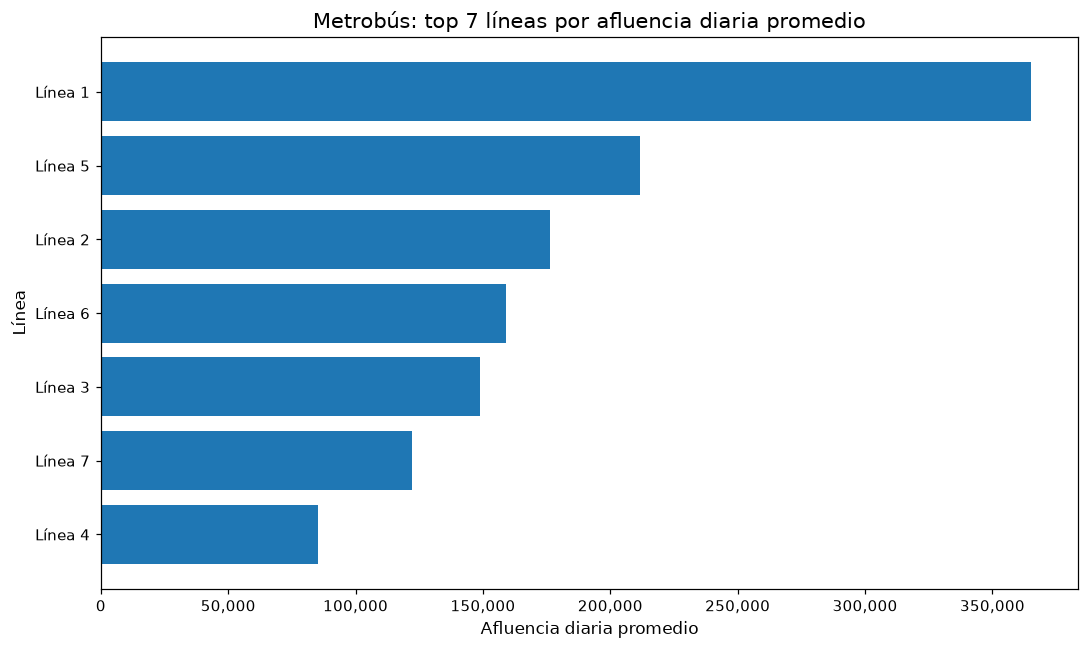

**Interpretación — Metrobús.** **Línea 1** registra la mayor afluencia diaria promedio: **365,323** pasajeros.  
**Relevancia.** Identifica corredores estratégicos por volumen de demanda.  
**Limitación.** El ranking no incorpora capacidad, longitud, número de estaciones ni kilómetros operados; por tanto, no mide eficiencia ni saturación.

In [82]:
def ranking_lineas(df, sistema, top=12):
    diario = df.groupby(['fecha', 'linea'], as_index=False)['afluencia'].sum()
    # Solo días con servicio (decisión D2): un cierre no es baja demanda
    diario = diario[diario['afluencia'] > 0]
    ranking = (diario.groupby('linea')['afluencia']
                     .agg(promedio='mean', mediana='median', dias='count')
                     .sort_values('promedio', ascending=True)
                     .tail(top))

    fig, ax = plt.subplots(figsize=(10, 6))
    ax.barh(ranking.index, ranking['promedio'])
    ax.set_title(f'{sistema}: top {min(top, len(ranking))} líneas por afluencia diaria promedio')
    ax.set_xlabel('Afluencia diaria promedio')
    ax.set_ylabel('Línea')
    ax.xaxis.set_major_formatter(mtick.StrMethodFormatter('{x:,.0f}'))
    plt.tight_layout()
    plt.show()

    lider = ranking['promedio'].idxmax()
    display(Markdown(
        f"**Interpretación — {sistema}.** **{lider}** registra la mayor afluencia diaria promedio: "
        f"**{ranking.loc[lider, 'promedio']:,.0f}** pasajeros.  \n"
        "**Relevancia.** Identifica corredores estratégicos por volumen de demanda.  \n"
        "**Limitación.** El ranking no incorpora capacidad, longitud, número de estaciones ni kilómetros operados; por tanto, no mide eficiencia ni saturación."
    ))
    return ranking.sort_values('promedio', ascending=False)

rank_metro = ranking_lineas(metro, 'Metro')
rank_mb = ranking_lineas(metrobus, 'Metrobús')


### Gráfica 10 · Evolución mensual comparable entre Metro y Metrobús
**¿Metro y Metrobús muestran patrones temporales semejantes en su afluencia?**

Como ambos sistemas operan en escalas muy diferentes, se construye un **índice base 100** durante el periodo común. La figura compara cambios relativos y no niveles absolutos de pasajeros.


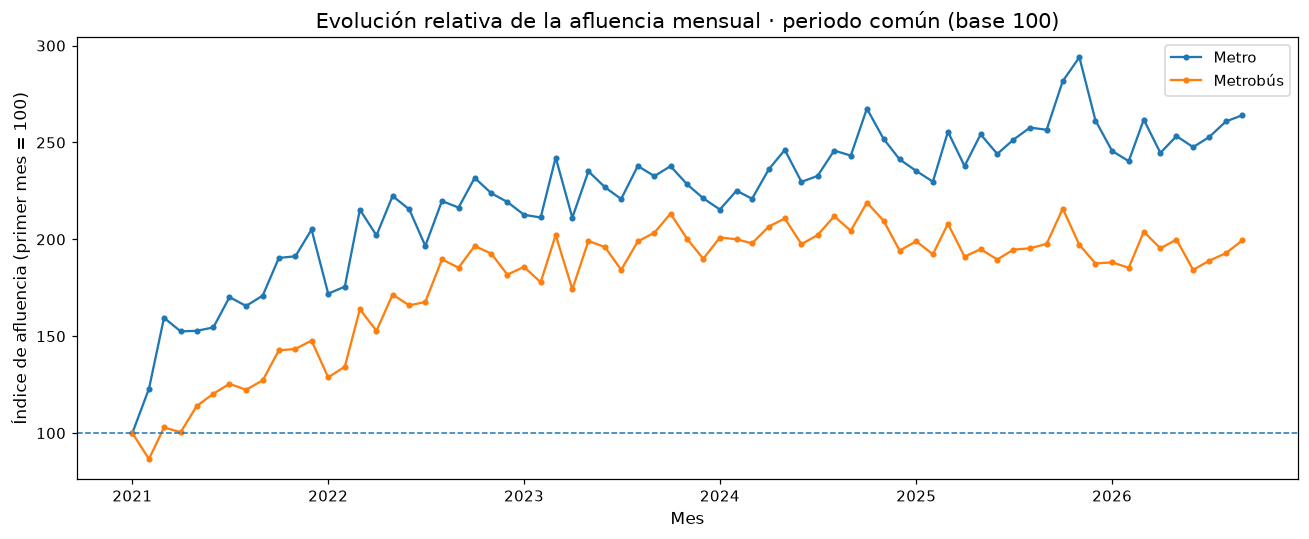

**Interpretación.** Entre **2021-01** y **2026-09**, Metro termina **+164.1%** respecto del primer mes y Metrobús **+99.5%**. La correlación mensual entre ambos volúmenes es **r = 0.912**.  
**Relevancia.** Permite detectar movimientos compartidos o divergencias entre sistemas en una escala comparable.  
**Limitación.** El índice oculta las diferencias absolutas de tamaño y la correlación no implica causalidad.

In [83]:
def serie_mensual(df, nombre):
    return (df.groupby('mes_calc', as_index=False)['afluencia'].sum()
              .rename(columns={'afluencia': nombre}))

metro_mes = serie_mensual(metro, 'Metro')
mb_mes = serie_mensual(metrobus, 'Metrobús')
comparacion = metro_mes.merge(mb_mes, on='mes_calc', how='inner').sort_values('mes_calc').dropna()

for col in ['Metro', 'Metrobús']:
    comparacion[f'{col}_indice'] = comparacion[col] / comparacion[col].iloc[0] * 100

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(comparacion['mes_calc'], comparacion['Metro_indice'], marker='o', markersize=3, label='Metro')
ax.plot(comparacion['mes_calc'], comparacion['Metrobús_indice'], marker='o', markersize=3, label='Metrobús')
ax.axhline(100, linewidth=1, linestyle='--')
ax.set_title('Evolución relativa de la afluencia mensual · periodo común (base 100)')
ax.set_xlabel('Mes')
ax.set_ylabel('Índice de afluencia (primer mes = 100)')
ax.legend()
plt.tight_layout()
plt.show()

corr_sistemas = comparacion[['Metro', 'Metrobús']].corr().iloc[0, 1]
delta_metro = comparacion['Metro_indice'].iloc[-1] - 100
delta_mb = comparacion['Metrobús_indice'].iloc[-1] - 100

display(Markdown(
    f"**Interpretación.** Entre **{comparacion['mes_calc'].min():%Y-%m}** y **{comparacion['mes_calc'].max():%Y-%m}**, "
    f"Metro termina **{delta_metro:+.1f}%** respecto del primer mes y Metrobús **{delta_mb:+.1f}%**. "
    f"La correlación mensual entre ambos volúmenes es **r = {corr_sistemas:.3f}**.  \n"
    "**Relevancia.** Permite detectar movimientos compartidos o divergencias entre sistemas en una escala comparable.  \n"
    "**Limitación.** El índice oculta las diferencias absolutas de tamaño y la correlación no implica causalidad."
))


### Gráfica 11 · Concentración de la afluencia por estación del Metro
**¿Qué tan concentrada está la demanda del Metro en sus estaciones con mayor afluencia?**

La visualización combina el volumen de las principales estaciones con su porcentaje acumulado sobre toda la afluencia observada.


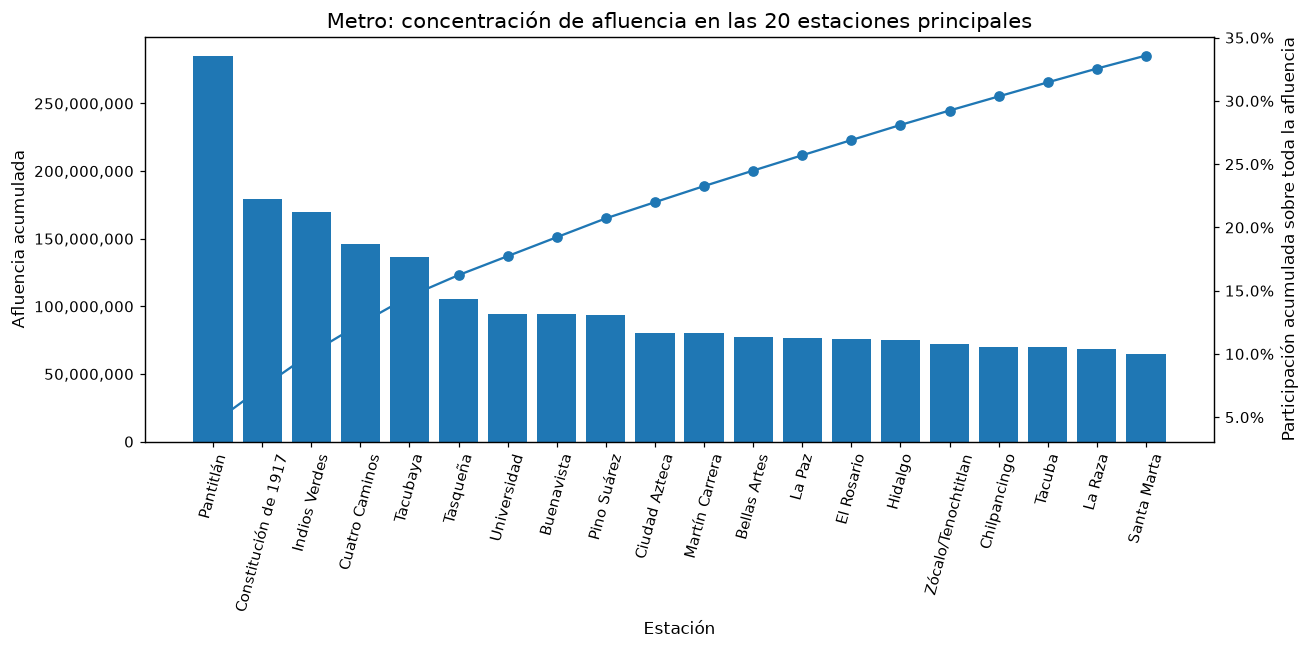

**Interpretación.** Las 20 estaciones con mayor volumen representan **33.6%** de la afluencia registrada. La estación líder es **Pantitlán**, con **284,750,916** accesos acumulados.  
**Relevancia.** La concentración ayuda a priorizar estaciones para análisis operativos y de capacidad.  
**Limitación.** Afluencia acumulada no equivale a saturación: faltan capacidad física, transbordos, accesos disponibles y oferta de trenes.

In [84]:
estaciones_metro = metro.groupby('estacion')['afluencia'].sum().sort_values(ascending=False)
pareto = estaciones_metro.head(20).to_frame('afluencia')
pareto['participacion'] = pareto['afluencia'] / estaciones_metro.sum()
pareto['acumulado'] = pareto['participacion'].cumsum()

fig, ax1 = plt.subplots(figsize=(12, 6))
ax1.bar(pareto.index, pareto['afluencia'])
ax1.set_title('Metro: concentración de afluencia en las 20 estaciones principales')
ax1.set_xlabel('Estación')
ax1.set_ylabel('Afluencia acumulada')
ax1.tick_params(axis='x', rotation=75)
ax1.yaxis.set_major_formatter(mtick.StrMethodFormatter('{x:,.0f}'))

ax2 = ax1.twinx()
ax2.plot(pareto.index, pareto['acumulado'], marker='o')
ax2.set_ylabel('Participación acumulada sobre toda la afluencia')
ax2.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax2.grid(False)
plt.tight_layout()
plt.show()

share20 = pareto['participacion'].sum()
lider_est = estaciones_metro.index[0]
display(Markdown(
    f"**Interpretación.** Las 20 estaciones con mayor volumen representan **{share20:.1%}** de la afluencia registrada. "
    f"La estación líder es **{lider_est}**, con **{estaciones_metro.iloc[0]:,.0f}** accesos acumulados.  \n"
    "**Relevancia.** La concentración ayuda a priorizar estaciones para análisis operativos y de capacidad.  \n"
    "**Limitación.** Afluencia acumulada no equivale a saturación: faltan capacidad física, transbordos, accesos disponibles y oferta de trenes."
))


---
### Gráfica 12 · ¿Cómo ha evolucionado el número de viajes de ECOBICI entre 2010 y 2024?

**Tipo:** línea temporal para identificar crecimiento, caídas y cambios de tendencia.


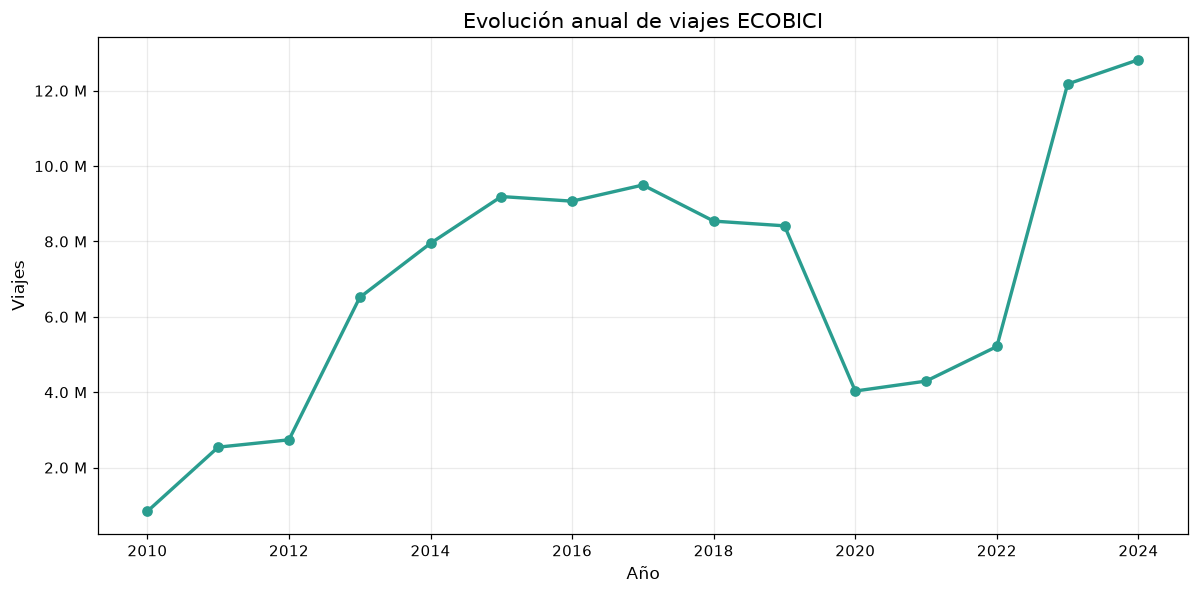

**Interpretación.** El mayor volumen anual observado se registra en **2024**, con **12.82 millones** de viajes. El último año observado es **2024**, con registros hasta **2024-07-31**; debe verificarse su cobertura antes de compararlo con años completos.  


In [89]:
viajes_anuales = diarios.assign(anio=diarios['fecha'].dt.year).groupby('anio', as_index=False)['viajes'].sum()
fig,ax=plt.subplots(); ax.plot(viajes_anuales.anio,viajes_anuales.viajes,marker='o',lw=2.2,color=COL['verde'])
ax.set(title='Evolución anual de viajes ECOBICI',xlabel='Año',ylabel='Viajes'); ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x,p:f'{x/1e6:.1f} M')); ax.grid(alpha=.25); plt.tight_layout(); plt.show()
r=viajes_anuales.loc[viajes_anuales.viajes.idxmax()]; fin=viajes_anuales.iloc[-1]
display(Markdown(f"""**Interpretación.** El mayor volumen anual observado se registra en **{int(r.anio)}**, con **{r.viajes/1e6:.2f} millones** de viajes. El último año observado es **{int(fin.anio)}**, con registros hasta **{diarios.fecha.max().date()}**; debe verificarse su cobertura antes de compararlo con años completos.  
"""))


---
### Gráfica 13 · ¿Cómo se distribuye la capacidad de estaciones entre alcaldías?

**Tipo:** barras de candados totales con número de estaciones.


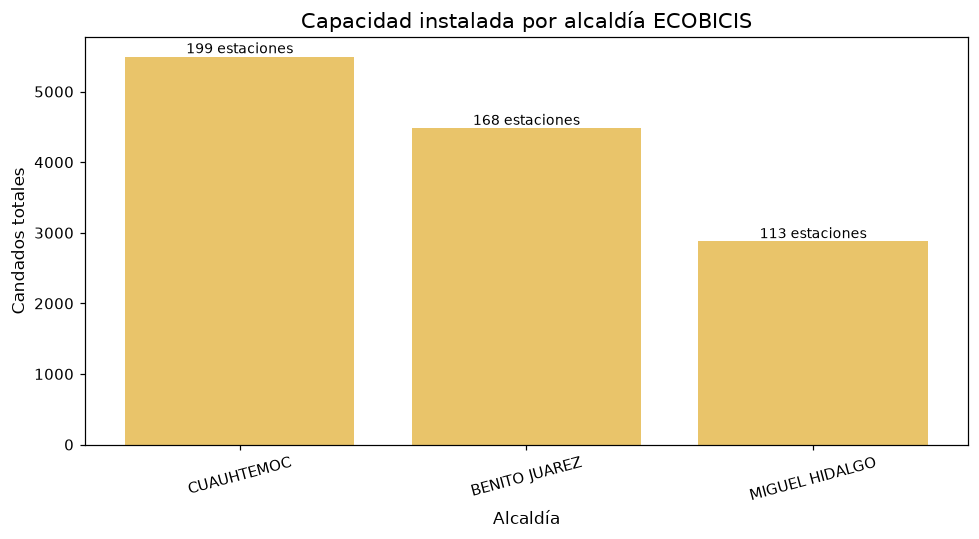

**Interpretación.** **CUAUHTEMOC** concentra la mayor capacidad del catálogo: **5,496 candados** en **199 estaciones**.  
**Relevancia.** La capacidad física condiciona retiros y arribos potenciales.  
**Limitación.** El catálogo contiene 480 estaciones en 3 alcaldías, mientras el archivo 2026 observa más códigos; la cobertura geográfica no es completa para toda la red 2026.

In [85]:
infra=estaciones.groupby('alcaldia',as_index=False).agg(estaciones=('num_cicloestacion','count'),candados=('candados','sum'),candados_promedio=('candados','mean')).sort_values('candados',ascending=False)
fig,ax=plt.subplots(figsize=(9,5)); bars=ax.bar(infra.alcaldia,infra.candados,color=COL['amarillo']); ax.set(title='Capacidad instalada por alcaldía ECOBICIS',xlabel='Alcaldía',ylabel='Candados totales'); ax.tick_params(axis='x',rotation=15)
for b,n in zip(bars,infra.estaciones): ax.text(b.get_x()+b.get_width()/2,b.get_height(),f'{n} estaciones',ha='center',va='bottom',fontsize=9)
plt.tight_layout(); plt.show(); r=infra.iloc[0]
display(Markdown(f"""**Interpretación.** **{r.alcaldia}** concentra la mayor capacidad del catálogo: **{int(r.candados):,} candados** en **{int(r.estaciones)} estaciones**.  
**Relevancia.** La capacidad física condiciona retiros y arribos potenciales.  
**Limitación.** El catálogo contiene {len(estaciones)} estaciones en {estaciones.alcaldia.nunique()} alcaldías, mientras el archivo 2026 observa más códigos; la cobertura geográfica no es completa para toda la red 2026."""))


---
### Gráfica 14 · ¿Qué estaciones presentan mayor desequilibrio entre arribos y retiros?

**Tipo:** barras divergentes del balance `arribos − retiros`.


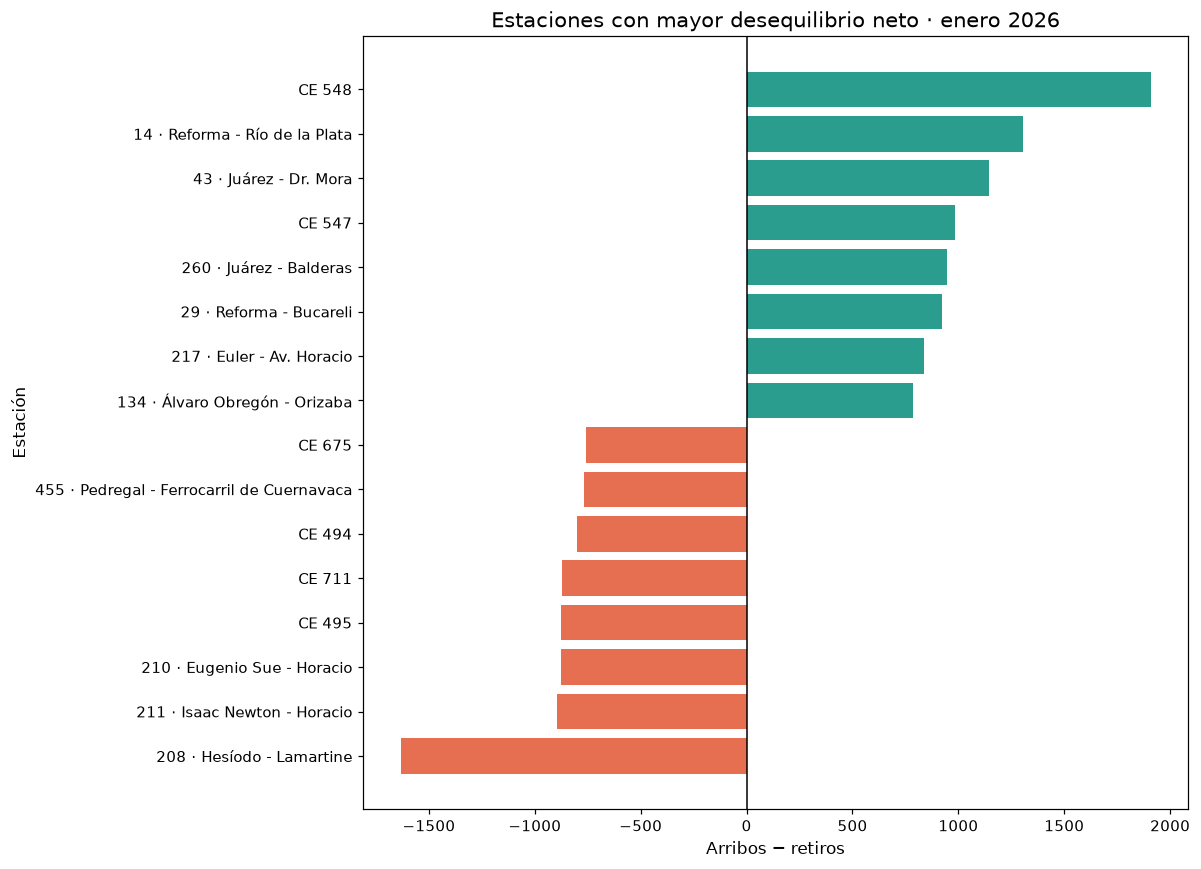

**Interpretación.** Mayor saldo positivo: **CE 548** (+1,907); mayor saldo negativo: **208 · Hesíodo - Lamartine** (-1,634).  
**Relevancia.** Aproxima la presión de redistribución de bicicletas.  
**Limitación.** Es un balance mensual; no indica la hora del desbalance ni movimientos logísticos del operador.

In [86]:
sal=detalle.groupby('origen_id').size().rename('retiros'); ent=detalle.groupby('destino_id').size().rename('arribos'); bal=pd.concat([sal,ent],axis=1).fillna(0); bal['neto']=bal.arribos-bal.retiros; bal=bal.reset_index().rename(columns={'index':'estacion_id'}); bal['nombre']=bal.estacion_id.map(nombre_map); bal['etiqueta']=np.where(bal.nombre.notna(),bal.estacion_id+' · '+bal.nombre.astype(str),'CE '+bal.estacion_id.astype(str)); ex=pd.concat([bal.nsmallest(8,'neto'),bal.nlargest(8,'neto')]).drop_duplicates('estacion_id').sort_values('neto')
fig,ax=plt.subplots(figsize=(11,8)); colors=[COL['rojo'] if x<0 else COL['verde'] for x in ex.neto]; ax.barh(ex.etiqueta,ex.neto,color=colors); ax.axvline(0,color='black',lw=1); ax.set(title='Estaciones con mayor desequilibrio neto · enero 2026',xlabel='Arribos − retiros',ylabel='Estación'); plt.tight_layout(); plt.show(); pos=bal.loc[bal.neto.idxmax()]; neg=bal.loc[bal.neto.idxmin()]
display(Markdown(f"""**Interpretación.** Mayor saldo positivo: **{pos.etiqueta}** (+{int(pos.neto):,}); mayor saldo negativo: **{neg.etiqueta}** ({int(neg.neto):,}).  
**Relevancia.** Aproxima la presión de redistribución de bicicletas.  
**Limitación.** Es un balance mensual; no indica la hora del desbalance ni movimientos logísticos del operador."""))


# 5. Interpretación y conclusiones


### P1 · Tipo de pago en el Metro y el Metrobús

> **Pregunta.** ¿Cómo se distribuye la afluencia del Metro y del Metrobús por tipo de pago (boleto, prepago y gratuidad), y cómo cambia esa distribución entre líneas, entre días laborales y fines de semana, y a lo largo del tiempo (2021–2026)?


- **El prepago domina y el boleto desapareció.** En el Metro, el boleto pasó de alrededor del 30 % de los accesos en 2021 a prácticamente 0 % desde 2024, y el prepago subió de cerca del 61 % al 87 %. En el Metrobús, que no tiene boleto, el prepago representa más del 90 % todos los años.
- **La gratuidad es estable y mayor en el Metro.** Representa alrededor del 12 % de los accesos del Metro (con un ligero aumento de 9 % en 2021 a 13 % en 2025–2026) y alrededor del 6.5 % en el Metrobús.
- **Hay diferencias entre líneas, no entre tipos de día.** En el Metro, la gratuidad va de cerca del 9 % (Línea 9) al 16 % (Línea 4); en el Metrobús, del 2 % (Línea 7) al 10 % (Línea 3). Entre días laborales y fines de semana la diferencia es menor a un punto porcentual.

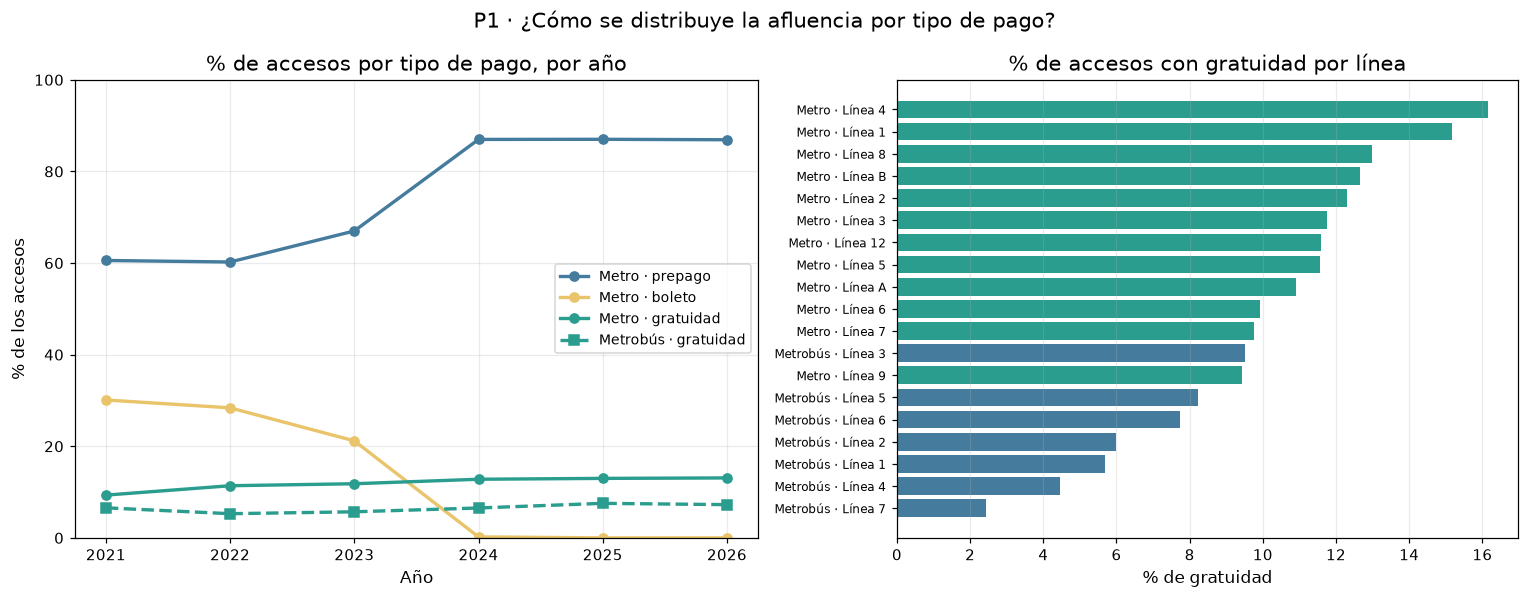

In [87]:
# Síntesis P1: evolución de la composición por tipo de pago y gratuidad por línea
comp = (sistemas_dia.assign(anio=sistemas_dia["fecha"].dt.year)
        .groupby(["sistema", "anio"])[["boleto", "prepago", "gratuidad"]].sum())
comp = comp.div(comp.sum(axis=1), axis=0) * 100

lineas_grat = pd.concat([
    pct_gratuidad_linea(metro_linea_dia[metro_linea_dia["linea_abierta"]]).rename(lambda l: f"Metro · {l}"),
    pct_gratuidad_linea(metrobus_linea_dia).rename(lambda l: f"Metrobús · {l}"),
]).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [1.1, 1]})
ax = axes[0]
m, mb = comp.xs("Metro"), comp.xs("Metrobús")
ax.plot(m.index, m["prepago"], marker="o", lw=2.2, color=COL["azul"], label="Metro · prepago")
ax.plot(m.index, m["boleto"], marker="o", lw=2.2, color=COL["amarillo"], label="Metro · boleto")
ax.plot(m.index, m["gratuidad"], marker="o", lw=2.2, color=COL["verde"], label="Metro · gratuidad")
ax.plot(mb.index, mb["gratuidad"], marker="s", lw=2.2, ls="--", color=COL["verde"], label="Metrobús · gratuidad")
ax.set(title="% de accesos por tipo de pago, por año", xlabel="Año", ylabel="% de los accesos", ylim=(0, 100))
ax.legend(loc="center right", fontsize=9); ax.grid(alpha=.25)

ax = axes[1]
colores = [COL["verde"] if l.startswith("Metro ·") else COL["azul"] for l in lineas_grat.index]
ax.barh(lineas_grat.index, lineas_grat.values, color=colores)
ax.set(title="% de accesos con gratuidad por línea", xlabel="% de gratuidad"); ax.tick_params(axis="y", labelsize=8)
ax.grid(axis="x", alpha=.25)
fig.suptitle("P1 · ¿Cómo se distribuye la afluencia por tipo de pago?", fontsize=14)
plt.tight_layout(); plt.show()


### P2 · Ecobici en enero de 2026

> **Pregunta.** ¿Qué patrones de uso presenta Ecobici en enero de 2026 según género, edad y hora del día, y cómo se comparan con el histórico 2010–2024?

- **La mayoría de los viajes los hacen hombres de 25 a 44 años.** Los hombres hacen cerca del 68 % de los viajes y las mujeres el 27 %; el rango de 25 a 34 años concentra casi la mitad de los viajes.
- **La brecha de género crece con la edad:** las mujeres hacen el 29 % de los viajes entre los usuarios de 16 a 24 años, pero solo el 15 % entre los de 65 años o más.
- **El uso sigue un patrón de traslado al trabajo.** En días laborales hay dos picos, a las 8:00 y a las 18:00; en fines de semana el máximo se mueve a mediodía. Hombres y mujeres tienen el mismo perfil horario y una duración típica similar (alrededor de 12 minutos).
- **Frente al histórico,** la composición por género es muy parecida: en 2024 el 69 % de los viajes fueron de hombres, contra 67.5 % en enero de 2026, por lo que el mes analizado no parece atípico en ese sentido.

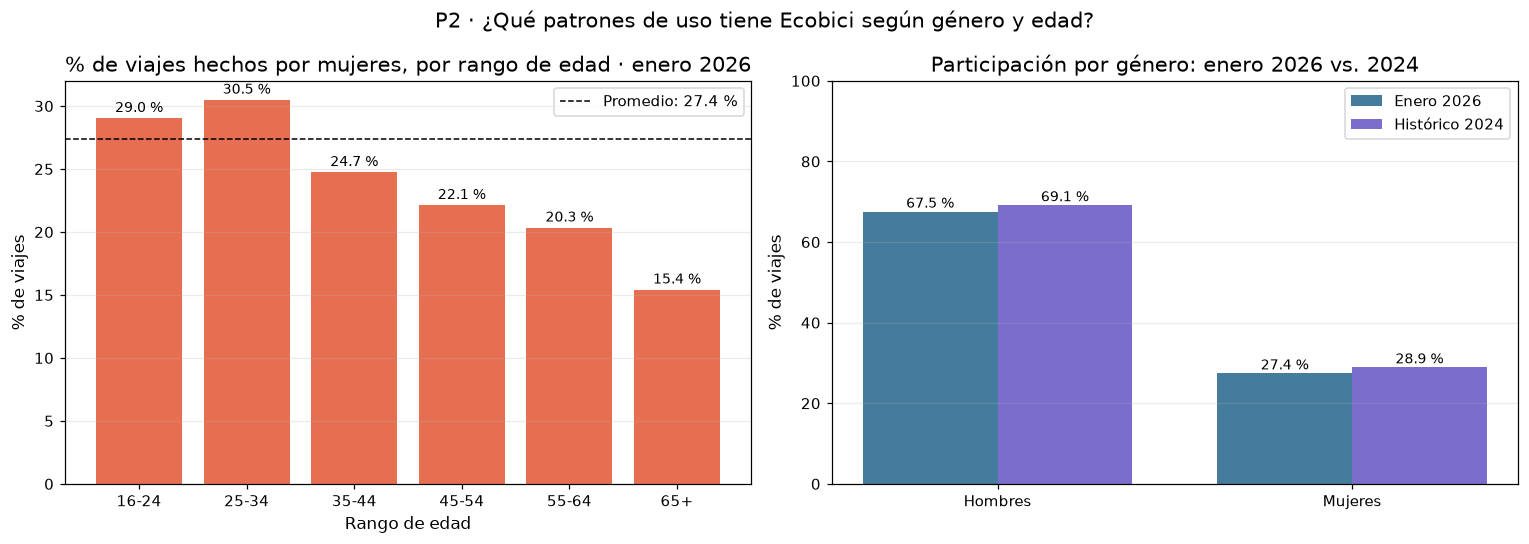

In [88]:
# Síntesis P2: brecha de género por edad y comparación enero 2026 vs. histórico 2024
ge2 = (ecobici_validos[ecobici_validos["rango_edad"] != "Sin edad"]
       .groupby("rango_edad")["genero"].value_counts(normalize=True).unstack(fill_value=0) * 100)

ene = ecobici_validos["genero"].value_counts(normalize=True) * 100
h24 = diarios[diarios["fecha"].dt.year.eq(2024)].groupby("genero")["viajes"].sum()
h24 = h24 / h24.sum() * 100
comparar = pd.DataFrame({
    "Enero 2026": [ene.get("Masculino", 0), ene.get("Femenino", 0)],
    "Histórico 2024": [h24.get("Hombre", 0), h24.get("Mujer", 0)],
}, index=["Hombres", "Mujeres"])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ax = axes[0]
ax.bar(ge2.index, ge2["Femenino"], color=COL["rojo"])
ax.axhline(ene.get("Femenino", 0), color="black", ls="--", lw=1, label=f"Promedio: {ene.get('Femenino', 0):.1f} %")
for x, y in zip(ge2.index, ge2["Femenino"]):
    ax.text(x, y + .5, f"{y:.1f} %", ha="center", fontsize=9)
ax.set(title="% de viajes hechos por mujeres, por rango de edad · enero 2026", xlabel="Rango de edad", ylabel="% de viajes")
ax.legend(); ax.grid(axis="y", alpha=.25)

ax = axes[1]
x = np.arange(len(comparar.index)); w = .38
ax.bar(x - w/2, comparar["Enero 2026"], w, color=COL["azul"], label="Enero 2026")
ax.bar(x + w/2, comparar["Histórico 2024"], w, color=COL["morado"], label="Histórico 2024")
for i, (a, b) in enumerate(comparar.values):
    ax.text(i - w/2, a + 1, f"{a:.1f} %", ha="center", fontsize=9); ax.text(i + w/2, b + 1, f"{b:.1f} %", ha="center", fontsize=9)
ax.set_xticks(x, comparar.index); ax.set(title="Participación por género: enero 2026 vs. 2024", ylabel="% de viajes", ylim=(0, 100))
ax.legend(); ax.grid(axis="y", alpha=.25)
fig.suptitle("P2 · ¿Qué patrones de uso tiene Ecobici según género y edad?", fontsize=14)
plt.tight_layout(); plt.show()



### P3 · Ingresos y afluencia del Metro

> **Pregunta.** ¿Cómo se relacionan los ingresos del Metro con su afluencia mensual en el periodo en que ambas bases coinciden (enero 2021 – julio 2023)?

- Entre enero de 2021 y julio de 2023, el ingreso mensual y la afluencia tienen una correlación de **r ≈ 0.99 (Pearson)** y **ρ ≈ 0.97 (Spearman)**.
- El ingreso por acceso pagado se mantiene entre 5.0 y 5.4 pesos, prácticamente la tarifa de 5 pesos. Esto confirma que las dos bases son consistentes y que los ingresos dependen casi por completo del número de accesos de pago.
- Por cada millón de accesos adicionales, el ingreso mensual sube en promedio 4.32 millones de pesos, cercano a la tarifa de 5 pesos menos la proporción de accesos gratuitos.

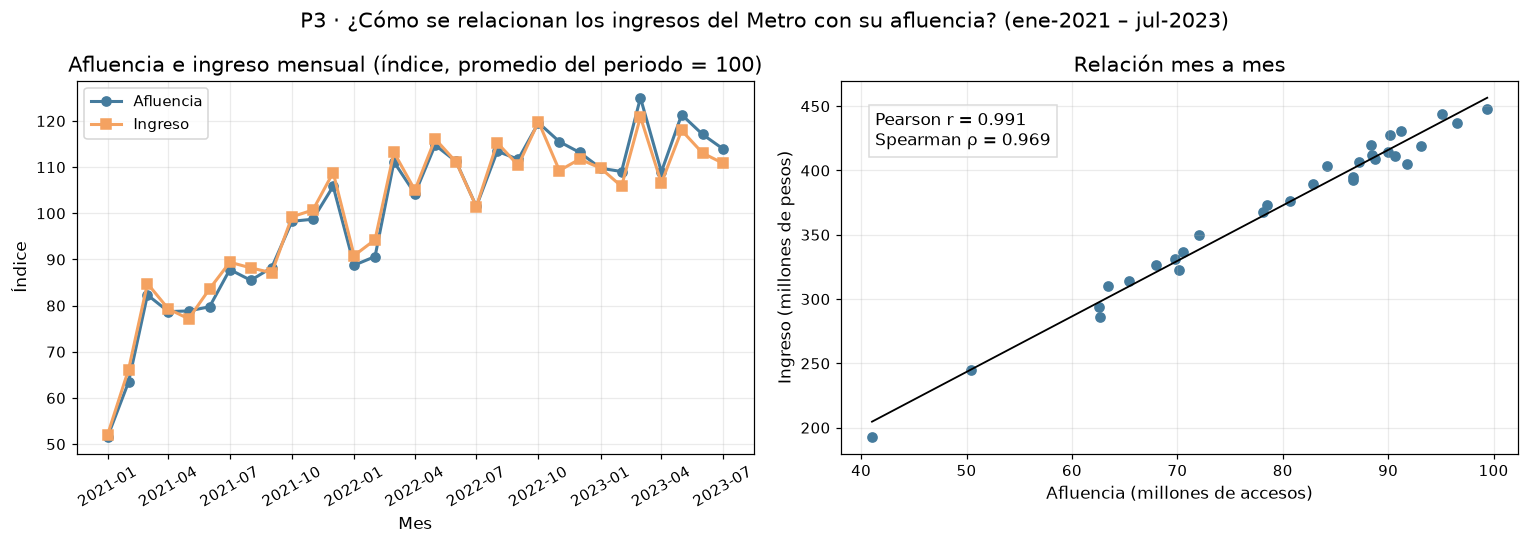

In [89]:
# Síntesis P3: afluencia e ingreso del Metro como índices (promedio = 100)
sint = comun.set_index("mes_calc")[["afluencia_metro", "ingreso_total"]]
indices = sint / sint.mean() * 100
r_p = sint.corr(method="pearson").iloc[0, 1]
r_s = sint.corr(method="spearman").iloc[0, 1]
pend, inter = np.polyfit(sint["afluencia_metro"] / 1e6, sint["ingreso_total"] / 1e6, 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ax = axes[0]
ax.plot(indices.index, indices["afluencia_metro"], marker="o", lw=2, color=COL["azul"], label="Afluencia")
ax.plot(indices.index, indices["ingreso_total"], marker="s", lw=2, color=COL["naranja"], label="Ingreso")
ax.set(title="Afluencia e ingreso mensual (índice, promedio del periodo = 100)", xlabel="Mes", ylabel="Índice")
ax.tick_params(axis="x", rotation=30); ax.legend(); ax.grid(alpha=.25)

ax = axes[1]
xs = sint["afluencia_metro"] / 1e6
ax.scatter(xs, sint["ingreso_total"] / 1e6, color=COL["azul"])
xx = np.linspace(xs.min(), xs.max(), 50)
ax.plot(xx, pend * xx + inter, color="black", lw=1.2)
ax.text(.05, .92, f"Pearson r = {r_p:.3f}\nSpearman ρ = {r_s:.3f}", transform=ax.transAxes, fontsize=11, va="top",
        bbox=dict(facecolor="white", alpha=.8, edgecolor="lightgray"))
ax.set(title="Relación mes a mes", xlabel="Afluencia (millones de accesos)", ylabel="Ingreso (millones de pesos)")
ax.grid(alpha=.25)
fig.suptitle("P3 · ¿Cómo se relacionan los ingresos del Metro con su afluencia? (ene-2021 – jul-2023)", fontsize=14)
plt.tight_layout(); plt.show()



### Lo que los datos permiten y no permiten concluir

- Nos permiten describir cómo se distribuyen los accesos por tipo de pago, línea, día y hora, y quién usa Ecobici según su registro.
- No nos permiten afirmar por qué ocurren estos patrones. Por ejemplo, el aumento del prepago coincide con la eliminación del boleto, pero los datos no prueban que esa sea la causa; tampoco explican por qué hay menos mujeres usando Ecobici (seguridad, infraestructura, motivos de viaje u otros factores).
- La correlación de P3 no implica causalidad; con una tarifa fija, el ingreso es casi por construcción proporcional a los accesos de pago.
- Las afluencias cuentan accesos, no personas ni viajes completos, y Ecobici cuenta viajes, no usuarios: una persona frecuente pesa más.


### Limitaciones y trabajo futuro

- Los datos de ingresos solo llegan a julio de 2023, lo que limita P3 a 31 meses; el detalle de viajes de Ecobici es de un solo mes.
- Los cierres (Línea 12, incendio de 2021, obras de la Línea 1) y el error de febrero de 2025 se trataron explícitamente (D2 y D5), pero otros eventos (festivos, marchas, lluvias) no están identificados.
- Como siguiente paso se podrían incorporar datos de origen–destino, tarifas y población por alcaldía, y analizar varios meses de viajes individuales de Ecobici para estudiar estacionalidad por género y edad.